# **Section 0: Environment Setup and Importing Libraries**

In [8]:
# -*- coding: utf-8 -*-
"""
Clinical Classification Pipeline for Dengue Hospitalization (SIVIGILA)
Core Module: Environment Setup, Preprocessing, Modeling, and Visualization
"""

import os
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight
import time
from scipy.cluster import hierarchy
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Global style and reproducibility configuration
sns.set_theme(style="whitegrid")
SEED = 666
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Optional override for custom paths (e.g., Google Drive in Colab).
# Leave empty ("") for automatic repository-relative detection.
CUSTOM_DATA_DIR = "/content/drive/MyDrive/Curso de Inteligencia Artificial 2026-II/Notas/Proyecto/Proyecto Dengue/Entrega 3/Dataset"  # @param {type:"string"}


def resolve_data_directory(custom_path: str = "") -> Path:
    """
    Resolve the dataset directory portably across local machines,
    cloned GitHub repositories, and Google Colab.
    """
    env_override = os.getenv("DENGUE_DATA_DIR", "")
    selected_path = (custom_path or env_override).strip().strip('"\'')

    if selected_path:
        # Mount Google Drive only if a Drive path is explicitly provided
        if selected_path.startswith("/content/drive") and not Path("/content/drive/MyDrive").exists():
            from google.colab import drive
            drive.mount("/content/drive")

        resolved = Path(selected_path).expanduser().resolve()
        if resolved.exists():
            return resolved
        raise FileNotFoundError(f"Specified data directory does not exist: {resolved}")

    candidate_dirs = [
        Path("./data"),
        Path("../data"),
        Path("."),
        Path("/content/data"),
        Path("/content"),
    ]

    for candidate in candidate_dirs:
        if (candidate / "Dataset_Registros_Dengue_2025.csv").exists():
            return candidate.resolve()

    raise FileNotFoundError(
        "Dataset files not found. Place the CSV files inside './data/' at the "
        "repository root, or set their path in 'CUSTOM_DATA_DIR'."
    )


DATA_DIR = resolve_data_directory(CUSTOM_DATA_DIR)
print(f"Resolved data directory: {DATA_DIR}")

Resolved data directory: /content/drive/MyDrive/Curso de Inteligencia Artificial 2026-II/Notas/Proyecto/Proyecto Dengue/Entrega 3/Dataset


# **Section 1: Data Cleaning, Feature Engineering, and Auditing**

In [9]:
# ==============================================================================
# 1. PREPROCESSING, FEATURE ENGINEERING & SCHEMA AUDITING
# ==============================================================================

def standardize_dates(series: pd.Series) -> pd.Series:
    """Normalize DD/MM/YYYY date strings into pandas datetime objects."""
    text = series.astype(str).str.strip()
    clean_dates = text.str.split().str[0].str.replace('-', '/', regex=False)
    return pd.to_datetime(clean_dates, format='%d/%m/%Y', errors='coerce')


def clean_dengue_features(raw_data: pd.DataFrame) -> pd.DataFrame:
    """
    Clean and transform annual SIVIGILA epidemiological records (2022-2025).
    Computes continuous age (AGE_YEARS), symptom onset delay (DELTA_T),
    binarizes vulnerability groups, and applies One-Hot Encoding.
    """
    df = raw_data.copy()

    # 1. Drop administrative and redundant identifiers
    cols_to_drop = [
        "CONSECUTIVE", "COD_EVE", "COD_PRE", "COD_SUB", "COD_ASE", "GRU_POB",
        "nom_grupo", "sem_ges", "fuente", "FEC_HOS", "CON_FIN", "FEC_DEF",
        "AJUSTE", "FECHA_NTO", "CBMTE", "FEC_ARC_XL", "FEC_AJU", "FM_FUERZA",
        "FM_UNIDAD", "FM_GRADO", "confirmados", "va_sispro", "Estado_final_de_caso",
        "nom_est_f_caso", "Nombre_upgd", "Nombre_evento", "Pais_ocurrencia",
        "Municipio_ocurrencia", "Pais_residencia", "Departamento_residencia",
        "Municipio_residencia", "Departamento_Notificacion", "Municipio_notificacion",
        "ANO", "FEC_NOT", "OCUPACION", "COD_PAIS_R", "COD_DPTO_R", "COD_MUN_R",
        "COD_PAIS_O", "COD_DPTO_O", "COD_MUN_O", "COD_DPTO_N", "COD_MUN_N", "TIP_CAS"
    ]
    existing_cols = [c for c in cols_to_drop if c in df.columns]
    df.drop(columns=existing_cols, inplace=True)

    # 2. Unified continuous age in years (AGE_YEARS)
    age_conditions = [df['UNI_MED'] == 1, df['UNI_MED'] == 2, df['UNI_MED'] == 3]
    age_values = [df['EDAD'].astype(float), df['EDAD'] / 12.0, df['EDAD'] / 365.0]
    df['AGE_YEARS'] = np.select(age_conditions, age_values, default=np.nan)
    df.drop(columns=['UNI_MED', 'EDAD'], inplace=True)

    # 3. Symptom evolution time in days (DELTA_T)
    consult_date = standardize_dates(df['FEC_CON'])
    onset_date = standardize_dates(df['INI_SIN'])
    df['DELTA_T'] = (consult_date - onset_date).dt.days
    df.drop(columns=['FEC_CON', 'INI_SIN'], inplace=True)

    # 4. Binary encodings (Target, Population Groups, Sex, and Ethnicity)
    df['PAC_HOS'] = (df['PAC_HOS'] == 1).astype('int8')

    pop_groups = [
        'GP_DISCAPA', 'GP_DESPLAZ', 'GP_MIGRANT', 'GP_CARCELA', 'GP_GESTAN',
        'GP_INDIGEN', 'GP_POBICFB', 'GP_MAD_COM', 'GP_DESMOVI', 'GP_PSIQUIA',
        'GP_VIC_VIO', 'GP_OTROS'
    ]
    present_groups = [g for g in pop_groups if g in df.columns]
    df[present_groups] = df[present_groups].replace({2: 0}).fillna(0).astype('int8')

    df['SEX_MALE'] = (df['SEXO'] == 'M').astype('int8')
    df.drop(columns=['SEXO'], inplace=True)

    df['ETHNIC_MINORITY'] = df['PER_ETN'].isin([1, 2, 3, 4, 5]).astype('int8')
    df.drop(columns=['PER_ETN'], inplace=True)

    # 5. Standardize categorical domains
    area_map = {1: 'URBAN_CORE', 2: 'POPULATED_CENTER', 3: 'RURAL_DISPERSED'}
    df['AREA'] = df['AREA'].map(area_map).fillna('UNKNOWN')

    regime_map = {
        'C': 'CONTRIBUTORY', 'S': 'SUBSIDIZED', 'P': 'EXCEPTION',
        'E': 'SPECIAL', 'N': 'UNINSURED', 'I': 'UNDETERMINED'
    }
    df['TIP_SS'] = df['TIP_SS'].map(regime_map).fillna('UNDETERMINED')

    df['estrato'] = (
        df['estrato']
        .astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r'\.0$', '', regex=True)
        .replace({
            'NAN': 'NO_DATA',
            'NONE': 'NO_DATA',
            '': 'NO_DATA',
            'SIN DATO': 'NO_DATA',
        })
    )

    # 6. One-Hot Encoding
    df = pd.get_dummies(
        df,
        columns=['AREA', 'TIP_SS', 'estrato'],
        prefix=['AREA', 'REGIME', 'STRATUM'],
        prefix_sep='_',
        drop_first=False,
        dtype='int8'
    )

    # 7. Memory optimization and temporal consistency filtering
    continuous_cols = ['AGE_YEARS', 'DELTA_T', 'Departamento_ocurrencia', 'SEMANA']
    binary_cols = [c for c in df.columns if c not in continuous_cols]
    df[binary_cols] = df[binary_cols].astype('int8')

    df = df.dropna(subset=['AGE_YEARS', 'DELTA_T'])
    df = df[df['DELTA_T'] >= 0].reset_index(drop=True)
    df['DELTA_T'] = df['DELTA_T'].astype('int64')

    return df


def clean_symptom_features(raw_data: pd.DataFrame) -> pd.DataFrame:
    """
    Clean and transform the clinical SIVIGILA dataset containing symptoms and warning signs.
    """
    df = raw_data.copy()

    # 1. Binarize symptoms and clinical warning signs
    symptom_cols = [
        "fiebre", "cefalea", "dolrretroo", "malgias", "artralgia", "erupcionr",
        "dolor_abdo", "vomito", "somnolenci", "hipotensio", "hepatomeg",
        "hem_mucosa", "hipotermia", "aum_hemato", "caida_plaq", "acum_liquievento"
    ]
    for symptom in symptom_cols:
        if symptom in df.columns:
            clean_text = df[symptom].astype(str).str.strip().replace("nan", "0")
            df[symptom] = (clean_text == "1").astype("int8")

    # 2. Target variable (PAC_HOS)
    hos_text = df["pac_hos_"].astype(str).str.strip().replace("nan", "0")
    df["PAC_HOS"] = (hos_text == "1").astype("int8")

    # 3. Unified continuous age in years (AGE_YEARS)
    age_unit = pd.to_numeric(df["uni_med_"], errors="coerce").fillna(1)
    age_conditions = [age_unit == 1, age_unit == 2, age_unit == 3]
    age_values = [
        df["edad_"].astype(float),
        df["edad_"] / 12.0,
        df["edad_"] / 365.0
    ]
    df["AGE_YEARS"] = np.select(age_conditions, age_values, default=np.nan)

    # 4. Symptom onset delay (DELTA_T) and consistency filtering
    consult_dt = pd.to_datetime(df["fec_con_"], errors="coerce", dayfirst=True)
    onset_dt = pd.to_datetime(df["ini_sin_"], errors="coerce", dayfirst=True)
    df["DELTA_T"] = (consult_dt - onset_dt).dt.days
    df = df.dropna(subset=["AGE_YEARS", "DELTA_T"])
    df = df[df["DELTA_T"] >= 0].reset_index(drop=True)

    # 5. Demographic binary encodings
    df["SEX_MALE"] = (df["sexo_"].astype(str).str.strip().str.upper() == "M").astype("int8")

    if "desplazami" in df.columns:
        disp_text = df["desplazami"].astype(str).str.strip().replace("nan", "0")
        df["GP_DESPLAZ"] = (disp_text == "1").astype("int8")

    # 6. Drop administrative and redundant columns
    cols_to_drop = [
        "id", "nombre_barrio", "comuna", "clas_dengue", "cod_ase_", "tip_cas_",
        "cod_dpto_r", "cod_mpio_r", "cod_dpto_o", "cod_mpio_o", "cod_mun_d",
        "evento", "year_", "fec_con_", "ini_sin_", "edad_", "uni_med_",
        "sexo_", "pac_hos_", "desplazami"
    ]
    existing_cols = [c for c in cols_to_drop if c in df.columns]
    df.drop(columns=existing_cols, inplace=True)

    # 7. One-Hot Encoding for health insurance regime
    if "tipo_ss_" in df.columns:
        df["tipo_ss_"] = df["tipo_ss_"].astype(str).str.strip().str.upper()
        regime_map = {
            "C": "CONTRIBUTORY", "S": "SUBSIDIZED", "P": "EXCEPTION",
            "E": "SPECIAL", "N": "UNINSURED", "I": "UNDETERMINED"
        }
        df["tipo_ss_"] = df["tipo_ss_"].replace(regime_map)
        df = pd.get_dummies(
            df,
            columns=["tipo_ss_"],
            prefix=["REGIME"],
            prefix_sep="_",
            drop_first=False,
            dtype="int8"
        )

    # 8. Optimize memory dtypes
    continuous_cols = ["AGE_YEARS", "DELTA_T", "semana"]
    binary_cols = [c for c in df.columns if c not in continuous_cols]
    df[binary_cols] = df[binary_cols].astype("int8")
    df["DELTA_T"] = df["DELTA_T"].astype("int64")

    return df


def audit_dataset_consistency(
    datasets: dict[str, pd.DataFrame],
    reference_key: str = '2025',
    target_col: str = 'PAC_HOS',
) -> bool:
    """
    Audit missing values, dimensional schema alignment, and target prevalence across years.
    """
    if reference_key not in datasets:
        raise KeyError(
            f"Reference key '{reference_key}' not found in datasets: {list(datasets.keys())}"
        )

    df_ref = datasets[reference_key]
    ref_cols = list(df_ref.columns)
    ref_set = set(ref_cols)
    is_globally_valid = True

    print("=" * 72)
    print("1. MISSING VALUES & RECORD COUNT AUDIT")
    print("=" * 72)

    null_report = []
    for year, df in datasets.items():
        total_nulls = int(df.isna().sum().sum())
        null_cols = df.columns[df.isna().any()].tolist()
        if total_nulls > 0:
            is_globally_valid = False

        null_report.append({
            'Year': year,
            'Total Records': f"{len(df):,}",
            'Total Nulls': total_nulls,
            'Columns with Nulls': ", ".join(null_cols) if null_cols else "0 (Clean)",
        })
    print(pd.DataFrame(null_report).set_index('Year').to_string())

    print("\n" + "=" * 72)
    print(f"2. STRUCTURAL SCHEMA ALIGNMENT VS. REFERENCE ({reference_key})")
    print("=" * 72)
    print(f"• Canonical feature count expected: {len(ref_cols)}")

    schema_report = []
    for year, df in datasets.items():
        curr_cols = list(df.columns)
        curr_set = set(curr_cols)
        missing = ref_set - curr_set
        extra = curr_set - ref_set
        same_order = curr_cols == ref_cols
        same_cols = len(missing) == 0 and len(extra) == 0

        if not same_cols or not same_order:
            is_globally_valid = False

        status = "Optimal"
        if not same_cols:
            status = f"Mismatch (-{len(missing)}, +{len(extra)})"
        elif not same_order:
            status = "Unordered (Reindex required)"

        schema_report.append({
            'Year': year,
            'Num Columns': len(curr_cols),
            'Same Columns': "YES" if same_cols else "NO",
            'Identical Order': "YES" if same_order else "NO",
            'Status': status,
        })
        if missing:
            print(f"  [ERROR] [{year}] Missing columns: {sorted(missing)}")
        if extra:
            print(f"  [ERROR] [{year}] Extra columns: {sorted(extra)}")

    print(pd.DataFrame(schema_report).set_index('Year').to_string())

    print("\n" + "=" * 72)
    print(f"3. EPIDEMIOLOGICAL TARGET DISTRIBUTION ({target_col})")
    print("=" * 72)

    target_report = []
    for year, df in datasets.items():
        if target_col not in df.columns:
            target_report.append({
                'Year': year,
                'Outpatient (0)': "N/A",
                'Hospitalized (1)': "N/A",
                'Hospitalization Rate (%)': "N/A",
            })
            is_globally_valid = False
            continue

        counts = df[target_col].value_counts()
        total = len(df)
        n_out = counts.get(0, 0)
        n_hos = counts.get(1, 0)
        pct_hos = (n_hos / total) * 100 if total > 0 else 0.0

        target_report.append({
            'Year': year,
            'Outpatient (0)': f"{n_out:,} ({((n_out / total) * 100):.1f}%)",
            'Hospitalized (1)': f"{n_hos:,} ({pct_hos:.1f}%)",
            'Hospitalization Rate (%)': f"{pct_hos:.2f}%",
        })

    print(pd.DataFrame(target_report).set_index('Year').to_string())
    print("=" * 72)

    if is_globally_valid:
        print("✓ AUDIT PASSED: All datasets are homogeneous and ready for modeling.")
    else:
        print("⚠ WARNING: Structural inconsistencies detected prior to training.")

    return is_globally_valid

# **Section 2: Modeling, Optimization, and Cross-Validation**

In [10]:
# ==============================================================================
# 2. MODELING, HYPERPARAMETER OPTIMIZATION & STRATIFIED CROSS-VALIDATION
# ==============================================================================

def evaluate_model(
    name: str,
    model,
    x_tr,
    y_tr,
    x_te,
    y_te,
    plot: bool = True,
    cmap: str = 'Blues',
) -> np.ndarray:
    """Fit a classifier, log clinical metrics, and plot its confusion matrix."""
    model.fit(x_tr, y_tr)
    preds = model.predict(x_te)

    tn, fp, fn, tp = confusion_matrix(y_te, preds).ravel()
    accuracy = accuracy_score(y_te, preds)
    recall = recall_score(y_te, preds)
    precision = precision_score(y_te, preds, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    print(f"=== {name.upper()} ===")
    print(f"Accuracy:            {accuracy:.4f}")
    print(f"Recall (Sensitivity): {recall:.4f}")
    print(f"Precision:           {precision:.4f}")
    print(f"Specificity:         {specificity:.4f}")
    print(f"False Negatives (FN): {fn:,}")
    print(f"True Positives (TP):  {tp:,}")
    print("-" * 45)

    if plot:
        fig, ax = plt.subplots(figsize=(4.8, 3.8), dpi=130)
        disp = ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrix(y_te, preds),
            display_labels=['Outpatient (0)', 'Hospitalized (1)'],
        )
        disp.plot(ax=ax, cmap=cmap, values_format='d', colorbar=False)
        plt.title(f"Confusion Matrix - {name}", fontsize=10, weight='bold')
        plt.xlabel("Predicted Diagnosis", fontsize=9)
        plt.ylabel("Actual Condition", fontsize=9)
        plt.grid(False)
        plt.tight_layout()
        plt.show()

    return preds


def run_grid_search(
    name: str,
    base_estimator,
    param_grid: dict,
    x_tr,
    y_tr,
    x_te,
    y_te,
    cv_strategy=None,
    scoring: str = 'recall',
    cmap: str = 'Blues',
    top_n: int = 10,
):
    """Optimize hyperparameters via GridSearchCV prioritizing sensitivity (Recall)."""
    if cv_strategy is None:
        cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    grid_search = GridSearchCV(
        estimator=base_estimator,
        param_grid=param_grid,
        scoring=scoring,
        cv=cv_strategy,
        n_jobs=-1,
        verbose=1,
        refit=True,
    )

    print(f"=== STARTING GRIDSEARCHCV ({name.upper()}) ===")
    grid_search.fit(x_tr, y_tr)

    best_model = grid_search.best_estimator_
    print(f"\n--- GridSearchCV Results ({name}) ---")
    print(f"Best hyperparameters: {grid_search.best_params_}")
    print(f"Best mean CV {scoring}: {grid_search.best_score_:.4f}")

    param_cols = [f'param_{k}' for k in param_grid.keys()]
    report_cols = param_cols + ['mean_test_score', 'std_test_score', 'rank_test_score']

    cv_results = pd.DataFrame(grid_search.cv_results_)
    cv_summary = (
        cv_results[report_cols]
        .copy()
        .rename(
            columns={
                'mean_test_score': f'mean_test_{scoring}',
                'std_test_score': f'std_test_{scoring}',
            }
        )
        .sort_values(by='rank_test_score')
        .reset_index(drop=True)
    )

    print(f"\n--- Top {top_n} CV Configurations ---")
    display(cv_summary.head(top_n))

    preds = best_model.predict(x_te)
    tn, fp, fn, tp = confusion_matrix(y_te, preds).ravel()
    accuracy = accuracy_score(y_te, preds)
    recall = recall_score(y_te, preds)
    precision = precision_score(y_te, preds, zero_division=0)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    print(f"\n=== TEST SET EVALUATION ({name.upper()} OPTIMIZED) ===")
    print(f"Accuracy:            {accuracy:.4f}")
    print(f"Recall (Sensitivity): {recall:.4f}")
    print(f"Precision:           {precision:.4f}")
    print(f"Specificity:         {specificity:.4f}")
    print(f"False Negatives (FN): {fn:,}")
    print(f"True Positives (TP):  {tp:,}")
    print("-" * 45)

    fig, ax = plt.subplots(figsize=(4.8, 3.8), dpi=130)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_te, preds),
        display_labels=['Outpatient (0)', 'Hospitalized (1)'],
    )
    disp.plot(ax=ax, cmap=cmap, values_format='d', colorbar=False)
    plt.title(f"Confusion Matrix - {name} (Optimized)", fontsize=10, weight='bold')
    plt.xlabel("Predicted Diagnosis", fontsize=9)
    plt.ylabel("Actual Condition", fontsize=9)
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    return best_model, preds, cv_summary


def build_model_suite(
    x_tr, x_te, x_tr_s, x_te_s, class_weight: str | None = 'balanced'
) -> dict:
    """Build standard baseline classifiers mapped to unscaled or scaled feature matrices."""
    return {
        'Gaussian Naive Bayes': (GaussianNB(), x_tr, x_te),
        'Logistic Regression': (
            LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=SEED),
            x_tr_s,
            x_te_s,
        ),
        'Decision Tree': (
            DecisionTreeClassifier(max_depth=10, class_weight=class_weight, random_state=SEED),
            x_tr,
            x_te,
        ),
        'Random Forest': (
            RandomForestClassifier(
                n_estimators=100, max_depth=10, class_weight=class_weight, random_state=SEED, n_jobs=-1
            ),
            x_tr,
            x_te,
        ),
        'SVM (Linear)': (
            LinearSVC(dual=False, class_weight=class_weight, max_iter=5000, random_state=SEED),
            x_tr_s,
            x_te_s,
        ),
    }


def train_model_suite(models_dict: dict, y_train: pd.Series) -> dict[str, np.ndarray]:
    """Fit and generate test predictions for all classifiers registered in a suite."""
    predictions = {}
    print("=== TRAINING AND EVALUATING MODEL SUITE ===\n")
    for name, (clf, x_tr, x_te) in models_dict.items():
        print(f"• Training {name}...")
        clf.fit(x_tr, y_train)
        predictions[name] = clf.predict(x_te)
    return predictions


def run_stratified_cv(
    name: str,
    model,
    X: pd.DataFrame,
    y: pd.Series,
    n_splits: int = 5,
    scale: bool = False,
    random_state: int = SEED,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Execute Stratified K-Fold Cross-Validation with fold-isolated Frequency Encoding
    and optional StandardScaler to guarantee zero data leakage.
    """
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    fold_records = []
    cols_to_encode = ['Departamento_ocurrencia', 'SEMANA', 'semana']

    print(
        f"=== STARTING CROSS-VALIDATION ({n_splits} FOLDS): {name.upper()} "
        f"| Scale={scale} ==="
    )

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
        x_tr = X.iloc[train_idx].copy()
        x_val = X.iloc[val_idx].copy()
        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Fold-isolated Frequency Encoding
        for col in cols_to_encode:
            if col in x_tr.columns:
                freqs = x_tr[col].value_counts(normalize=True)
                x_tr[col] = x_tr[col].map(freqs).fillna(0).astype('float64')
                x_val[col] = x_val[col].map(freqs).fillna(0).astype('float64')

        # Fold-isolated Standard Scaling
        if scale:
            scaler = StandardScaler()
            x_tr = scaler.fit_transform(x_tr)
            x_val = scaler.transform(x_val)

        fold_model = clone(model)
        fold_model.fit(x_tr, y_tr)
        preds = fold_model.predict(x_val)

        tn, fp, fn, tp = confusion_matrix(y_val, preds, labels=[0, 1]).ravel()
        acc = accuracy_score(y_val, preds)
        rec = recall_score(y_val, preds, zero_division=0)
        prec = precision_score(y_val, preds, zero_division=0)
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        fold_records.append({
            'Fold': f'Fold {fold}',
            'Accuracy': acc,
            'Recall': rec,
            'Precision': prec,
            'Specificity': spec,
            'FN': int(fn),
            'TP': int(tp),
        })

    df_folds = pd.DataFrame(fold_records).set_index('Fold')

    rate_metrics = ['Accuracy', 'Recall', 'Precision', 'Specificity']
    count_metrics = ['FN', 'TP']

    mean_row = {'Metric': 'Mean (μ)'}
    std_row = {'Metric': 'Std. Dev. (σ)'}

    for col in rate_metrics:
        mean_row[col] = f"{df_folds[col].mean():.4f}"
        std_row[col] = f"± {df_folds[col].std():.4f}"

    for col in count_metrics:
        mean_row[col] = f"{df_folds[col].mean():.1f}"
        std_row[col] = f"± {df_folds[col].std():.1f}"

    df_summary = pd.DataFrame([mean_row, std_row]).set_index('Metric')

    display(df_folds.round(4))
    display(df_summary)
    print("-" * 65)

    return df_folds, df_summary

# **Section 3: Visualization and Reporting**

In [11]:
# ==============================================================================
# 3.VISUALIZATION & CONSOLIDATED REPORTING
# ==============================================================================

def plot_feature_importance(
    model,
    feature_names,
    model_name: str = "Decision Tree",
    top_n: int = 10,
    palette: str = "Blues_r",
    figsize: tuple = (8, 4.5),
    dpi: int = 150,
) -> pd.Series:
    """Plot and print the top N most predictive features for tree-based estimators."""
    importances = pd.Series(model.feature_importances_, index=feature_names)
    top_features = importances.nlargest(top_n)

    criterion = getattr(model, "criterion", "impurity")
    criterion_label = criterion.capitalize() if isinstance(criterion, str) else "MDI"

    plt.figure(figsize=figsize, dpi=dpi)
    sns.barplot(
        x=top_features.values,
        y=top_features.index,
        hue=top_features.index,
        palette=palette,
        legend=False,
    )
    plt.title(f"Top {top_n} Features - {model_name}", fontsize=11, weight="bold", pad=12)
    plt.xlabel(f"Relative Importance (Impurity Reduction - {criterion_label})", fontsize=9)
    plt.ylabel("Feature", fontsize=9)
    plt.grid(axis="x", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"Top {top_n} Features ({model_name}):\n", top_features)
    print("-" * 45)
    return top_features


def generate_consolidated_report(
    predictions: dict[str, np.ndarray],
    y_test: pd.Series,
    title: str = 'CONSOLIDATED MODEL COMPARISON',
    ncols: int = 2,
    palettes: list[str] = None,
) -> pd.DataFrame:
    """Generate a clinical metrics summary table and a grid of confusion matrices."""
    records = []
    for name, preds in predictions.items():
        tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
        acc = accuracy_score(y_test, preds)
        rec = recall_score(y_test, preds)
        prec = precision_score(y_test, preds, zero_division=0)
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        records.append({
            'Model': name,
            'Accuracy': acc,
            'Recall': rec,
            'Precision': prec,
            'Specificity': spec,
            'FN': int(fn),
            'TP': int(tp),
        })

    df_comparison = pd.DataFrame(records).set_index('Model')
    print(f"=== {title.upper()} ===\n")
    display(df_comparison.round(4))

    num_models = len(predictions)
    nrows = int(np.ceil(num_models / ncols))

    if palettes is None:
        palettes = [
            'Blues', 'Purples', 'Oranges', 'Greens', 'Reds',
            'YlOrBr', 'PuBuGn', 'YlGnBu', 'BuPu', 'GnBu'
        ]

    fig, axes = plt.subplots(
        nrows=nrows, ncols=ncols, figsize=(5.2 * ncols, 4.0 * nrows), dpi=140
    )
    axes = axes.flatten() if num_models > 1 else [axes]
    class_labels = ['Outpatient (0)', 'Hospitalized (1)']

    for idx, (name, preds) in enumerate(predictions.items()):
        disp = ConfusionMatrixDisplay(
            confusion_matrix=confusion_matrix(y_test, preds),
            display_labels=class_labels,
        )
        disp.plot(
            ax=axes[idx],
            cmap=palettes[idx % len(palettes)],
            values_format='d',
            colorbar=False,
        )
        axes[idx].set_title(name, fontsize=10, weight='bold', pad=8)
        axes[idx].set_xlabel('Predicted Diagnosis', fontsize=8.5)
        axes[idx].set_ylabel('Actual Condition', fontsize=8.5)
        axes[idx].grid(False)

    for j in range(num_models, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(f"Confusion Matrices Comparison ({title})", fontsize=12, weight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

    return df_comparison


def report_optimization_impact(
    comparisons: list[tuple[str, np.ndarray]], y_test: pd.Series
) -> pd.DataFrame:
    """Contrast clinical performance (Recall, FN, TP) before and after hyperparameter tuning."""
    rows = []
    for stage, preds in comparisons:
        tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
        rows.append({
            'Stage': stage,
            'Recall': recall_score(y_test, preds),
            'False Negatives (FN)': int(fn),
            'True Positives (TP)': int(tp),
        })

    df_impact = pd.DataFrame(rows).set_index('Stage')
    print("\n=== CLINICAL IMPACT OF HYPERPARAMETER OPTIMIZATION ===")
    display(df_impact.round(4))
    return df_impact


def plot_balanced_vs_none(
    df_balanced: pd.DataFrame,
    df_none: pd.DataFrame,
    metric: str = 'Recall',
    title: str = None,
    subtitle: str = None,
    name_mapping: dict = None,
    figsize: tuple = (10, 5),
    dpi: int = 150,
):
    """Render rounded grouped bar charts comparing Balanced vs. None class weighting."""
    if name_mapping is None:
        name_mapping = {
            'Gaussian Naive Bayes': 'GNB',
            'Logistic Regression': 'Logistic Reg.',
            'Decision Tree': 'Decision Tree',
            'Decision Tree (Base)': 'Decision Tree',
            'Random Forest': 'Random Forest',
            'Random Forest (Base)': 'Random Forest',
            'SVM (Linear)': 'Linear SVM',
            'LinearSVC': 'Linear SVM',
            'SVC (Linear)': 'Linear SVM',
        }

    if title is None:
        title = f"{metric} by Class Weight Configuration"
    if subtitle is None:
        subtitle = f"Comparison of {metric} between Balanced and None weighting."

    common_models = [
        m for m in df_balanced.index if m in df_none.index and m in name_mapping
    ]
    if not common_models:
        common_models = [m for m in df_balanced.index if m in df_none.index]

    labels = [name_mapping.get(m, m) for m in common_models]
    vals_balanced = df_balanced.loc[common_models, metric].values
    vals_none = df_none.loc[common_models, metric].values

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    x = np.arange(len(labels))
    width = 0.36
    gap = 0.02

    ax.bar(x - width / 2 - gap / 2, vals_balanced, width, color='#5B9DF8')
    ax.bar(x + width / 2 + gap / 2, vals_none, width, color='#6ECA8B')

    for bar in ax.patches:
        bb = bar.get_bbox()
        color = bar.get_facecolor()
        bar.set_visible(False)
        p = mpatches.FancyBboxPatch(
            (bb.xmin, bb.ymin),
            bb.width,
            bb.height,
            boxstyle='round,pad=0,rounding_size=0.025',
            facecolor=color,
            edgecolor='none',
        )
        ax.add_patch(p)

    max_val = max(np.max(vals_balanced), np.max(vals_none))
    is_count = metric in ['FN', 'TP']

    if is_count:
        ax.set_ylim(0, max_val * 1.15)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{int(v):,}'))
    else:
        y_max = 0.85 if max_val <= 0.8 else min(1.05, max_val + 0.1)
        ax.set_ylim(0, y_max)
        yticks = [0, 0.2, 0.4, 0.6, 0.8] if y_max <= 0.85 else np.arange(0, y_max, 0.2)
        ax.set_yticks(yticks)
        ax.set_yticklabels([f'{y:.1f}' if y > 0 else '0' for y in yticks], fontsize=11, color='#2D3748')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=11, color='#1A202C')

    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis='both', which='both', length=0)
    ax.grid(axis='y', linestyle='--', alpha=0.35, color='#CBD5E0')

    fig.text(0.08, 0.98, title, fontsize=14, weight='bold', color='#0F172A')
    fig.text(0.08, 0.92, subtitle, fontsize=10.5, color='#64748B')

    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Balanced', markerfacecolor='#5B9DF8', markersize=9),
        Line2D([0], [0], marker='o', color='w', label='None', markerfacecolor='#6ECA8B', markersize=9),
    ]
    ax.legend(
        handles=legend_elements,
        loc='upper center',
        bbox_to_anchor=(0.5, -0.12),
        ncol=2,
        frameon=False,
        fontsize=11,
        handletextpad=0.5,
        columnspacing=2.0,
    )

    plt.subplots_adjust(top=0.85, bottom=0.20, left=0.08, right=0.95)
    plt.show()
    return fig, ax


def plot_evaluation_curves(
    prob_models: dict[str, tuple],
    y_test: pd.Series,
    title_suffix: str = "",
):
    """
    Plot side-by-side ROC-AUC and Precision-Recall curves for probabilistic classifiers.
    prob_models: {'Model Name': (fitted_estimator, corresponding_x_test)}
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=140)
    colors = ["#D97706", "#7C3AED", "#0284C7", "#059669", "#DC2626"]
    baseline_prevalence = y_test.mean()

    for idx, (name, (mod, x_data)) in enumerate(prob_models.items()):
        color = colors[idx % len(colors)]
        y_prob = mod.predict_proba(x_data)[:, 1]

        # 1. ROC Curve
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_score = roc_auc_score(y_test, y_prob)
        ax1.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc_score:.3f})")

        # 2. Precision-Recall Curve
        prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob)
        pr_auc_score = auc(rec_curve, prec_curve)
        ax2.plot(rec_curve, prec_curve, color=color, lw=2, label=f"{name} (PR-AUC = {pr_auc_score:.3f})")

    # Reference baselines
    ax1.plot([0, 1], [0, 1], color="#94A3B8", lw=1.4, linestyle="--", label="Random (AUC = 0.500)")
    ax1.set_title(f"ROC Curve {title_suffix}".strip(), fontsize=10.5, weight="bold")
    ax1.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=9)
    ax1.set_ylabel("True Positive Rate (Recall)", fontsize=9)
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, linestyle=":", alpha=0.6)

    ax2.axhline(
        y=baseline_prevalence, color="#94A3B8", lw=1.4, linestyle="--",
        label=f"Baseline prevalence ({baseline_prevalence:.2f})"
    )
    ax2.set_title(f"Precision-Recall Curve {title_suffix}".strip(), fontsize=10.5, weight="bold")
    ax2.set_xlabel("Recall (Sensitivity)", fontsize=9)
    ax2.set_ylabel("Precision", fontsize=9)
    ax2.legend(loc="upper right", fontsize=8)
    ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3B. DIMENSIONALITY REDUCTION (PCA / t-SNE) & UNSUPERVISED CLUSTERING
# ==============================================================================

def prepare_unsupervised_matrix(df: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray]:
    """
    Prepare feature matrix for unsupervised learning (zero label leakage):
    - Drops target ('PAC_HOS') and metadata ('YEAR') prior to transformation.
    - Applies Frequency Encoding to categorical/cyclical features.
    - Standardizes all features with StandardScaler.
    """
    cols_exclude = [c for c in ["PAC_HOS", "YEAR"] if c in df.columns]
    x = df.drop(columns=cols_exclude).copy()

    non_numeric = [c for c in x.columns if not pd.api.types.is_numeric_dtype(x[c])]
    candidate_encode = list(dict.fromkeys(["Departamento_ocurrencia", "SEMANA", "semana"] + non_numeric))

    for col in candidate_encode:
        if col in x.columns:
            freqs = x[col].value_counts(normalize=True)
            x[col] = x[col].map(freqs).fillna(0).astype("float64")

    x = x.astype("float64")
    x_scaled = StandardScaler().fit_transform(x).astype("float32")
    return x, x_scaled


def analyze_dimensionality_reduction(
    x_scaled: np.ndarray,
    y_true: np.ndarray,
    feature_names: list[str],
    dataset_name: str,
    variance_threshold: float = 0.90,
    tsne_sample_size: int = 3000,
) -> dict:
    """
    Compare linear (PCA) and non-linear (t-SNE) dimensionality reduction:
    - Computes cumulative variance and selects components explaining >= variance_threshold.
    - Reports top feature loadings for PC1 and PC2.
    - Plots Cumulative Variance, 2D PCA, and 2D t-SNE side by side.
    """
    print(f"=== DIMENSIONALITY REDUCTION (PCA vs. t-SNE): {dataset_name.upper()} ===")

    # 1. Full PCA & Variance Threshold Selection
    pca_full = PCA(random_state=SEED).fit(x_scaled)
    cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
    n_comp = int(np.searchsorted(cum_variance, variance_threshold) + 1)

    pca_reduced = PCA(n_components=n_comp, random_state=SEED).fit(x_scaled)
    x_pca = pca_reduced.transform(x_scaled)
    x_pca_2d = x_pca[:, :2]

    print(f"• Original dimensions: {x_scaled.shape[1]}")
    print(f"• Variance explained by first 2 PCs: {cum_variance[1] * 100:.2f}%")
    print(f"• Components for >={variance_threshold * 100:.0f}% variance: {n_comp} ({cum_variance[n_comp - 1] * 100:.2f}%)")

    # Top feature loadings on PC1 and PC2
    loadings = pd.DataFrame(pca_full.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])
    top_pc1 = loadings["PC1"].abs().nlargest(5).index
    top_pc2 = loadings["PC2"].abs().nlargest(5).index
    df_loadings = pd.DataFrame({
        "Top PC1 Feature": top_pc1,
        "PC1 Loading": loadings.loc[top_pc1, "PC1"].round(3).values,
        "Top PC2 Feature": top_pc2,
        "PC2 Loading": loadings.loc[top_pc2, "PC2"].round(3).values,
    })
    display(df_loadings)

    # 2. Stratified Subsample for t-SNE (avoids O(n^2) memory bottleneck)
    sample_n = min(tsne_sample_size, len(y_true))
    if sample_n < len(y_true):
        x_sub, _, y_sub, _, x_pca2_sub, _ = train_test_split(
            x_scaled, y_true, x_pca_2d, train_size=sample_n, stratify=y_true, random_state=SEED
        )
    else:
        x_sub, y_sub, x_pca2_sub = x_scaled, y_true, x_pca_2d

    # Pre-reduce to 10 PCs before t-SNE for denoising and speed
    n_pre_pca = min(10, x_sub.shape[1])
    x_pre_tsne = PCA(n_components=n_pre_pca, random_state=SEED).fit_transform(x_sub)
    tsne = TSNE(n_components=2, perplexity=30, learning_rate="auto", init="pca", random_state=SEED)
    x_tsne_2d = tsne.fit_transform(x_pre_tsne)

    # 3. Comparative Visualization (Cumulative Variance | PCA 2D | t-SNE 2D)
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.5), dpi=130)

    axes[0].plot(range(1, len(cum_variance) + 1), cum_variance, "g-", lw=2)
    axes[0].axhline(variance_threshold, color="#64748B", linestyle="--", label=f"Threshold ({variance_threshold*100:.0f}%)")
    axes[0].axvline(n_comp, color="#DC2626", linestyle="--", label=f"Selected ({n_comp} PCs)")
    axes[0].set_title("PCA Cumulative Explained Variance", fontsize=10, weight="bold")
    axes[0].set_xlabel("Number of Principal Components", fontsize=9)
    axes[0].set_ylabel("Cumulative Variance Ratio", fontsize=9)
    axes[0].legend(fontsize=8)
    axes[0].grid(True, linestyle=":", alpha=0.6)

    axes[1].scatter(x_pca2_sub[:, 0], x_pca2_sub[:, 1], c=y_sub, cmap="coolwarm", alpha=0.45, s=12)
    axes[1].set_title(f"Linear Projection: PCA 2D (n={sample_n:,})", fontsize=10, weight="bold")
    axes[1].set_xlabel("PC 1", fontsize=9)
    axes[1].set_ylabel("PC 2", fontsize=9)
    axes[1].grid(True, linestyle=":", alpha=0.5)

    sc = axes[2].scatter(x_tsne_2d[:, 0], x_tsne_2d[:, 1], c=y_sub, cmap="coolwarm", alpha=0.45, s=12)
    axes[2].set_title(f"Non-Linear Manifold: t-SNE 2D (n={sample_n:,})", fontsize=10, weight="bold")
    axes[2].set_xlabel("t-SNE 1", fontsize=9)
    axes[2].set_ylabel("t-SNE 2", fontsize=9)
    axes[2].grid(True, linestyle=":", alpha=0.5)

    cbar = plt.colorbar(sc, ax=axes[2], ticks=[0, 1])
    cbar.set_label("PAC_HOS (0: Outpatient, 1: Hospitalized)", fontsize=8)

    plt.suptitle(f"Dimensionality Reduction Analysis — {dataset_name}", fontsize=11.5, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    return {
        "n_components": n_comp,
        "pca_model": pca_reduced,
        "x_pca": x_pca,
        "x_pca_2d": x_pca_2d,
        "cum_variance": cum_variance,
    }


def compare_kmeans_pca_vs_full(
    df_clean: pd.DataFrame,
    dataset_name: str,
    variance_threshold: float = 0.90,
    k_range: range = range(2, 10),
    fixed_k: int | None = None,
    elbow_sample: int = 100_000,
    sil_sample: int = 10_000,
    plot_sample: int = 20_000,
) -> dict:
    """
    Compare K-Means clustering on Full Standardized Space vs. PCA-Reduced Space:
    - Evaluates Inertia (Elbow method) and Silhouette Score across k_range.
    - Fits final K-Means on all records, computes Adjusted Rand Index (ARI),
      and generates clinical & demographic profiles per cluster.
    """
    rng = np.random.RandomState(SEED)
    x_df, x_s = prepare_unsupervised_matrix(df_clean)
    y_true = df_clean["PAC_HOS"].to_numpy()
    n = x_s.shape[0]

    # PCA reduction
    dr_info = analyze_dimensionality_reduction(
        x_scaled=x_s,
        y_true=y_true,
        feature_names=list(x_df.columns),
        dataset_name=dataset_name,
        variance_threshold=variance_threshold,
    )
    x_pca = dr_info["x_pca"]
    x_pca_2d = dr_info["x_pca_2d"]
    n_comp = dr_info["n_components"]

    # Fixed subsamples for fair comparison between Full Space and PCA Space
    idx_elbow = rng.choice(n, size=min(elbow_sample, n), replace=False)
    idx_sil = rng.choice(n, size=min(sil_sample, n), replace=False)
    idx_plot = rng.choice(n, size=min(plot_sample, n), replace=False)

    inertia_full, inertia_pca = [], []
    sil_full, sil_pca = {}, {}

    for k in k_range:
        km_f = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(x_s[idx_elbow])
        inertia_full.append(km_f.inertia_)
        sil_full[k] = silhouette_score(x_s[idx_sil], km_f.predict(x_s[idx_sil]))

        km_p = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(x_pca[idx_elbow])
        inertia_pca.append(km_p.inertia_)
        sil_pca[k] = silhouette_score(x_pca[idx_sil], km_p.predict(x_pca[idx_sil]))

    best_k = fixed_k if fixed_k is not None else max(sil_full, key=sil_full.get)
    k_origin = "manually fixed" if fixed_k is not None else "highest Silhouette score"
    print(f"\n• Selected optimal K = {best_k} ({k_origin})")

    # Plot Elbow & Silhouette curves
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=130)
    k_list = list(k_range)

    axes[0].plot(k_list, inertia_full, "bo-", label="Without PCA (Full Space)")
    axes[0].plot(k_list, inertia_pca, "ro-", label=f"With PCA ({n_comp} PCs)")
    axes[0].axvline(best_k, color="gray", linestyle="--", label=f"Selected K={best_k}")
    axes[0].set(xlabel="Number of Clusters (K)", ylabel="Inertia (WSS)", title=f"Elbow Method — {dataset_name}")
    axes[0].legend(fontsize=8.5)
    axes[0].grid(True, linestyle=":", alpha=0.6)

    axes[1].plot(k_list, [sil_full[k] for k in k_list], "bo-", label="Without PCA (Full Space)")
    axes[1].plot(k_list, [sil_pca[k] for k in k_list], "ro-", label=f"With PCA ({n_comp} PCs)")
    axes[1].axvline(best_k, color="gray", linestyle="--", label=f"Selected K={best_k}")
    axes[1].set(xlabel="Number of Clusters (K)", ylabel="Silhouette Coefficient", title=f"Silhouette Analysis — {dataset_name}")
    axes[1].legend(fontsize=8.5)
    axes[1].grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

    # Final K-Means fit on ALL rows
    t0 = time.time()
    km_full_final = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(x_s)
    t_full = time.time() - t0

    t0 = time.time()
    km_pca_final = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(x_pca)
    t_pca = time.time() - t0

    labels_full = km_full_final.labels_
    labels_pca = km_pca_final.labels_
    ari_score = adjusted_rand_score(labels_full, labels_pca)

    summary_df = pd.DataFrame({
        "K-Means (Without PCA)": {
            "Dimensions": x_s.shape[1],
            "Clusters (K)": best_k,
            "Silhouette (Native Space)": silhouette_score(x_s[idx_sil], labels_full[idx_sil]),
            "Training Time (s)": t_full,
        },
        "K-Means (With PCA)": {
            "Dimensions": n_comp,
            "Clusters (K)": best_k,
            "Silhouette (Native Space)": silhouette_score(x_pca[idx_sil], labels_pca[idx_sil]),
            "Training Time (s)": t_pca,
        },
    }).round(4)

    print(f"\n• Agreement between Full vs. PCA clusters (Adjusted Rand Index): {ari_score:.4f}")
    display(summary_df)

    # Clinical & Epidemiological Cluster Profiling
    def build_cluster_profile(cluster_labels: np.ndarray) -> pd.DataFrame:
        prof = pd.DataFrame({
            "Cluster": cluster_labels,
            "PAC_HOS": y_true,
            "AGE_YEARS": df_clean["AGE_YEARS"].to_numpy(),
            "DELTA_T": df_clean["DELTA_T"].to_numpy(),
        })
        agg_tbl = prof.groupby("Cluster").agg(
            Cases=("PAC_HOS", "size"),
            Hospitalization_Rate=("PAC_HOS", "mean"),
            Mean_Age=("AGE_YEARS", "mean"),
            Mean_Delta_T=("DELTA_T", "mean"),
        )
        agg_tbl.insert(1, "Share_of_Total", agg_tbl["Cases"] / len(prof))
        return agg_tbl.round(4)

    print(f"Baseline Hospitalization Rate: {y_true.mean():.4f}\n")
    print("--- Cluster Clinical Profile: WITHOUT PCA ---")
    profile_full = build_cluster_profile(labels_full)
    display(profile_full)

    print("--- Cluster Clinical Profile: WITH PCA ---")
    profile_pca = build_cluster_profile(labels_pca)
    display(profile_pca)

    if "YEAR" in df_clean.columns:
        print("--- Yearly Composition per Cluster (Without PCA, Row-Normalized) ---")
        year_ct = pd.crosstab(labels_full, df_clean["YEAR"].to_numpy(), normalize="index").round(3)
        year_ct.index.name = "Cluster"
        display(year_ct)

    # 3-Panel Scatter Comparison on 2D PCA Plane
    px, py = x_pca_2d[idx_plot, 0], x_pca_2d[idx_plot, 1]
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), dpi=130)
    panels = [
        (labels_full[idx_plot], "viridis", f"K-Means WITHOUT PCA (K={best_k})"),
        (labels_pca[idx_plot], "viridis", f"K-Means WITH PCA (K={best_k})"),
        (y_true[idx_plot], "coolwarm", "Ground Truth PAC_HOS (Reference Only)"),
    ]
    for ax, (color_vals, cmap, title) in zip(axes, panels):
        ax.scatter(px, py, c=color_vals, cmap=cmap, s=6, alpha=0.45)
        ax.set(xlabel="PC 1", ylabel="PC 2", title=title)
        ax.grid(True, linestyle=":", alpha=0.5)

    plt.suptitle(f"{dataset_name} — Cluster Projection on Principal Components", fontsize=11.5, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    return {
        "k": best_k,
        "x_scaled": x_s,
        "x_pca": x_pca,
        "x_pca_2d": x_pca_2d,
        "y_true": y_true,
        "summary": summary_df,
        "profile_full": profile_full,
        "profile_pca": profile_pca,
    }


def compare_clustering_algorithms(
    x_pca_2d: np.ndarray,
    y_true: np.ndarray,
    dataset_name: str,
    n_clusters: int = 3,
    sample_size: int = 2500,
    dbscan_eps: float = 0.5,
    dbscan_min_samples: int = 15,
) -> pd.DataFrame:
    """
    Compare K-Means, Hierarchical Agglomerative (Ward + Dendrogram), and DBSCAN
    on a stratified subsample of the 2D PCA projection.
    """
    n_total = len(y_true)
    sub_n = min(sample_size, n_total)
    if sub_n < n_total:
        x_sub, _, y_sub, _ = train_test_split(
            x_pca_2d, y_true, train_size=sub_n, stratify=y_true, random_state=SEED
        )
    else:
        x_sub, y_sub = x_pca_2d, y_true

    # 1. Fit K-Means, Agglomerative (Ward), and DBSCAN on identical subsample
    km_sub = KMeans(n_clusters=n_clusters, n_init=10, random_state=SEED)
    labels_km = km_sub.fit_predict(x_sub)

    agg_sub = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
    labels_agg = agg_sub.fit_predict(x_sub)
    linkage_matrix = hierarchy.linkage(x_sub, method="ward")

    db_sub = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples)
    labels_db = db_sub.fit_predict(x_sub)

    # Exact cut-off height line for k clusters in Dendrogram
    cut_height = (linkage_matrix[-n_clusters, 2] + linkage_matrix[-(n_clusters - 1), 2]) / 2.0

    # 2. Four-Panel Visual Comparison
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.3), dpi=130)

    axes[0].scatter(x_sub[:, 0], x_sub[:, 1], c=labels_km, cmap="viridis", alpha=0.55, s=14)
    axes[0].set_title(f"K-Means (K={n_clusters})", fontsize=10, weight="bold")
    axes[0].set(xlabel="PC 1", ylabel="PC 2")
    axes[0].grid(True, linestyle=":", alpha=0.5)

    axes[1].scatter(x_sub[:, 0], x_sub[:, 1], c=labels_agg, cmap="rainbow", alpha=0.55, s=14)
    axes[1].set_title(f"Hierarchical Ward (K={n_clusters})", fontsize=10, weight="bold")
    axes[1].set(xlabel="PC 1", ylabel="PC 2")
    axes[1].grid(True, linestyle=":", alpha=0.5)

    hierarchy.dendrogram(linkage_matrix, truncate_mode="lastp", p=20, ax=axes[2], no_labels=True)
    axes[2].axhline(y=cut_height, color="#DC2626", linestyle="--", lw=1.3, label=f"Cut K={n_clusters} (d={cut_height:.1f})")
    axes[2].set_title("Ward Dendrogram (Last 20 Merges)", fontsize=10, weight="bold")
    axes[2].set(xlabel="Patient Clusters", ylabel="Ward Distance")
    axes[2].legend(fontsize=8)

    axes[3].scatter(x_sub[:, 0], x_sub[:, 1], c=labels_db, cmap="tab10", alpha=0.55, s=14)
    axes[3].set_title(f"DBSCAN (eps={dbscan_eps}, min={dbscan_min_samples})", fontsize=10, weight="bold")
    axes[3].set(xlabel="PC 1", ylabel="PC 2")
    axes[3].grid(True, linestyle=":", alpha=0.5)

    plt.suptitle(f"Multi-Algorithm Unsupervised Comparison — {dataset_name} (n={sub_n:,})", fontsize=11.5, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    # 3. Quantitative Benchmark Table
    def eval_clustering_metrics(algo_name: str, lbls: np.ndarray) -> dict:
        unique_lbls = set(lbls)
        n_outliers = int(np.sum(lbls == -1))
        noise_pct = (n_outliers / len(lbls)) * 100.0
        n_found = len(unique_lbls - {-1})

        valid_mask = lbls != -1
        if len(set(lbls[valid_mask])) >= 2:
            sil = silhouette_score(x_sub[valid_mask], lbls[valid_mask])
        else:
            sil = np.nan

        ari = adjusted_rand_score(y_sub, lbls)
        return {
            "Algorithm": algo_name,
            "Clusters Found": n_found,
            "Noise / Outliers (%)": round(noise_pct, 2),
            "Silhouette Score": round(sil, 4) if not np.isnan(sil) else "N/A",
            "ARI vs. PAC_HOS": round(ari, 4),
        }

    benchmark_df = pd.DataFrame([
        eval_clustering_metrics(f"K-Means (K={n_clusters})", labels_km),
        eval_clustering_metrics(f"Agglomerative Ward (K={n_clusters})", labels_agg),
        eval_clustering_metrics(f"DBSCAN (eps={dbscan_eps})", labels_db),
    ]).set_index("Algorithm")

    print(f"\n=== UNSUPERVISED ALGORITHMS BENCHMARK ({dataset_name.upper()}) ===")
    display(benchmark_df)

    print("\n--- Hospitalization Rate (%) by Hierarchical Cluster ---")
    ct_agg = (pd.crosstab(labels_agg, y_sub, normalize="index") * 100).round(2)
    ct_agg.columns = ["Outpatient (%)", "Hospitalized (%)"]
    ct_agg.index.name = "Ward Cluster"
    display(ct_agg)

    print("\n--- Hospitalization Rate (%) by DBSCAN Cluster (-1 = Noise/Outliers) ---")
    ct_db = (pd.crosstab(labels_db, y_sub, normalize="index") * 100).round(2)
    ct_db.columns = ["Outpatient (%)", "Hospitalized (%)"]
    ct_db.index.name = "DBSCAN Cluster"
    display(ct_db)

    return benchmark_df

# **Section 4: Reading and Initial Audit of the Datasets**

In [12]:
# ==============================================================================
# 4. DATA INGESTION, EXPLORATORY INSPECTION & SCHEMA AUDIT
# ==============================================================================

# ------------------------------------------------------------------------------
# 4.1 Annual Epidemiological Cohorts (2022 - 2025)
# ------------------------------------------------------------------------------
annual_files = {
    '2022': "Dataset_Registros_Dengue_2022.csv",
    '2023': "Dataset_Registros_Dengue_2023.csv",
    '2024': "Dataset_Registros_Dengue_2024.csv",
    '2025': "Dataset_Registros_Dengue_2025.csv",
}

raw_annual_datasets = {}
clean_annual_datasets = {}

print("=== LOADING AND CLEANING ANNUAL SIVIGILA DATASETS (2022–2025) ===\n")
for year, filename in annual_files.items():
    file_path = DATA_DIR / filename
    if not file_path.exists():
        raise FileNotFoundError(f"Missing required dataset file: {file_path}")

    raw_df = pd.read_csv(file_path, sep=",", low_memory=False)
    raw_annual_datasets[year] = raw_df
    clean_annual_datasets[year] = clean_dengue_features(raw_df)

    print(
        f"• [{year}] Raw shape: {raw_df.shape[0]:,} x {raw_df.shape[1]} "
        f"-> Clean shape: {clean_annual_datasets[year].shape[0]:,} x {clean_annual_datasets[year].shape[1]}"
    )

# Audit missing values, column alignment, and target prevalence across all years
is_schema_valid = audit_dataset_consistency(
    datasets=clean_annual_datasets,
    reference_key='2025',
    target_col='PAC_HOS',
)

# Unpack clean cohort DataFrames for Experiments 1 and 2
working_2022 = clean_annual_datasets['2022']
working_2023 = clean_annual_datasets['2023']
working_2024 = clean_annual_datasets['2024']
working_2025 = clean_annual_datasets['2025']

print("\n--- Reference Cohort Structure (2025 Processed) ---")
working_2025.info()
display(working_2025.head())

# ------------------------------------------------------------------------------
# 4.2 Clinical Symptoms & Warning Signs Cohort (Dataset 3)
# ------------------------------------------------------------------------------
symptoms_path = DATA_DIR / "Dataset_Registros_Dengue_Sintomas.csv"
if not symptoms_path.exists():
    raise FileNotFoundError(f"Missing required symptoms dataset: {symptoms_path}")

raw_symptoms = pd.read_csv(symptoms_path, sep=",", low_memory=False)
working_symptoms = clean_symptom_features(raw_symptoms)

print("\n=== CLINICAL SYMPTOMS COHORT SUMMARY ===")
print(
    f"• Raw shape: {raw_symptoms.shape[0]:,} x {raw_symptoms.shape[1]} "
    f"-> Clean shape: {working_symptoms.shape[0]:,} x {working_symptoms.shape[1]}"
)
print(f"• Hospitalization prevalence: {(working_symptoms['PAC_HOS'].mean() * 100):.2f}%\n")

working_symptoms.info()
display(working_symptoms.head())

=== LOADING AND CLEANING ANNUAL SIVIGILA DATASETS (2022–2025) ===

• [2022] Raw shape: 65,691 x 69 -> Clean shape: 65,690 x 35
• [2023] Raw shape: 126,411 x 69 -> Clean shape: 126,407 x 35
• [2024] Raw shape: 309,627 x 69 -> Clean shape: 309,623 x 35
• [2025] Raw shape: 120,564 x 69 -> Clean shape: 120,564 x 35
1. MISSING VALUES & RECORD COUNT AUDIT
     Total Records  Total Nulls Columns with Nulls
Year                                              
2022        65,690            0          0 (Clean)
2023       126,407            0          0 (Clean)
2024       309,623            0          0 (Clean)
2025       120,564            0          0 (Clean)

2. STRUCTURAL SCHEMA ALIGNMENT VS. REFERENCE (2025)
• Canonical feature count expected: 35
      Num Columns Same Columns Identical Order   Status
Year                                                   
2022           35          YES             YES  Optimal
2023           35          YES             YES  Optimal
2024           35         

,SEMANA,GP_DISCAPA,GP_DESPLAZ,GP_MIGRANT,GP_CARCELA,GP_GESTAN,GP_INDIGEN,GP_POBICFB,GP_MAD_COM,GP_DESMOVI,...,REGIME_SUBSIDIZED,REGIME_UNDETERMINED,REGIME_UNINSURED,STRATUM_1,STRATUM_2,STRATUM_3,STRATUM_4,STRATUM_5,STRATUM_6,STRATUM_NO_DATA
0,12,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
2,34,0,0,0,0,1,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


/tmp/ipykernel_9558/229001156.py:142: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  consult_dt = pd.to_datetime(df["fec_con_"], errors="coerce", dayfirst=True)
/tmp/ipykernel_9558/229001156.py:143: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  onset_dt = pd.to_datetime(df["ini_sin_"], errors="coerce", dayfirst=True)



=== CLINICAL SYMPTOMS COHORT SUMMARY ===
• Raw shape: 53,813 x 38 -> Clean shape: 53,812 x 29
• Hospitalization prevalence: 20.97%

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53812 entries, 0 to 53811
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   semana               53812 non-null  int64  
 1   fiebre               53812 non-null  int8   
 2   cefalea              53812 non-null  int8   
 3   dolrretroo           53812 non-null  int8   
 4   malgias              53812 non-null  int8   
 5   artralgia            53812 non-null  int8   
 6   erupcionr            53812 non-null  int8   
 7   dolor_abdo           53812 non-null  int8   
 8   vomito               53812 non-null  int8   
 9   somnolenci           53812 non-null  int8   
 10  hipotensio           53812 non-null  int8   
 11  hepatomeg            53812 non-null  int8   
 12  hem_mucosa           53812 non-null  int8   
 13  hip

,semana,fiebre,cefalea,dolrretroo,malgias,artralgia,erupcionr,dolor_abdo,vomito,somnolenci,...,DELTA_T,SEX_MALE,GP_DESPLAZ,REGIME_CONTRIBUTORY,REGIME_EXCEPTION,REGIME_SD,REGIME_SPECIAL,REGIME_SUBSIDIZED,REGIME_UNDETERMINED,REGIME_UNINSURED
0,24,1,0,0,1,0,0,1,0,0,...,2,1,0,1,0,0,0,0,0,0
1,24,1,1,0,1,1,0,0,0,0,...,3,1,0,1,0,0,0,0,0,0
2,24,1,0,0,1,1,0,0,0,0,...,6,1,0,1,0,0,0,0,0,0
3,24,1,1,0,1,1,0,0,0,0,...,2,1,0,1,0,0,0,0,0,0
4,24,1,1,0,1,1,0,0,0,0,...,4,1,0,1,0,0,0,0,0,0


# **Section 5: Experiment 1 — 2025 Sociodemographic (70/30 Split)**

2025 Train shape: (84394, 34) | Test shape: (36170, 34)
=== TRAINING AND EVALUATING MODEL SUITE ===

• Training Gaussian Naive Bayes...
• Training Logistic Regression...
• Training Decision Tree...
• Training Random Forest...
• Training SVM (Linear)...
=== SVC (RBF) ===
Accuracy:            0.5889
Recall (Sensitivity): 0.5939
Precision:           0.4594
Specificity:         0.5860
False Negatives (FN): 5,464
True Positives (TP):  7,992
---------------------------------------------
=== SVC (POLY) ===
Accuracy:            0.5751
Recall (Sensitivity): 0.6173
Precision:           0.4484
Specificity:         0.5501
False Negatives (FN): 5,150
True Positives (TP):  8,306
---------------------------------------------
=== SVC (SIGMOID) ===
Accuracy:            0.5221
Recall (Sensitivity): 0.4893
Precision:           0.3874
Specificity:         0.5416
False Negatives (FN): 6,872
True Positives (TP):  6,584
---------------------------------------------


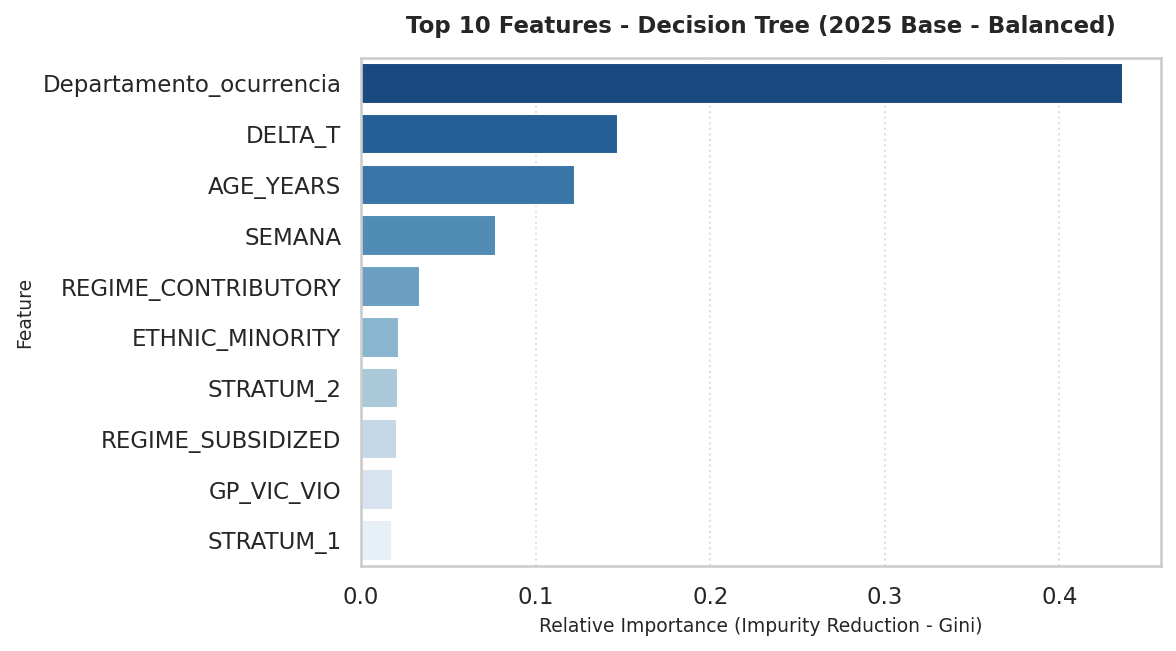

Top 10 Features (Decision Tree (2025 Base - Balanced)):
 Departamento_ocurrencia    0.436443
DELTA_T                    0.146995
AGE_YEARS                  0.122366
SEMANA                     0.077014
REGIME_CONTRIBUTORY        0.033804
ETHNIC_MINORITY            0.021811
STRATUM_2                  0.021292
REGIME_SUBSIDIZED          0.020797
GP_VIC_VIO                 0.018358
STRATUM_1                  0.017576
dtype: float64
---------------------------------------------


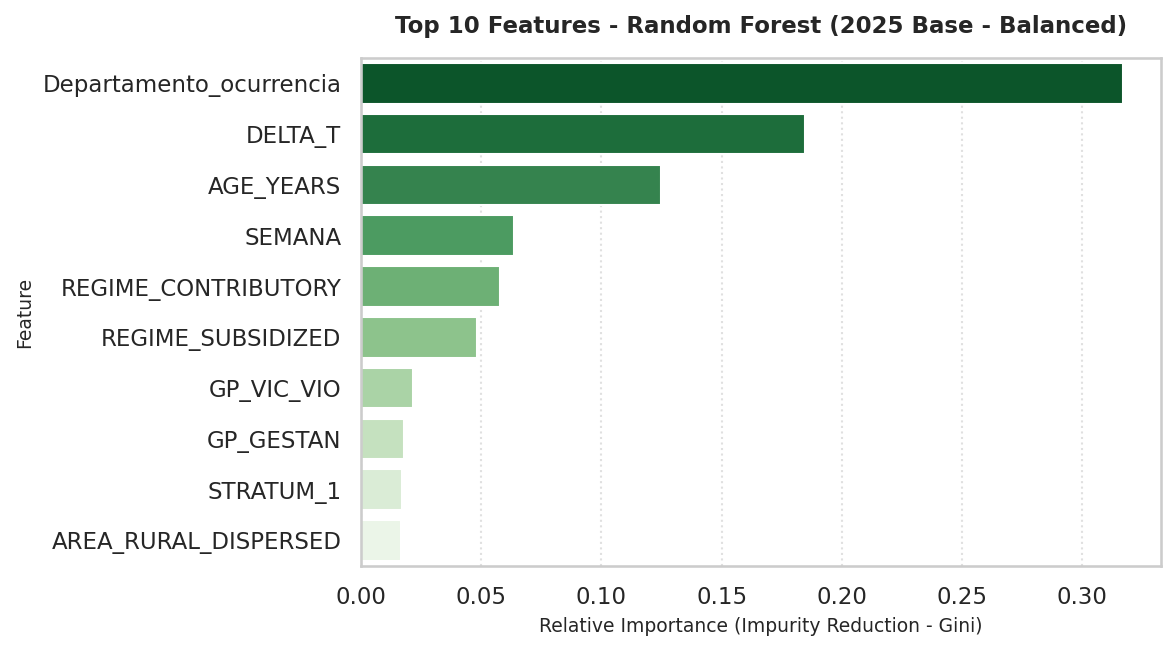

Top 10 Features (Random Forest (2025 Base - Balanced)):
 Departamento_ocurrencia    0.316948
DELTA_T                    0.184670
AGE_YEARS                  0.124785
SEMANA                     0.063576
REGIME_CONTRIBUTORY        0.057773
REGIME_SUBSIDIZED          0.048077
GP_VIC_VIO                 0.021521
GP_GESTAN                  0.017719
STRATUM_1                  0.017144
AREA_RURAL_DISPERSED       0.016584
dtype: float64
---------------------------------------------
=== STARTING GRIDSEARCHCV (DECISION TREE (2025)) ===
Fitting 5 folds for each of 24 candidates, totalling 120 fits

--- GridSearchCV Results (Decision Tree (2025)) ---
Best hyperparameters: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 12}
Best mean CV recall: 0.6026

--- Top 10 CV Configurations ---


,param_criterion,param_max_depth,param_class_weight,mean_test_recall,std_test_recall,rank_test_score
0,entropy,12,balanced,0.602587,0.012352,1
1,gini,12,balanced,0.601472,0.008573,2
2,gini,8,balanced,0.600676,0.012365,3
3,entropy,15,balanced,0.599783,0.009373,4
4,gini,15,balanced,0.595484,0.005885,5
5,entropy,8,balanced,0.595197,0.011289,6
6,gini,10,balanced,0.593413,0.020547,7
7,entropy,10,balanced,0.590228,0.022939,8
8,entropy,4,balanced,0.581628,0.022137,9
9,gini,4,balanced,0.571246,0.012893,10



=== TEST SET EVALUATION (DECISION TREE (2025) OPTIMIZED) ===
Accuracy:            0.6233
Recall (Sensitivity): 0.5884
Precision:           0.4947
Specificity:         0.6440
False Negatives (FN): 5,539
True Positives (TP):  7,917
---------------------------------------------


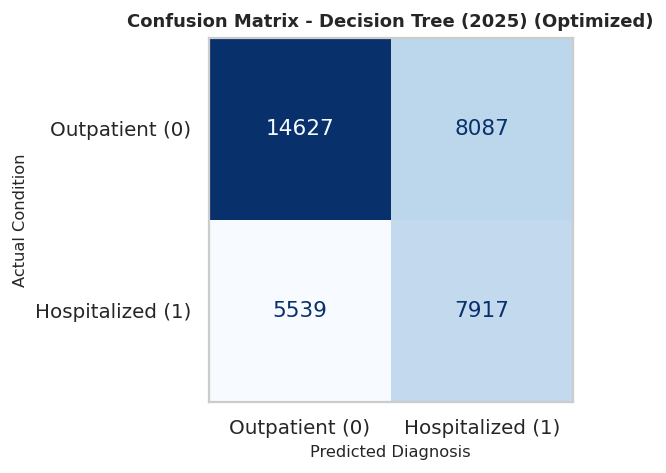

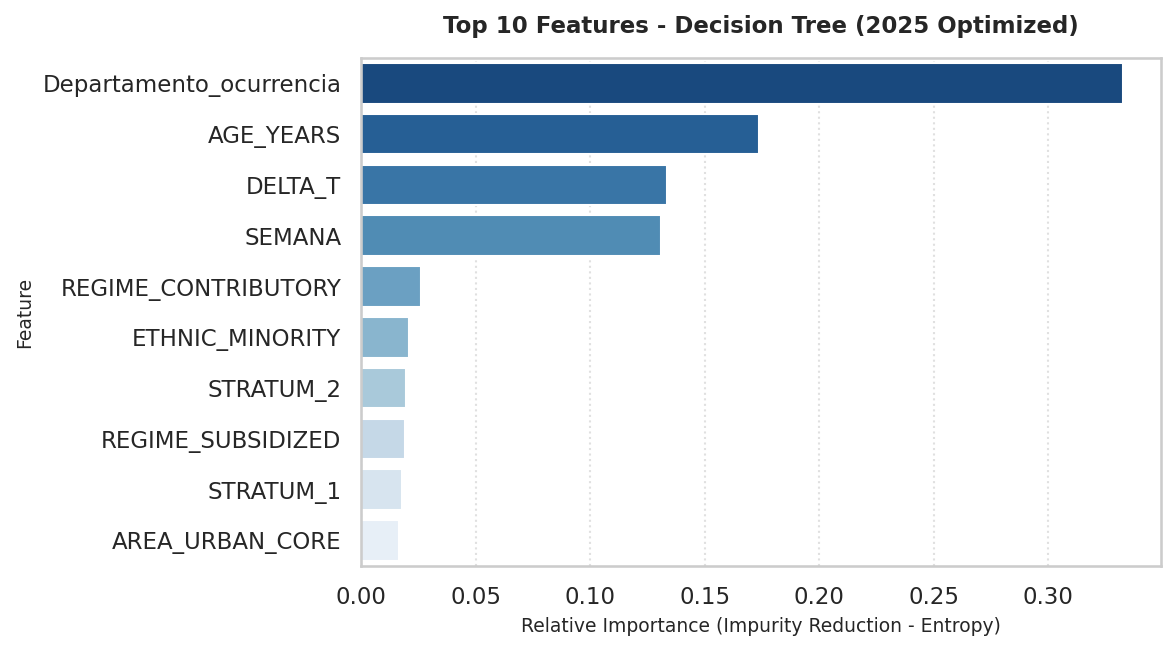

Top 10 Features (Decision Tree (2025 Optimized)):
 Departamento_ocurrencia    0.332649
AGE_YEARS                  0.173572
DELTA_T                    0.133542
SEMANA                     0.130913
REGIME_CONTRIBUTORY        0.025928
ETHNIC_MINORITY            0.021018
STRATUM_2                  0.019555
REGIME_SUBSIDIZED          0.018959
STRATUM_1                  0.017857
AREA_URBAN_CORE            0.016678
dtype: float64
---------------------------------------------
=== STARTING GRIDSEARCHCV (RANDOM FOREST (2025)) ===
Fitting 5 folds for each of 40 candidates, totalling 200 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



--- GridSearchCV Results (Random Forest (2025)) ---
Best hyperparameters: {'class_weight': 'balanced', 'max_depth': 10, 'n_estimators': 200}
Best mean CV recall: 0.6208

--- Top 10 CV Configurations ---


,param_n_estimators,param_max_depth,param_class_weight,mean_test_recall,std_test_recall,rank_test_score
0,200,10,balanced,0.620772,0.008908,1
1,100,10,balanced,0.617269,0.010808,2
2,10,10,balanced,0.617045,0.010630,3
3,50,10,balanced,0.616951,0.009596,4
4,20,10,balanced,0.614848,0.015325,5
5,20,6,balanced,0.610581,0.017381,6
6,50,6,balanced,0.609243,0.011986,7
7,100,6,balanced,0.605676,0.010900,8
8,200,6,balanced,0.604784,0.008261,9
9,10,6,balanced,0.603861,0.017574,10



=== TEST SET EVALUATION (RANDOM FOREST (2025) OPTIMIZED) ===
Accuracy:            0.6265
Recall (Sensitivity): 0.6174
Precision:           0.4984
Specificity:         0.6319
False Negatives (FN): 5,148
True Positives (TP):  8,308
---------------------------------------------


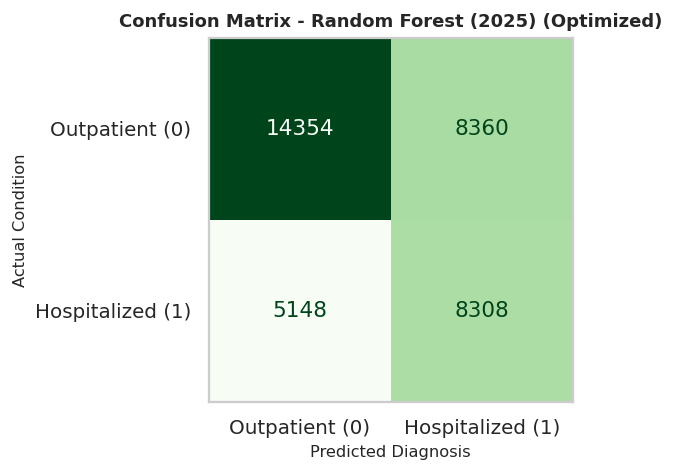

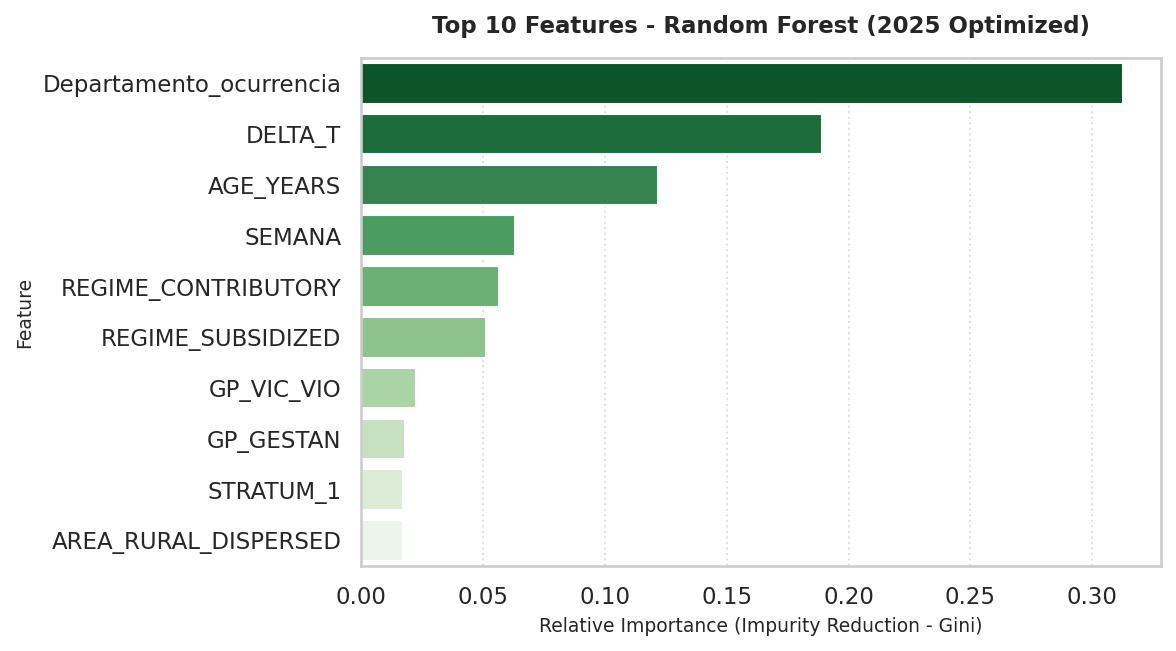

Top 10 Features (Random Forest (2025 Optimized)):
 Departamento_ocurrencia    0.312528
DELTA_T                    0.189250
AGE_YEARS                  0.121963
SEMANA                     0.063261
REGIME_CONTRIBUTORY        0.056662
REGIME_SUBSIDIZED          0.051036
GP_VIC_VIO                 0.022383
GP_GESTAN                  0.018125
STRATUM_1                  0.017072
AREA_RURAL_DISPERSED       0.017071
dtype: float64
---------------------------------------------
=== 2025 COHORT - BASELINE MODELS (BALANCED) ===



,Accuracy,Recall,Precision,Specificity,FN,TP
Model,,,,,,
Gaussian Naive Bayes,0.4532,0.8691,0.3936,0.2067,1761,11695
Logistic Regression,0.5737,0.5970,0.4455,0.5598,5423,8033
Decision Tree,0.6268,0.5771,0.4986,0.6562,5690,7766
Random Forest,0.6287,0.6127,0.5008,0.6382,5212,8244
SVM (Linear),0.5728,0.5977,0.4448,0.5580,5413,8043
SVC (RBF),0.5889,0.5939,0.4594,0.5860,5464,7992
SVC (Poly),0.5751,0.6173,0.4484,0.5501,5150,8306
SVC (Sigmoid),0.5221,0.4893,0.3874,0.5416,6872,6584


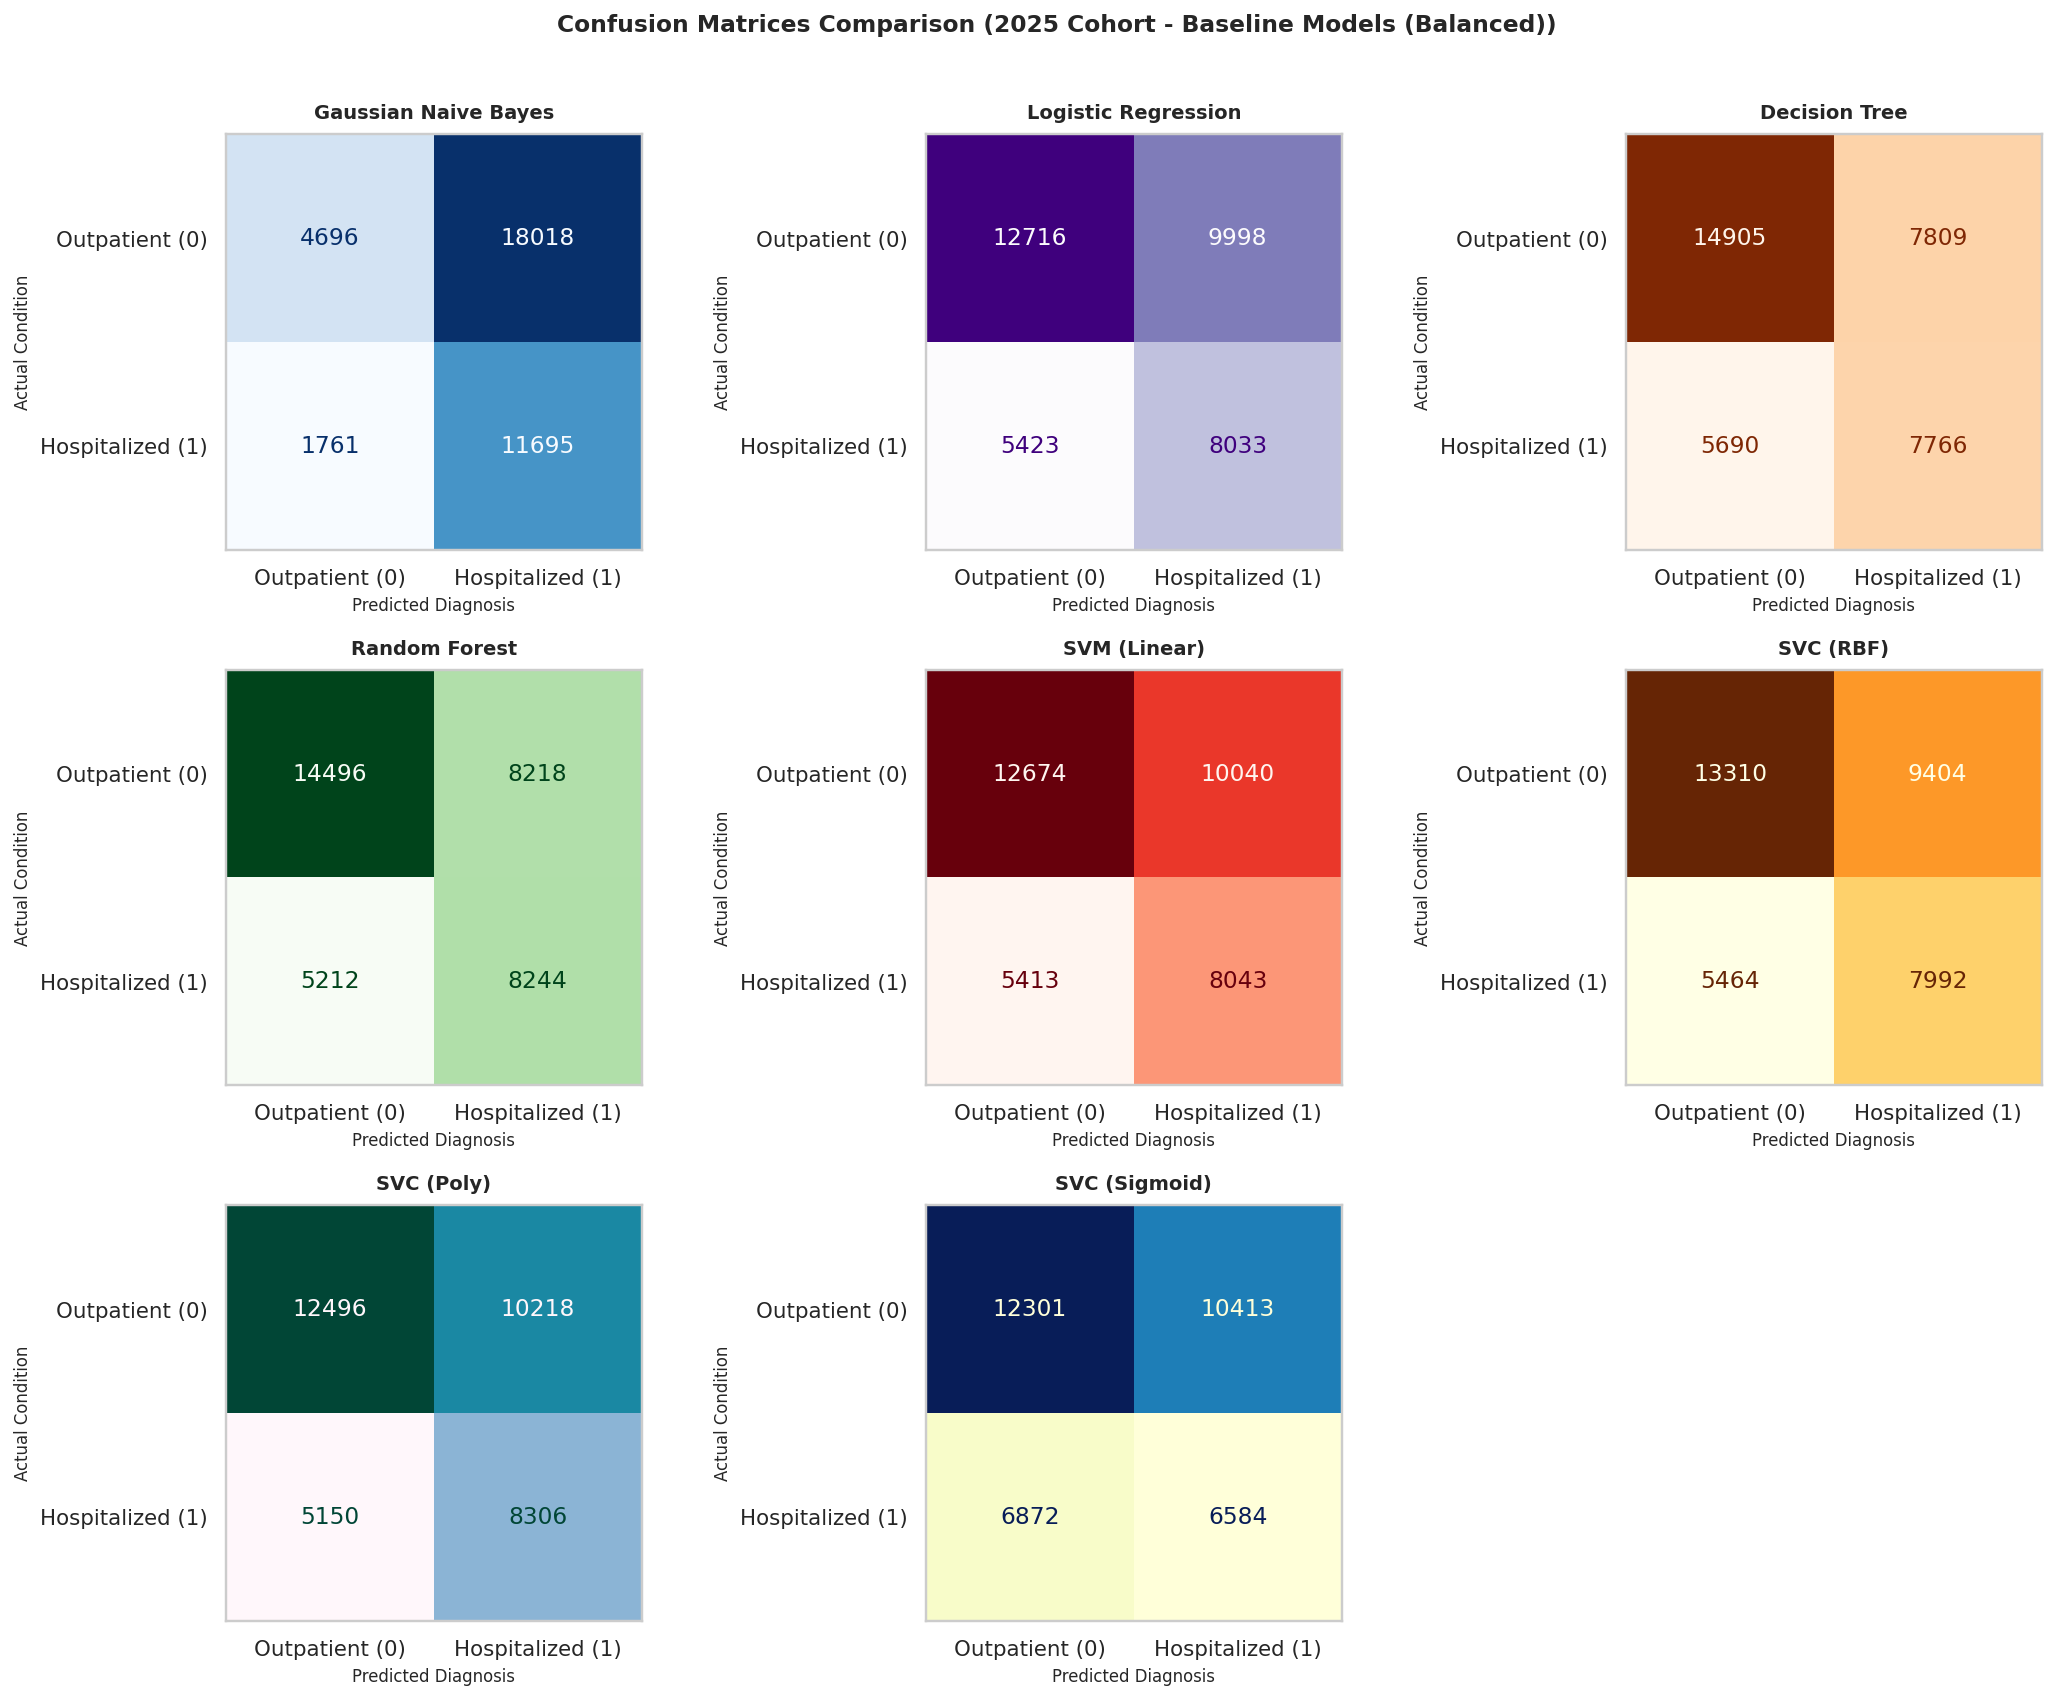


=== CLINICAL IMPACT OF HYPERPARAMETER OPTIMIZATION ===


,Recall,False Negatives (FN),True Positives (TP)
Stage,,,
Decision Tree (Base),0.5771,5690,7766
Decision Tree (GridSearchCV),0.5884,5539,7917
Random Forest (Base),0.6127,5212,8244
Random Forest (GridSearchCV),0.6174,5148,8308


=== TRAINING AND EVALUATING MODEL SUITE ===

• Training Gaussian Naive Bayes...
• Training Logistic Regression...
• Training Decision Tree...
• Training Random Forest...
• Training SVM (Linear)...
=== 2025 COHORT - UNWEIGHTED CONTROL SUITE (CLASS_WEIGHT=NONE) ===



,Accuracy,Recall,Precision,Specificity,FN,TP
Model,,,,,,
Gaussian Naive Bayes,0.4532,0.8691,0.3936,0.2067,1761,11695
Logistic Regression,0.6262,0.0541,0.4783,0.9650,12728,728
Decision Tree,0.6665,0.3074,0.6014,0.8793,9319,4137
Random Forest,0.6630,0.1630,0.7031,0.9592,11263,2193
SVM (Linear),0.6257,0.0456,0.4680,0.9693,12842,614


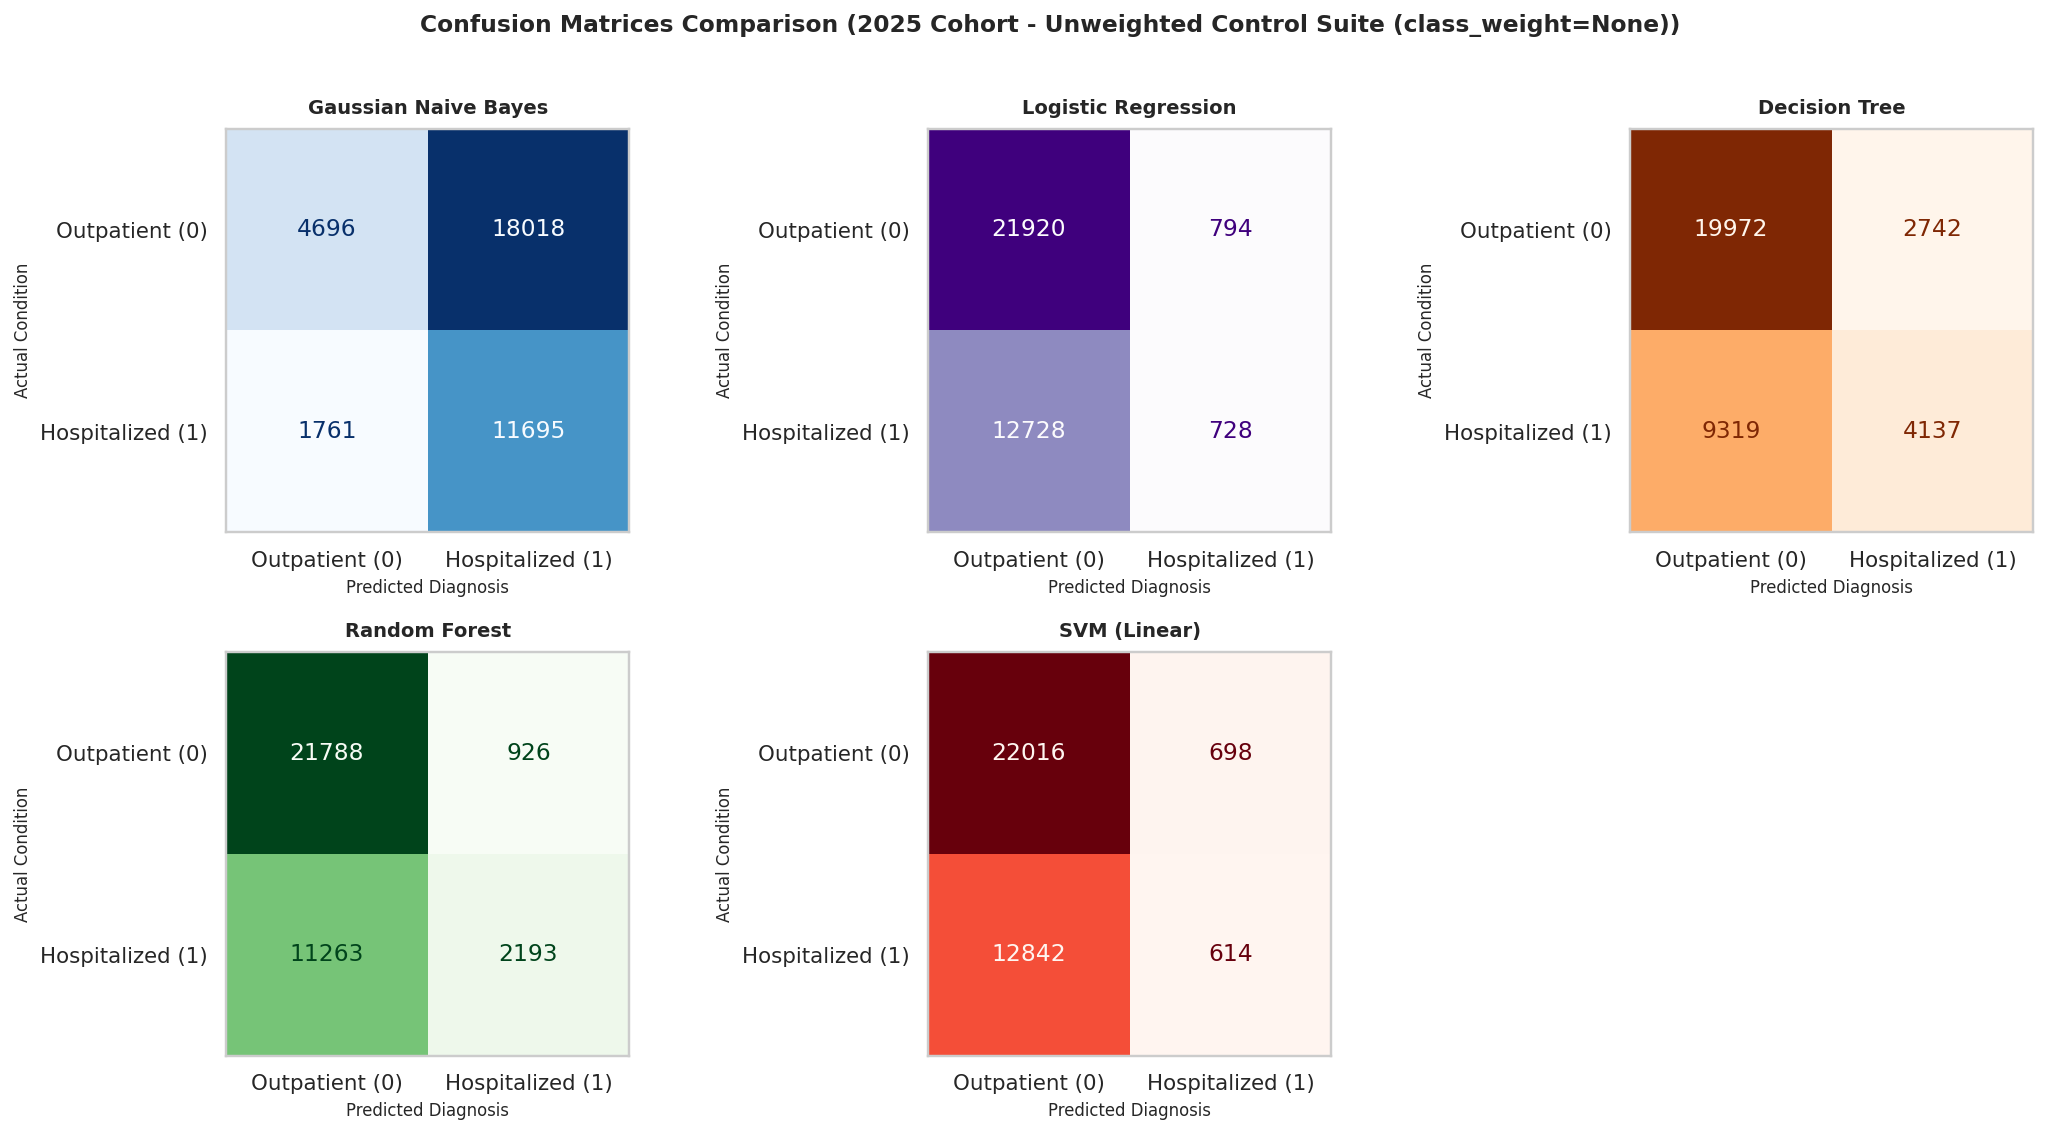

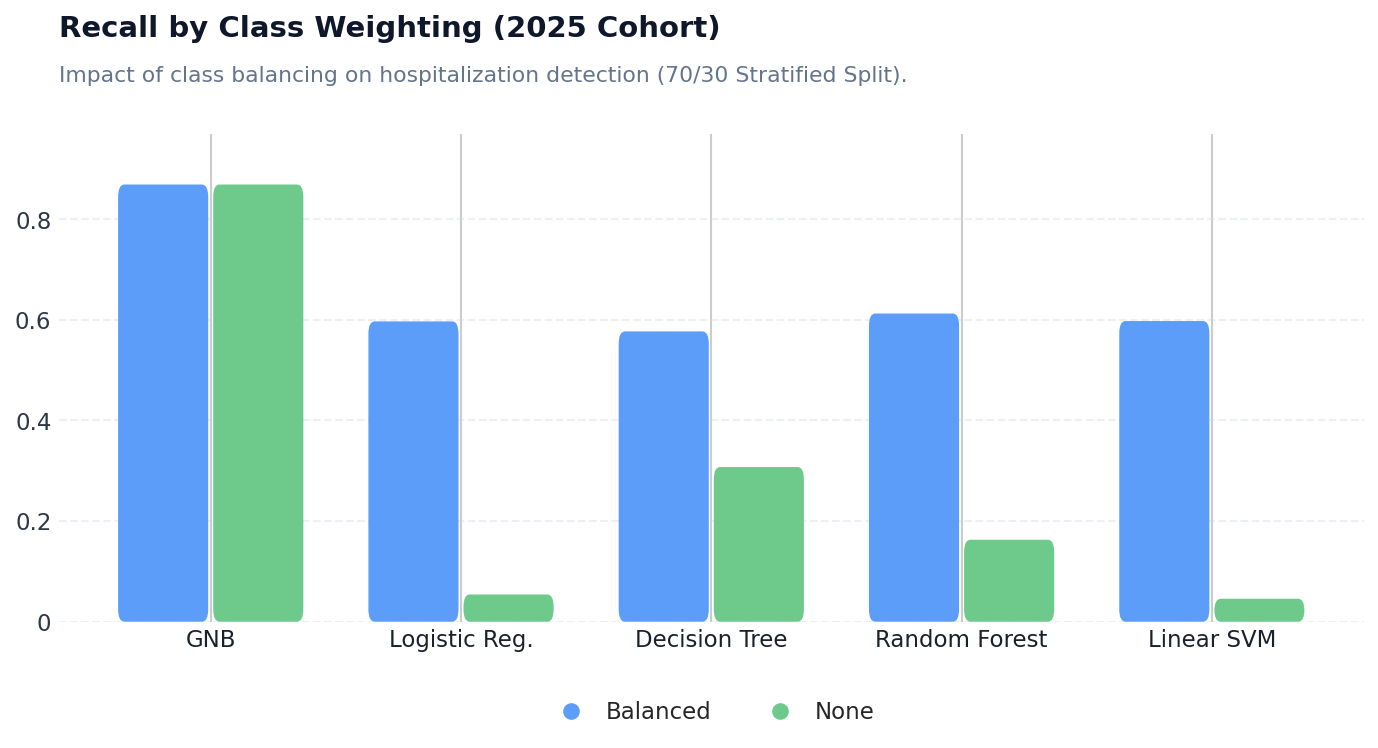

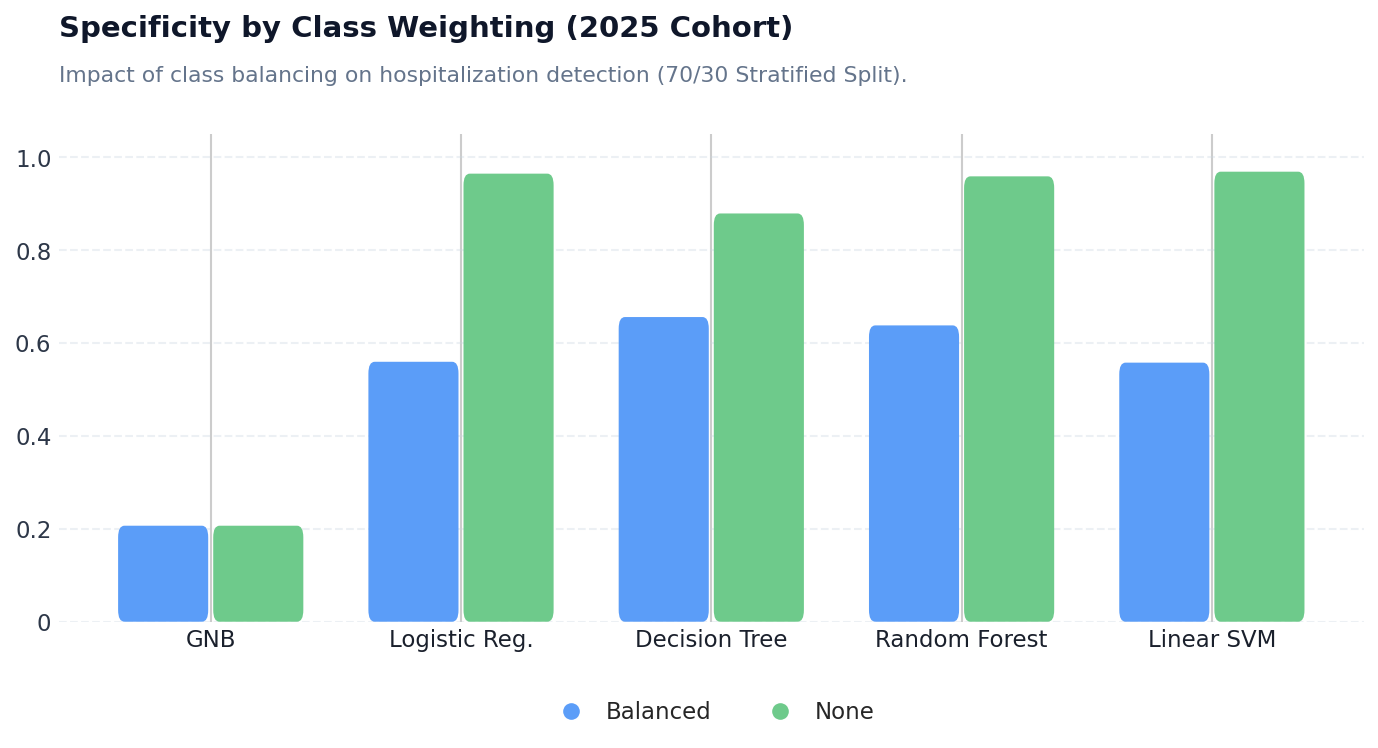

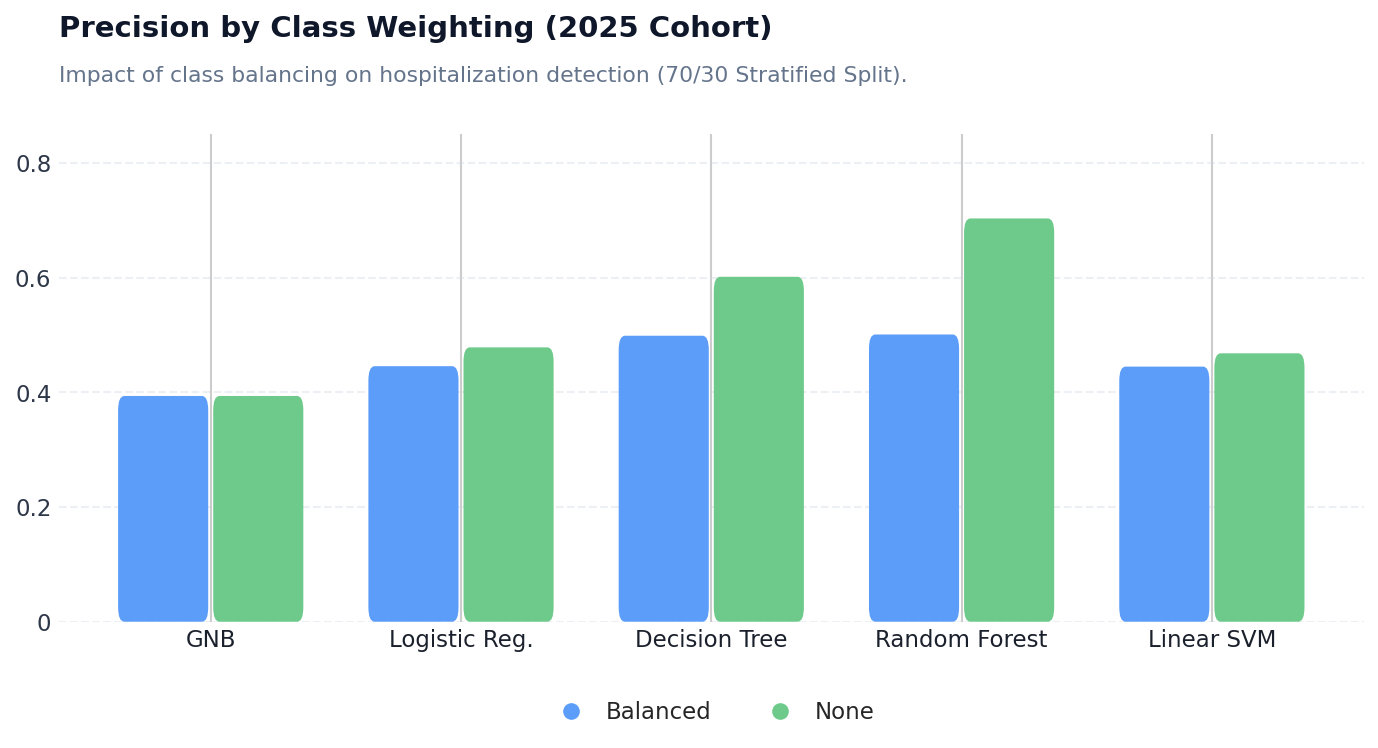

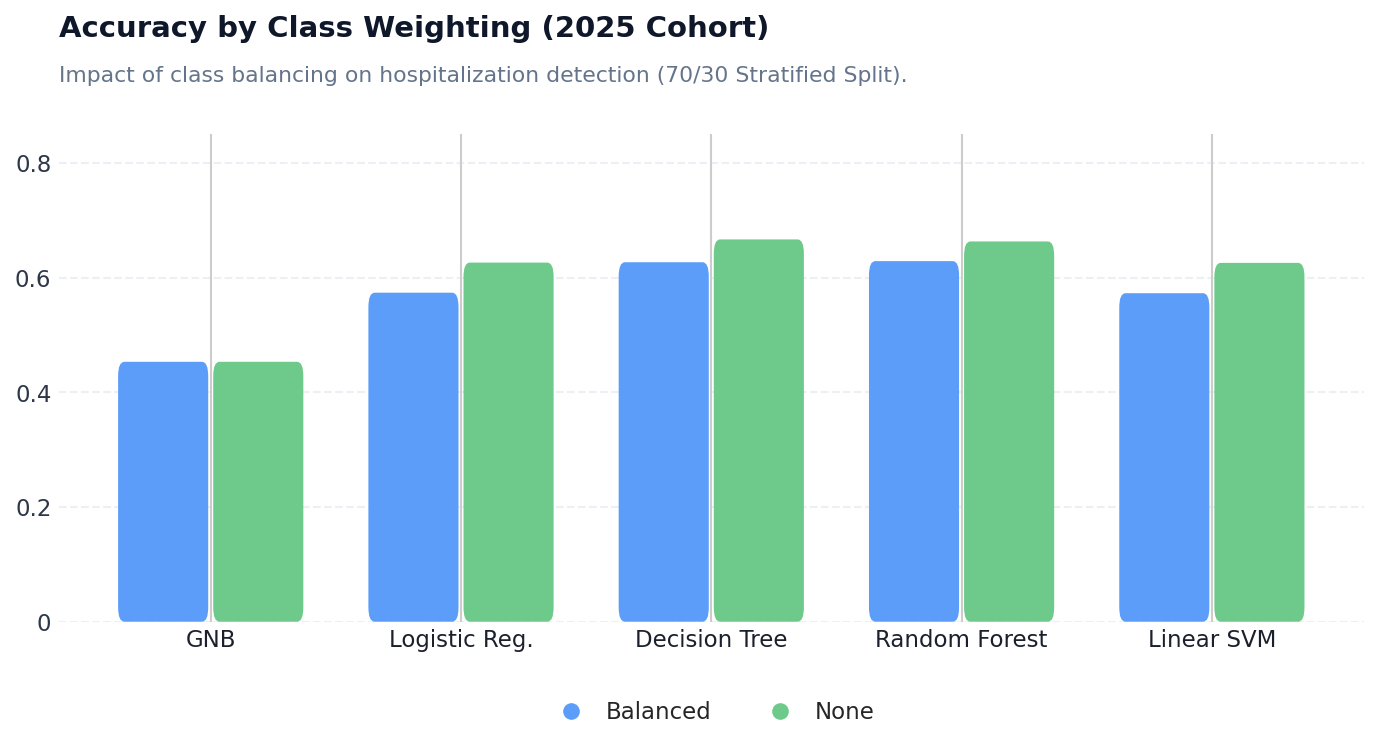

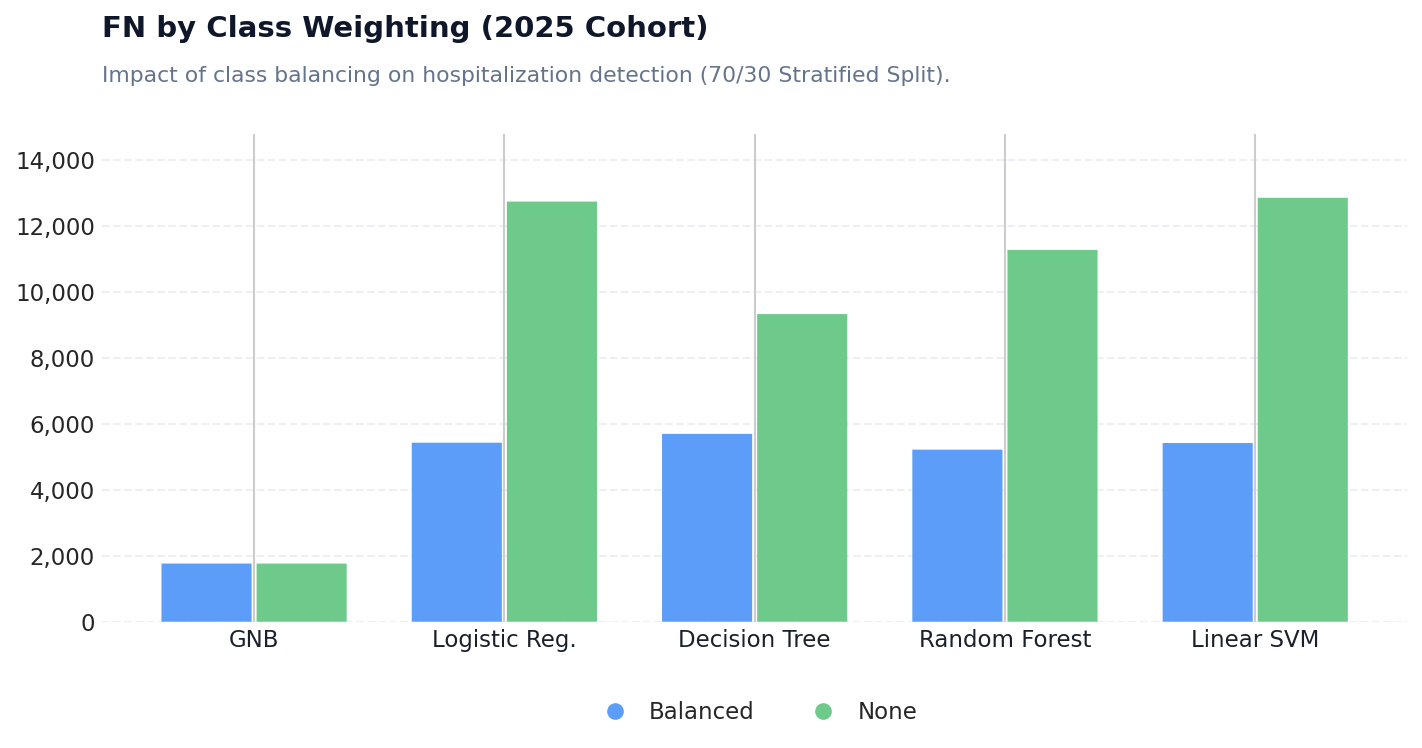

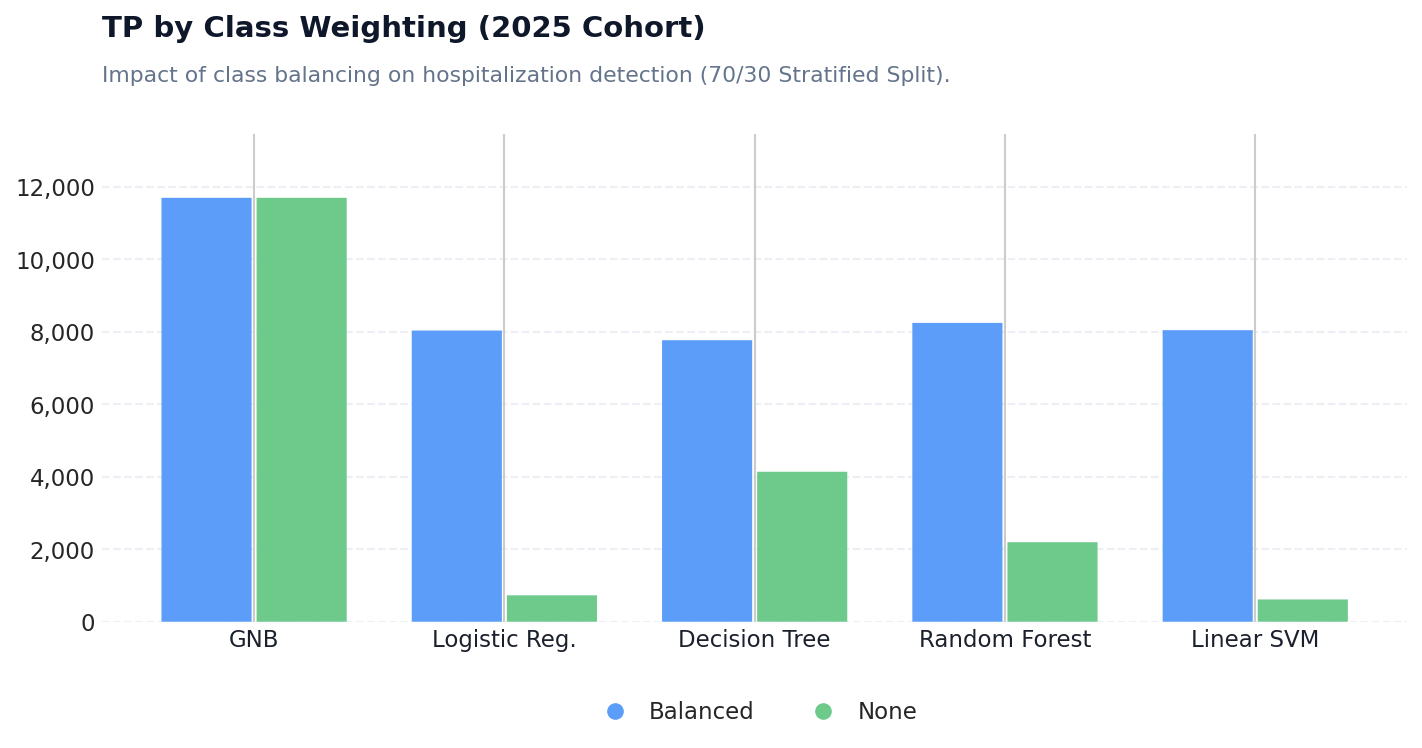

=== STARTING CROSS-VALIDATION (5 FOLDS): GAUSSIAN NAIVE BAYES (2025 COHORT) | Scale=False ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.4096,0.9533,0.3823,0.0874,419,8552
Fold 2,0.4441,0.8859,0.3910,0.1824,1024,7947
Fold 3,0.4529,0.8733,0.3939,0.2038,1137,7834
Fold 4,0.4641,0.8396,0.3961,0.2417,1439,7532
Fold 5,0.4432,0.8873,0.3907,0.1802,1011,7959


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.4428,0.8879,0.3908,0.1791,1006.0,7964.8
Std. Dev. (σ),± 0.0204,± 0.0413,± 0.0052,± 0.0569,± 370.7,± 370.7


-----------------------------------------------------------------
=== STARTING CROSS-VALIDATION (5 FOLDS): DECISION TREE BALANCED (2025 COHORT) | Scale=False ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.6372,0.5721,0.5111,0.6757,3839,5132
Fold 2,0.6262,0.6173,0.4981,0.6314,3433,5538
Fold 3,0.6072,0.6609,0.4798,0.5754,3042,5929
Fold 4,0.6145,0.6306,0.4861,0.6050,3314,5657
Fold 5,0.6164,0.6387,0.4881,0.6032,3241,5729


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.6203,0.6239,0.4926,0.6182,3373.8,5597.0
Std. Dev. (σ),± 0.0116,± 0.0330,± 0.0122,± 0.0378,± 296.3,± 296.2


-----------------------------------------------------------------


In [ ]:
# ==============================================================================
# 5. EXPERIMENT 1: 2025 INTRA-ANNUAL COHORT (SOCIODEMOGRAPHIC FEATURES)
# ==============================================================================

# 5.1 Train / Test Split (70/30 Stratified)
y_2025 = working_2025['PAC_HOS'].copy()
x_2025 = working_2025.drop(columns=['PAC_HOS']).copy()

x_tr_2025, x_te_2025, y_tr_2025, y_te_2025 = train_test_split(
    x_2025, y_2025, test_size=0.30, random_state=SEED, stratify=y_2025
)

# 5.2 Leakage-Free Frequency Encoding & Standard Scaling
for col in ['Departamento_ocurrencia', 'SEMANA']:
    freqs = x_tr_2025[col].value_counts(normalize=True)
    x_tr_2025[col] = x_tr_2025[col].map(freqs).fillna(0).astype('float64')
    x_te_2025[col] = x_te_2025[col].map(freqs).fillna(0).astype('float64')

scaler_2025 = StandardScaler()
x_tr_2025_s = scaler_2025.fit_transform(x_tr_2025)
x_te_2025_s = scaler_2025.transform(x_te_2025)

print(f"2025 Train shape: {x_tr_2025.shape} | Test shape: {x_te_2025.shape}")

# ------------------------------------------------------------------------------
# 5.3 Balanced Class Weight Models (class_weight='balanced')
# ------------------------------------------------------------------------------
suite_bal_2025 = build_model_suite(
    x_tr_2025, x_te_2025, x_tr_2025_s, x_te_2025_s, class_weight='balanced'
)
preds_bal_2025 = train_model_suite(suite_bal_2025, y_tr_2025)

# Non-linear SVM kernels (Balanced)
nonlinear_svms_bal = {
    'SVC (RBF)': SVC(kernel='rbf', cache_size=4000, random_state=SEED, class_weight='balanced'),
    'SVC (Poly)': SVC(kernel='poly', cache_size=4000, random_state=SEED, class_weight='balanced'),
    'SVC (Sigmoid)': SVC(kernel='sigmoid', cache_size=4000, random_state=SEED, class_weight='balanced'),
}
preds_svm_extra_bal = {
    name: evaluate_model(name, clf, x_tr_2025_s, y_tr_2025, x_te_2025_s, y_te_2025, plot=False)
    for name, clf in nonlinear_svms_bal.items()
}

# Feature importance for baseline tree models (Balanced)
top10_dt_2025 = plot_feature_importance(
    suite_bal_2025['Decision Tree'][0], x_tr_2025.columns, "Decision Tree (2025 Base - Balanced)", palette="Blues_r"
)
top10_rf_2025 = plot_feature_importance(
    suite_bal_2025['Random Forest'][0], x_tr_2025.columns, "Random Forest (2025 Base - Balanced)", palette="Greens_r"
)

# ------------------------------------------------------------------------------
# 5.4 Hyperparameter Tuning via GridSearchCV (Decision Tree & Random Forest)
# ------------------------------------------------------------------------------
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [4, 6, 8, 10, 12, 15],
    'class_weight': [None, 'balanced'],
}
best_dt_2025, pred_dt_opt_2025, _ = run_grid_search(
    name='Decision Tree (2025)',
    base_estimator=DecisionTreeClassifier(random_state=SEED),
    param_grid=param_grid_dt,
    x_tr=x_tr_2025,
    y_tr=y_tr_2025,
    x_te=x_te_2025,
    y_te=y_te_2025,
    cmap='Blues',
)
plot_feature_importance(best_dt_2025, x_tr_2025.columns, "Decision Tree (2025 Optimized)", palette="Blues_r")

param_grid_rf = {
    'n_estimators': [10, 20, 50, 100, 200],
    'max_depth': [6, 10, 15, 20],
    'class_weight': [None, 'balanced'],
}
best_rf_2025, pred_rf_opt_2025, _ = run_grid_search(
    name='Random Forest (2025)',
    base_estimator=RandomForestClassifier(random_state=SEED, n_jobs=-1),
    param_grid=param_grid_rf,
    x_tr=x_tr_2025,
    y_tr=y_tr_2025,
    x_te=x_te_2025,
    y_te=y_te_2025,
    cmap='Greens',
)
plot_feature_importance(best_rf_2025, x_tr_2025.columns, "Random Forest (2025 Optimized)", palette="Greens_r")

# Merge baseline suite (5 models) with non-linear SVMs (3 kernels) -> 8 models total
preds_bal_2025.update(preds_svm_extra_bal)

df_comp_bal_2025 = generate_consolidated_report(
    predictions=preds_bal_2025,
    y_test=y_te_2025,
    title='2025 Cohort - Baseline Models (Balanced)',
    ncols=3,
)

df_impact_2025 = report_optimization_impact(
    comparisons=[
        ('Decision Tree (Base)', preds_bal_2025['Decision Tree']),
        ('Decision Tree (GridSearchCV)', pred_dt_opt_2025),
        ('Random Forest (Base)', preds_bal_2025['Random Forest']),
        ('Random Forest (GridSearchCV)', pred_rf_opt_2025),
    ],
    y_test=y_te_2025,
)

# ------------------------------------------------------------------------------
# 5.5 Unweighted Control Suite (class_weight=None) & Weighting Comparison
# ------------------------------------------------------------------------------
suite_none_2025 = build_model_suite(
    x_tr_2025, x_te_2025, x_tr_2025_s, x_te_2025_s, class_weight=None
)
preds_none_2025 = train_model_suite(suite_none_2025, y_tr_2025)

df_comp_none_2025 = generate_consolidated_report(
    predictions=preds_none_2025,
    y_test=y_te_2025,
    title='2025 Cohort - Unweighted Control Suite (class_weight=None)',
    ncols=3,
)

metrics_to_plot = ['Recall', 'Specificity', 'Precision', 'Accuracy', 'FN', 'TP']
for metric in metrics_to_plot:
    plot_balanced_vs_none(
        df_balanced=df_comp_bal_2025,
        df_none=df_comp_none_2025,
        metric=metric,
        title=f"{metric} by Class Weighting (2025 Cohort)",
        subtitle="Impact of class balancing on hospitalization detection (70/30 Stratified Split).",
    )

# ------------------------------------------------------------------------------
# 5.6 Stratified 5-Fold Cross-Validation (2025 Cohort - Raw Unencoded Input)
# ------------------------------------------------------------------------------
df_folds_gnb_2025, df_res_gnb_2025 = run_stratified_cv(
    name='Gaussian Naive Bayes (2025 Cohort)',
    model=GaussianNB(),
    X=x_2025,
    y=y_2025,
    n_splits=5,
    scale=False,
)

df_folds_dt_2025, df_res_dt_2025 = run_stratified_cv(
    name='Decision Tree Balanced (2025 Cohort)',
    model=DecisionTreeClassifier(max_depth=10, class_weight='balanced', criterion='gini', random_state=SEED),
    X=x_2025,
    y=y_2025,
    n_splits=5,
    scale=False,
)

# **Section 6: Experiment 2 — Temporal Generalization (Train: 2022–2024 // Test: 2025)**

OOT Train (2022-2024): (501720, 34) | OOT Test (2025): (120564, 34)
=== TRAINING AND EVALUATING MODEL SUITE ===

• Training Gaussian Naive Bayes...
• Training Logistic Regression...
• Training Decision Tree...
• Training Random Forest...
• Training SVM (Linear)...
=== TEMPORAL GENERALIZATION OOT (2022-2024 -> 2025 | BALANCED) ===



,Accuracy,Recall,Precision,Specificity,FN,TP
Model,,,,,,
Gaussian Naive Bayes,0.5455,0.5990,0.4219,0.5138,17988,26866
Logistic Regression,0.5188,0.7319,0.4165,0.3925,12025,32829
Decision Tree,0.5823,0.7262,0.4610,0.4970,12279,32575
Random Forest,0.5756,0.7204,0.4555,0.4898,12542,32312
SVM (Linear),0.5149,0.7319,0.4140,0.3864,12025,32829


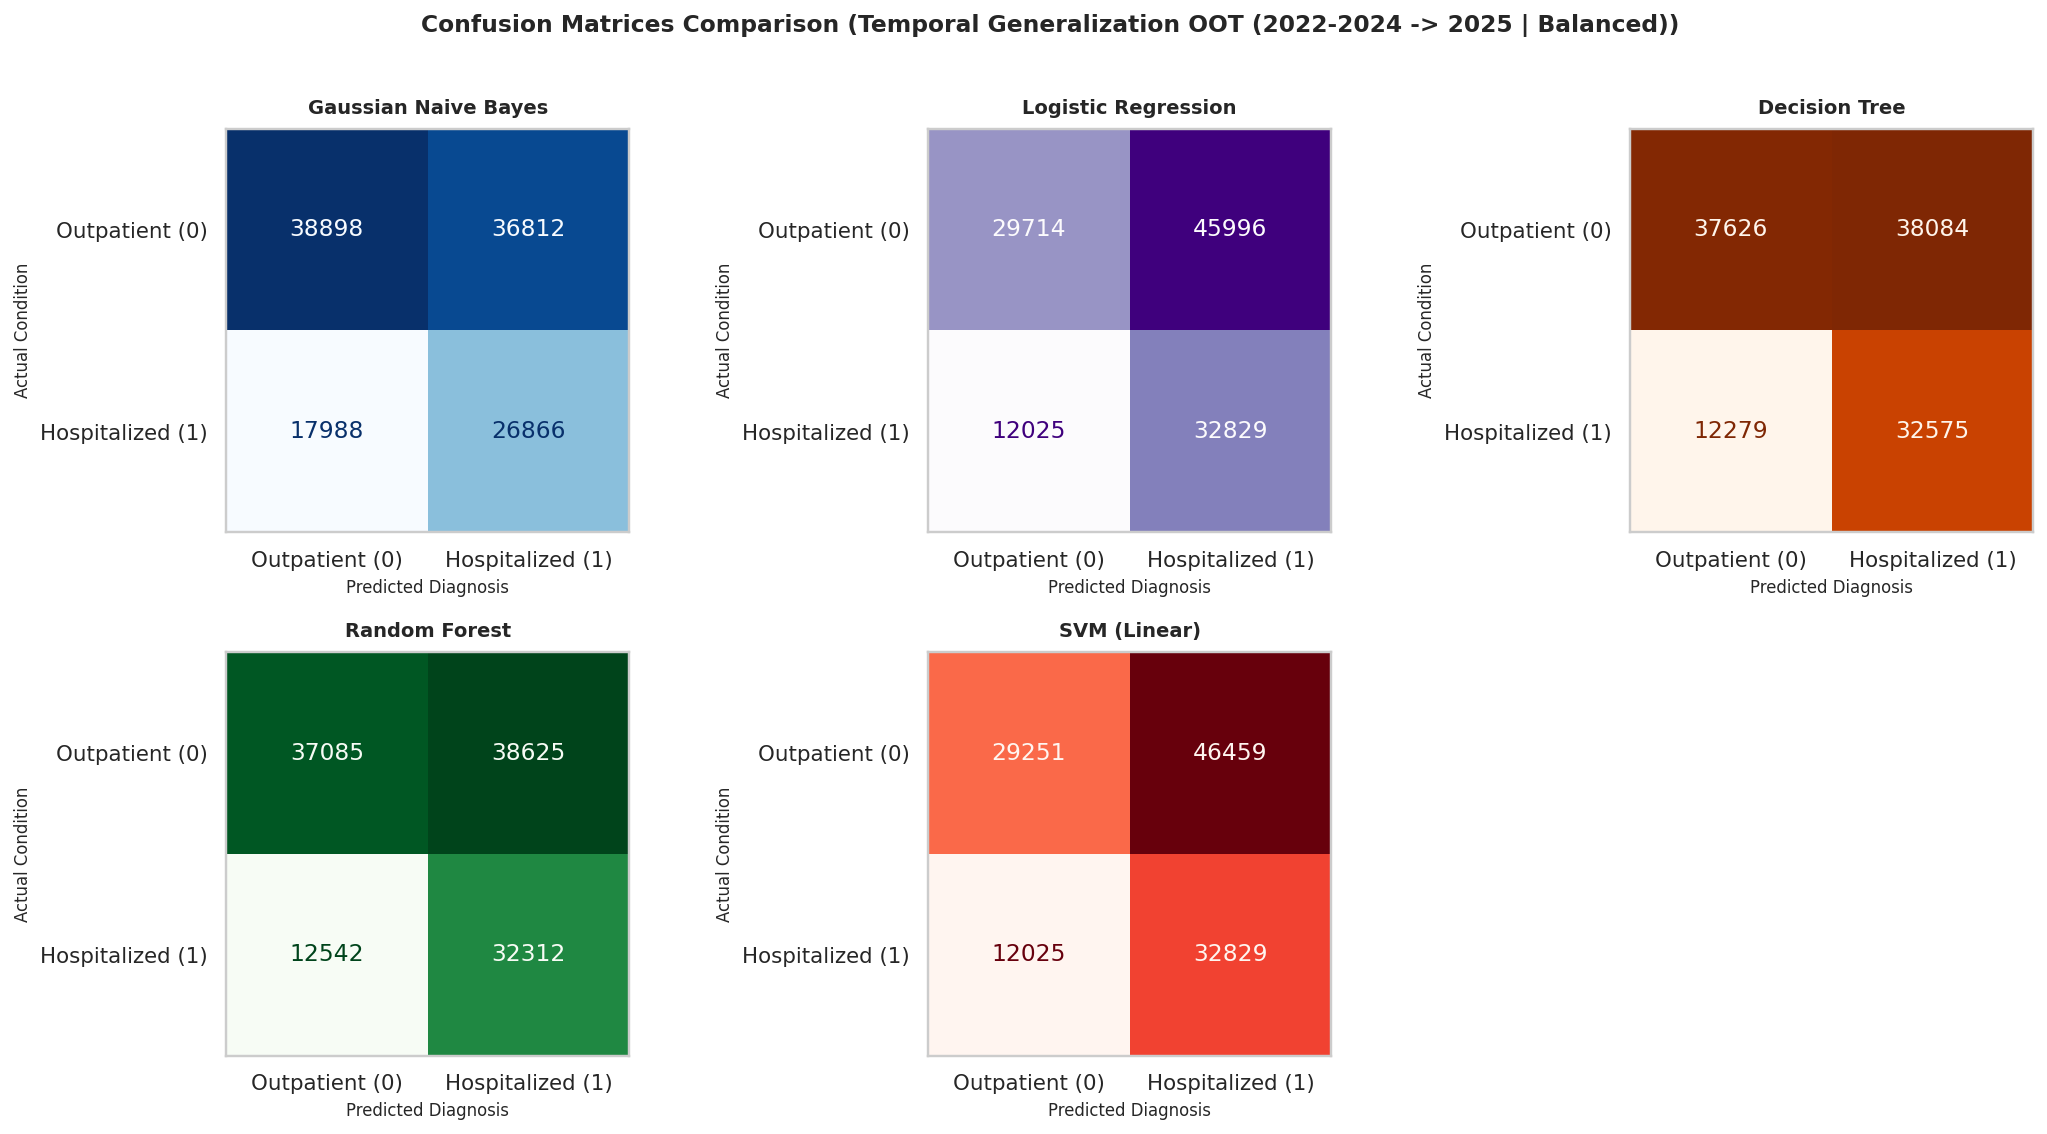

=== TRAINING AND EVALUATING MODEL SUITE ===

• Training Gaussian Naive Bayes...
• Training Logistic Regression...
• Training Decision Tree...
• Training Random Forest...
• Training SVM (Linear)...
=== TEMPORAL GENERALIZATION OOT (2022-2024 -> 2025 | UNWEIGHTED) ===



,Accuracy,Recall,Precision,Specificity,FN,TP
Model,,,,,,
Gaussian Naive Bayes,0.5455,0.5990,0.4219,0.5138,17988,26866
Logistic Regression,0.6300,0.1633,0.5084,0.9065,37530,7324
Decision Tree,0.6513,0.4222,0.5402,0.7871,25915,18939
Random Forest,0.6484,0.3027,0.5500,0.8533,31277,13577
SVM (Linear),0.6310,0.1253,0.5166,0.9305,39232,5622


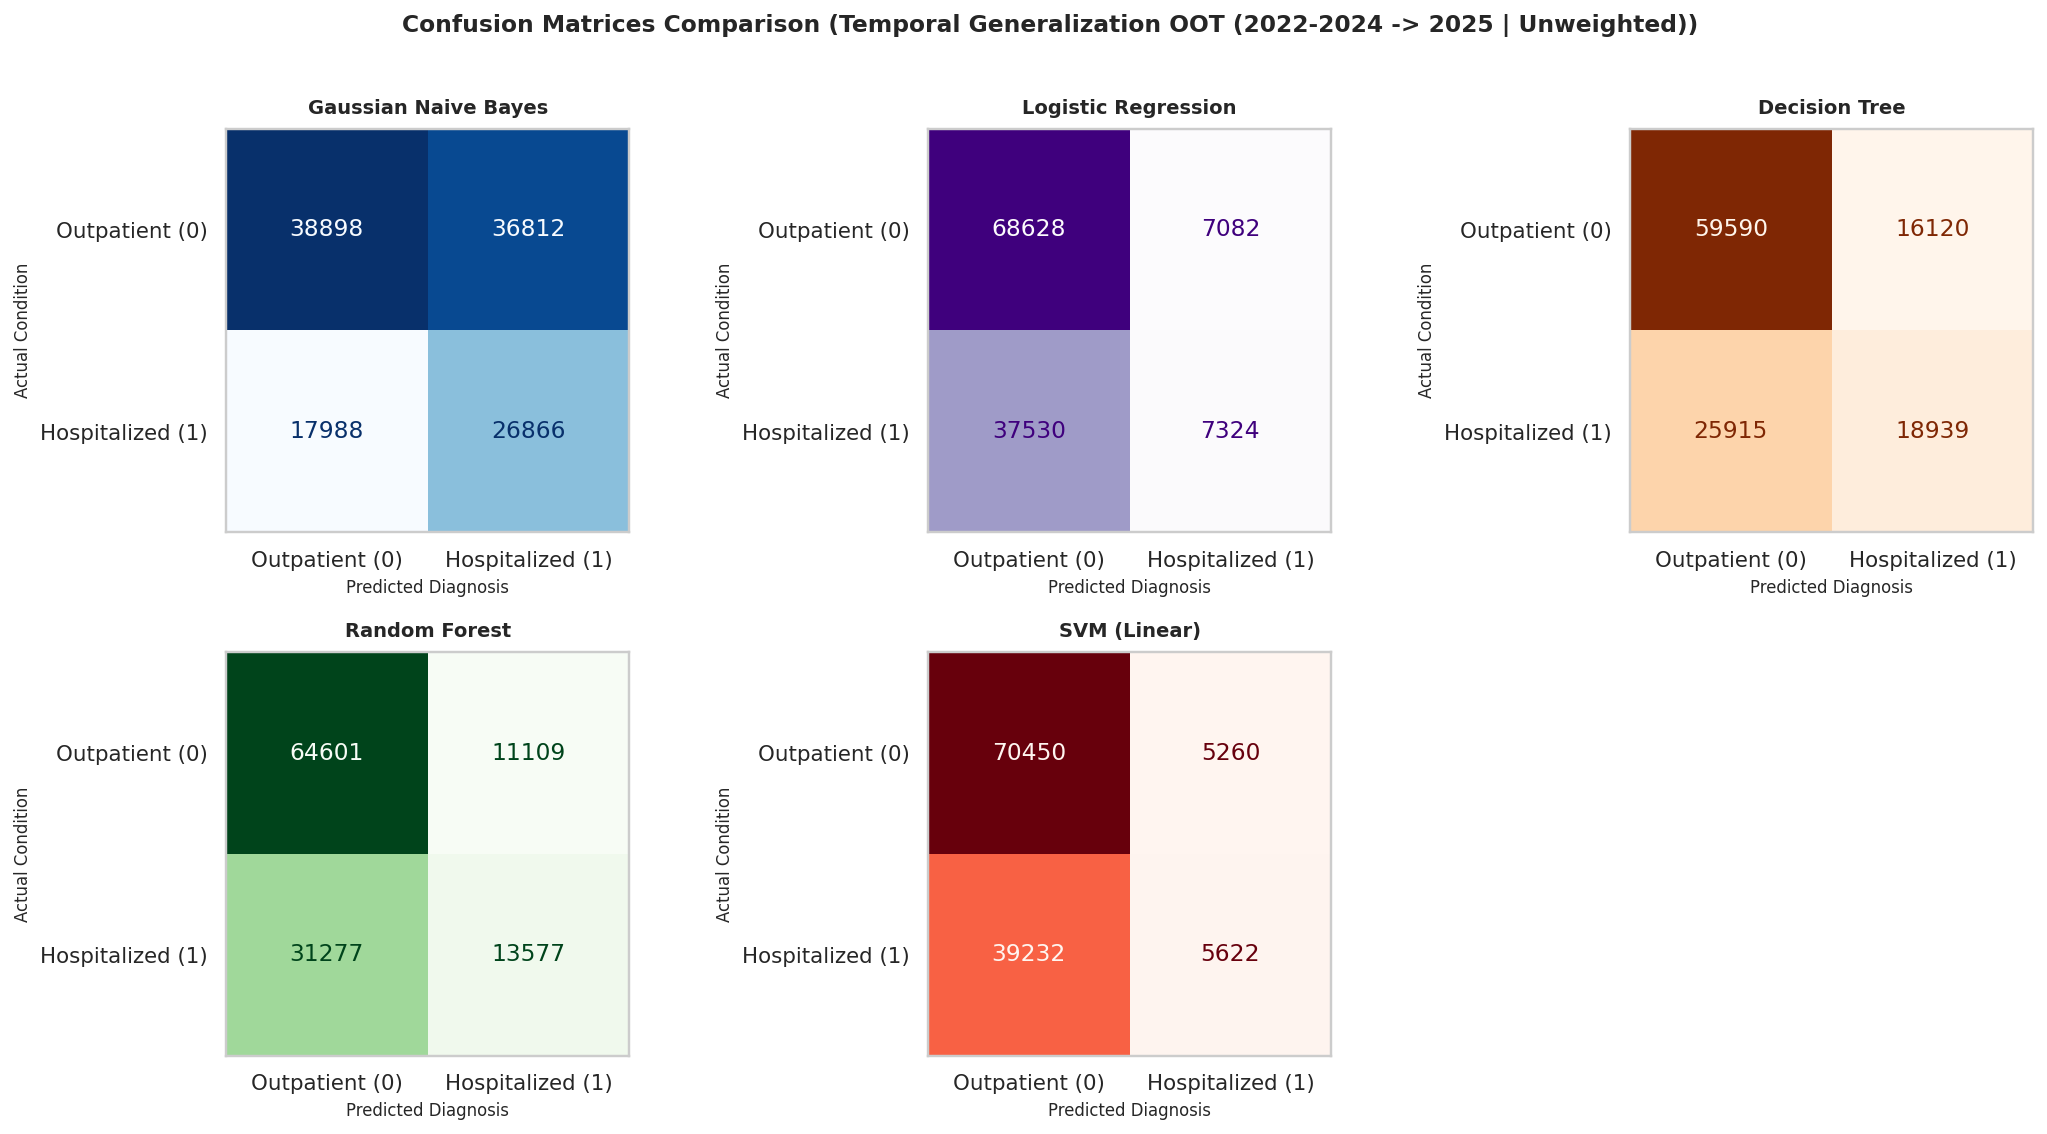

=== STARTING GRIDSEARCHCV (DECISION TREE OOT) ===
Fitting 5 folds for each of 24 candidates, totalling 120 fits

--- GridSearchCV Results (Decision Tree OOT) ---
Best hyperparameters: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 6}
Best mean CV recall: 0.6635

--- Top 10 CV Configurations ---


,param_criterion,param_max_depth,param_class_weight,mean_test_recall,std_test_recall,rank_test_score
0,entropy,6,balanced,0.663467,0.017901,1
1,gini,6,balanced,0.661481,0.015448,2
2,gini,8,balanced,0.633711,0.006529,3
3,entropy,12,balanced,0.632357,0.003064,4
4,gini,12,balanced,0.631821,0.002055,5
5,entropy,8,balanced,0.627017,0.012128,6
6,gini,10,balanced,0.626395,0.017831,7
7,entropy,10,balanced,0.625880,0.018199,8
8,entropy,15,balanced,0.611907,0.005560,9
9,gini,15,balanced,0.607400,0.004651,10



=== TEST SET EVALUATION (DECISION TREE OOT OPTIMIZED) ===
Accuracy:            0.5375
Recall (Sensitivity): 0.7945
Precision:           0.4336
Specificity:         0.3852
False Negatives (FN): 9,219
True Positives (TP):  35,635
---------------------------------------------


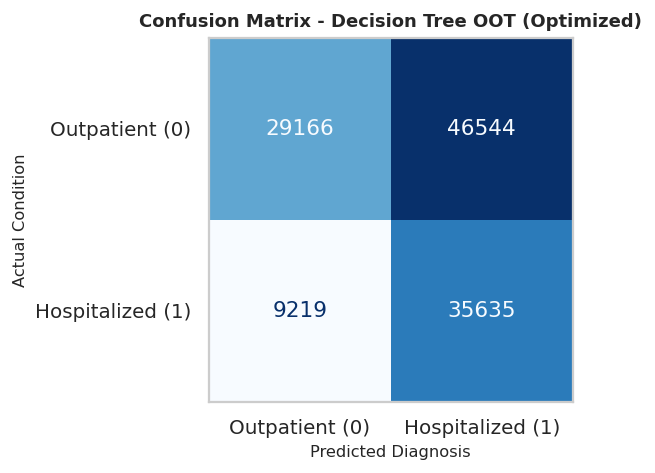

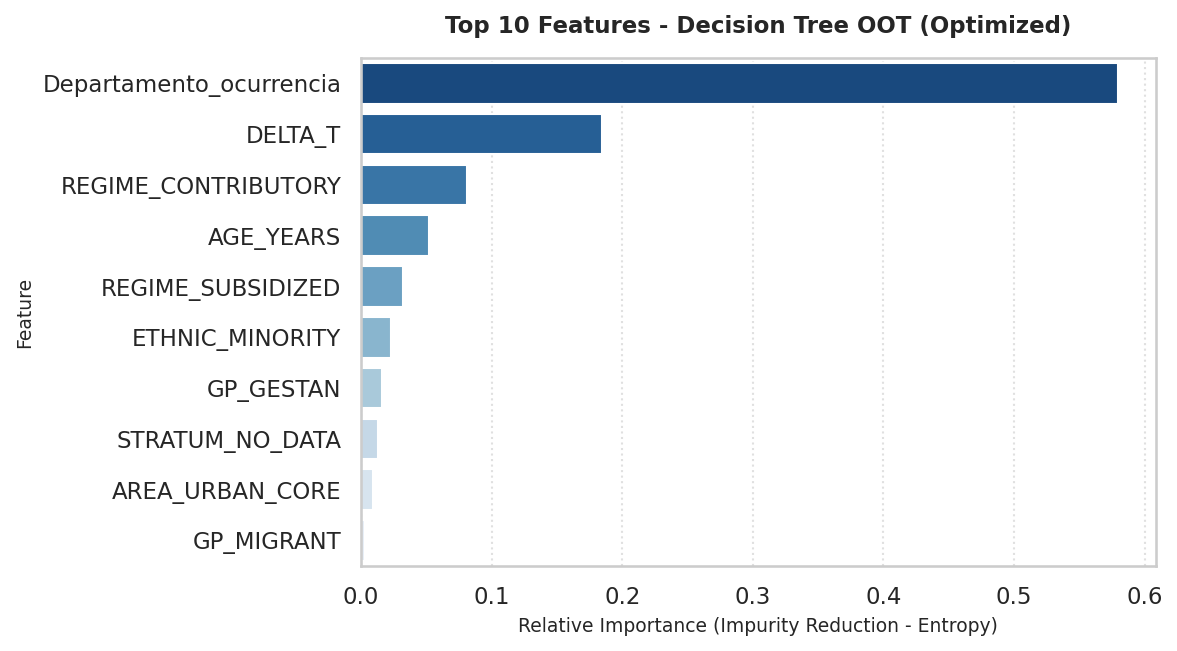

Top 10 Features (Decision Tree OOT (Optimized)):
 Departamento_ocurrencia    0.579376
DELTA_T                    0.184842
REGIME_CONTRIBUTORY        0.081029
AGE_YEARS                  0.051880
REGIME_SUBSIDIZED          0.031878
ETHNIC_MINORITY            0.022954
GP_GESTAN                  0.015975
STRATUM_NO_DATA            0.013126
AREA_URBAN_CORE            0.009357
GP_MIGRANT                 0.003214
dtype: float64
---------------------------------------------
=== STARTING GRIDSEARCHCV (RANDOM FOREST OOT) ===
Fitting 5 folds for each of 40 candidates, totalling 200 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



--- GridSearchCV Results (Random Forest OOT) ---
Best hyperparameters: {'class_weight': 'balanced', 'max_depth': 15, 'n_estimators': 200}
Best mean CV recall: 0.6128

--- Top 10 CV Configurations ---


,param_n_estimators,param_max_depth,param_class_weight,mean_test_recall,std_test_recall,rank_test_score
0,200,15,balanced,0.612786,0.003459,1
1,50,15,balanced,0.611361,0.003791,2
2,100,15,balanced,0.610674,0.004388,3
3,10,15,balanced,0.609108,0.004092,4
4,20,15,balanced,0.608173,0.004851,5
5,10,10,balanced,0.598807,0.006676,6
6,50,10,balanced,0.597675,0.004050,7
7,200,10,balanced,0.595483,0.002474,8
8,20,10,balanced,0.594558,0.005318,9
9,100,10,balanced,0.594482,0.001701,10



=== TEST SET EVALUATION (RANDOM FOREST OOT OPTIMIZED) ===
Accuracy:            0.5860
Recall (Sensitivity): 0.7233
Precision:           0.4638
Specificity:         0.5047
False Negatives (FN): 12,411
True Positives (TP):  32,443
---------------------------------------------


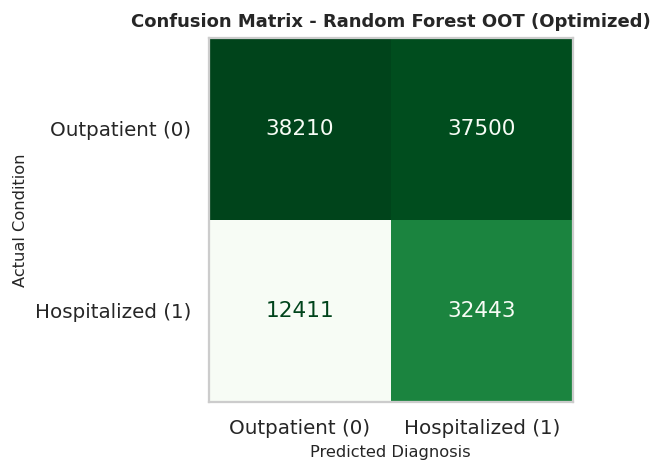

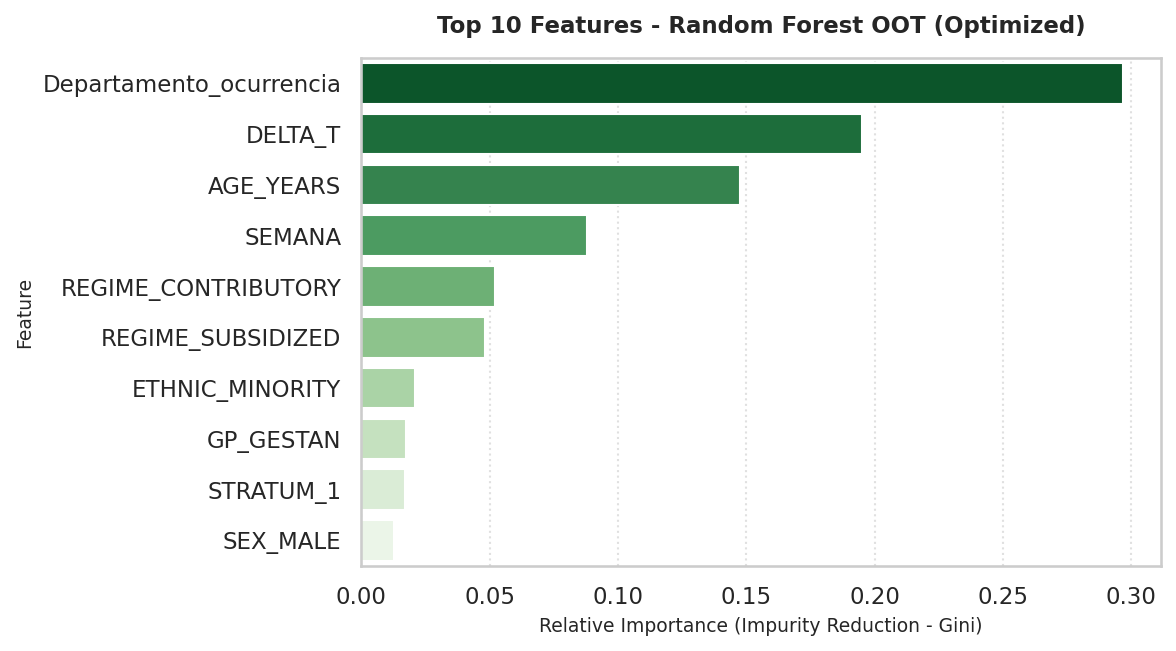

Top 10 Features (Random Forest OOT (Optimized)):
 Departamento_ocurrencia    0.296701
DELTA_T                    0.195115
AGE_YEARS                  0.147650
SEMANA                     0.087904
REGIME_CONTRIBUTORY        0.052156
REGIME_SUBSIDIZED          0.048353
ETHNIC_MINORITY            0.021088
GP_GESTAN                  0.017366
STRATUM_1                  0.016913
SEX_MALE                   0.012965
dtype: float64
---------------------------------------------

=== CLINICAL IMPACT OF HYPERPARAMETER OPTIMIZATION ===


,Recall,False Negatives (FN),True Positives (TP)
Stage,,,
Decision Tree OOT (Base),0.7262,12279,32575
Decision Tree OOT (GridSearchCV),0.7945,9219,35635
Random Forest OOT (Base),0.7204,12542,32312
Random Forest OOT (GridSearchCV),0.7233,12411,32443


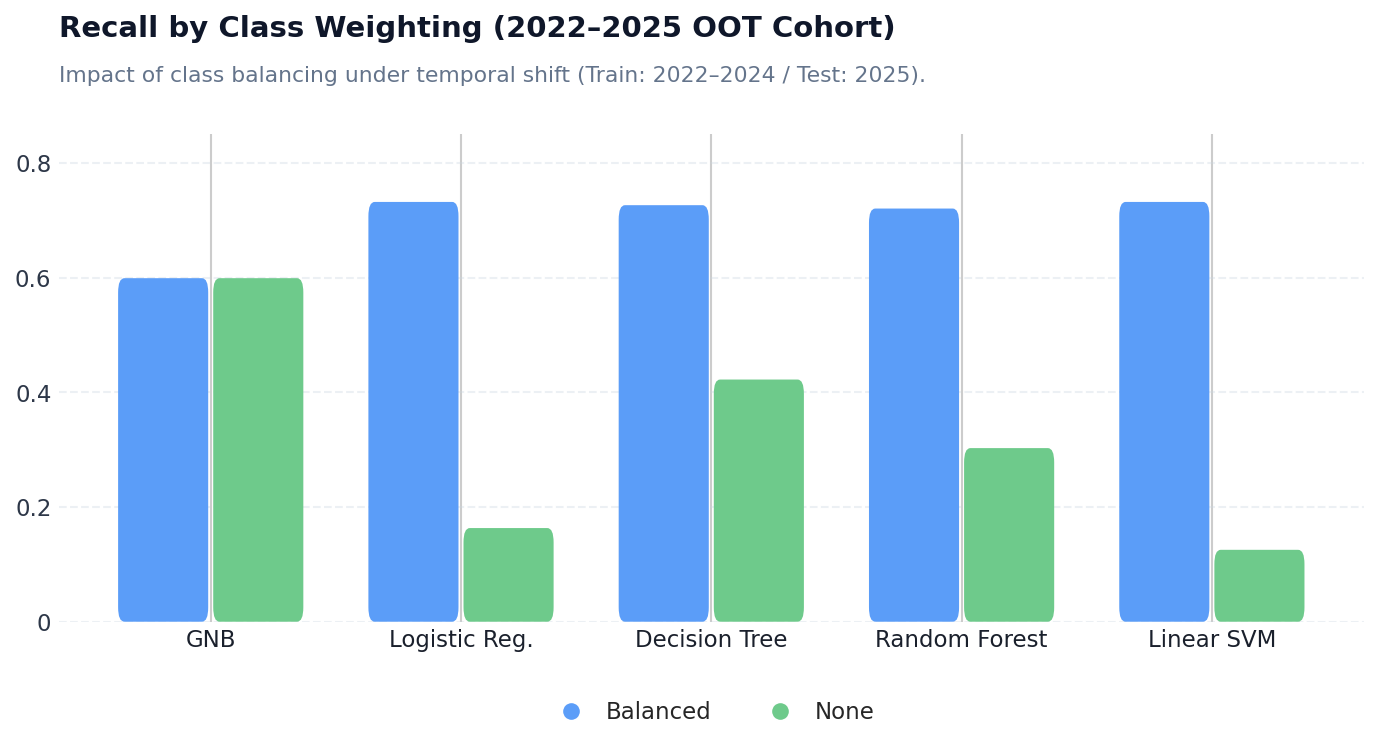

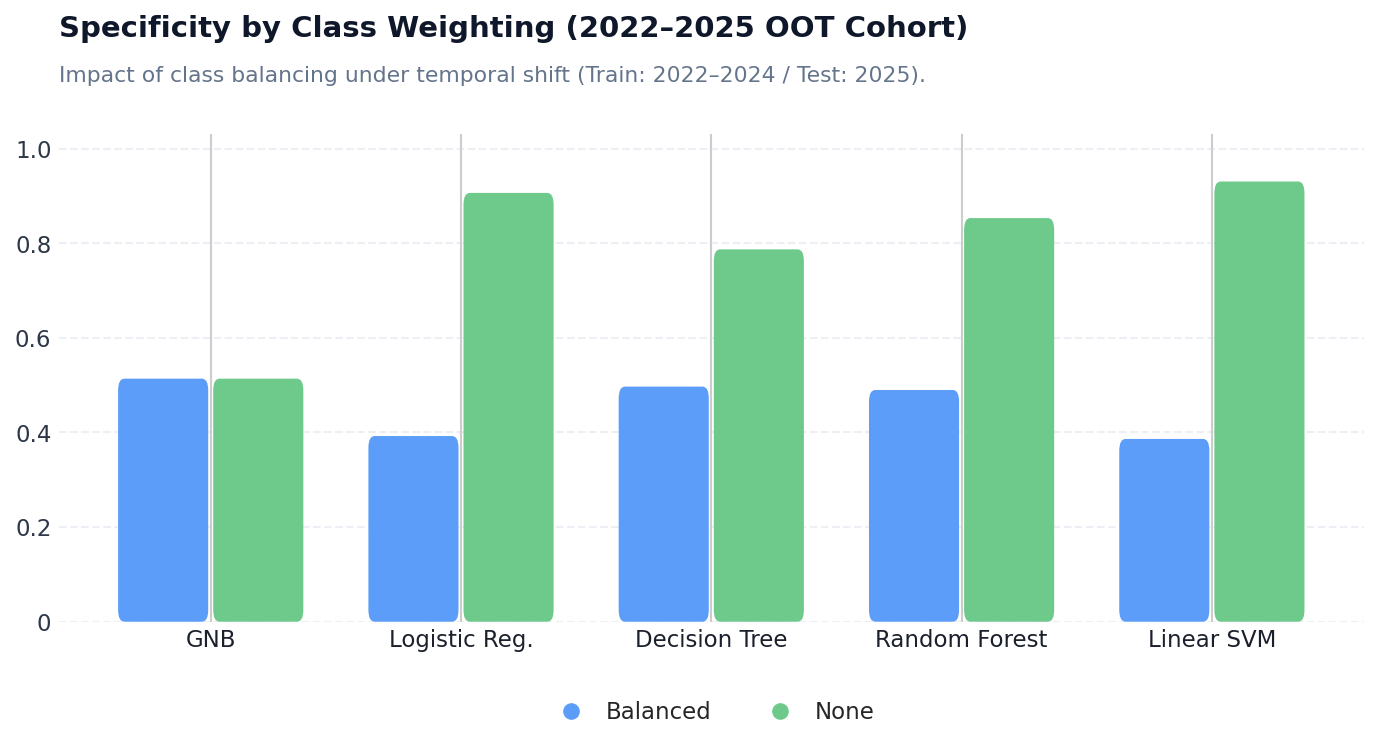

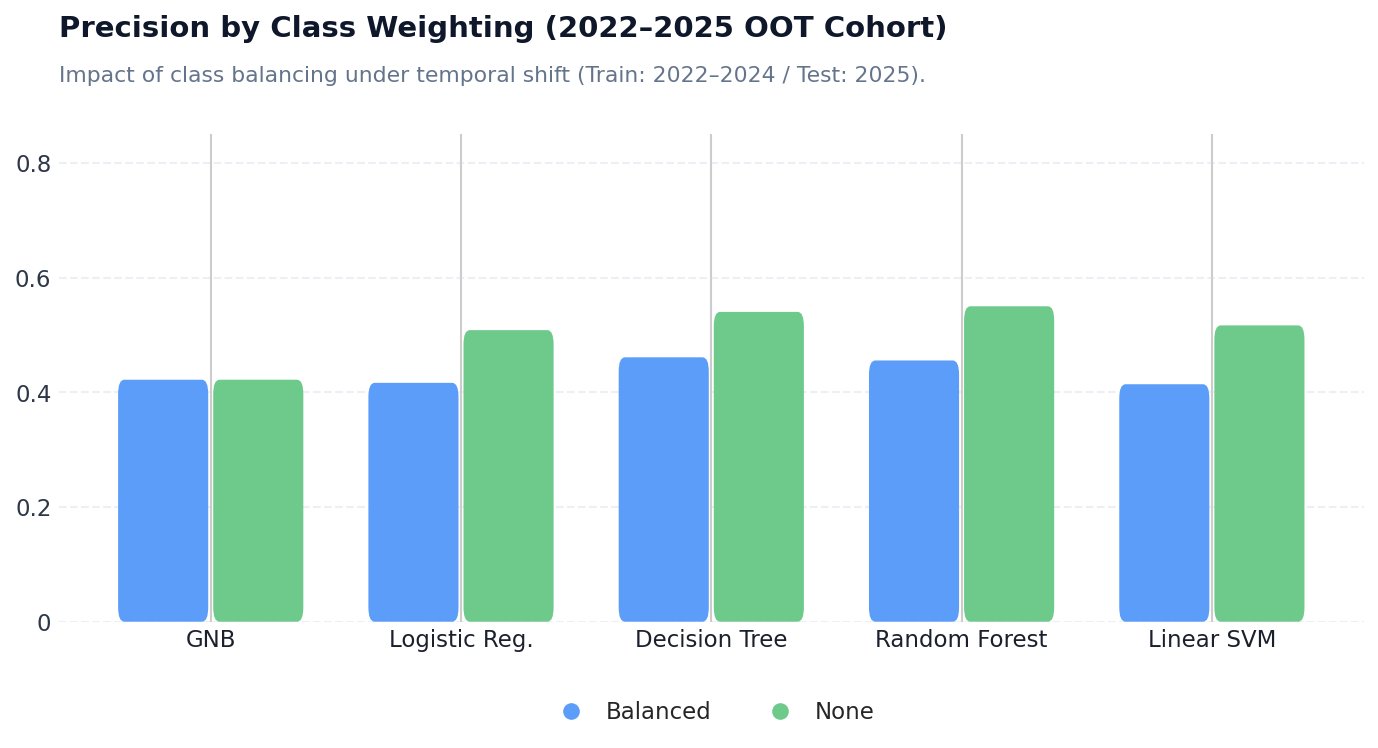

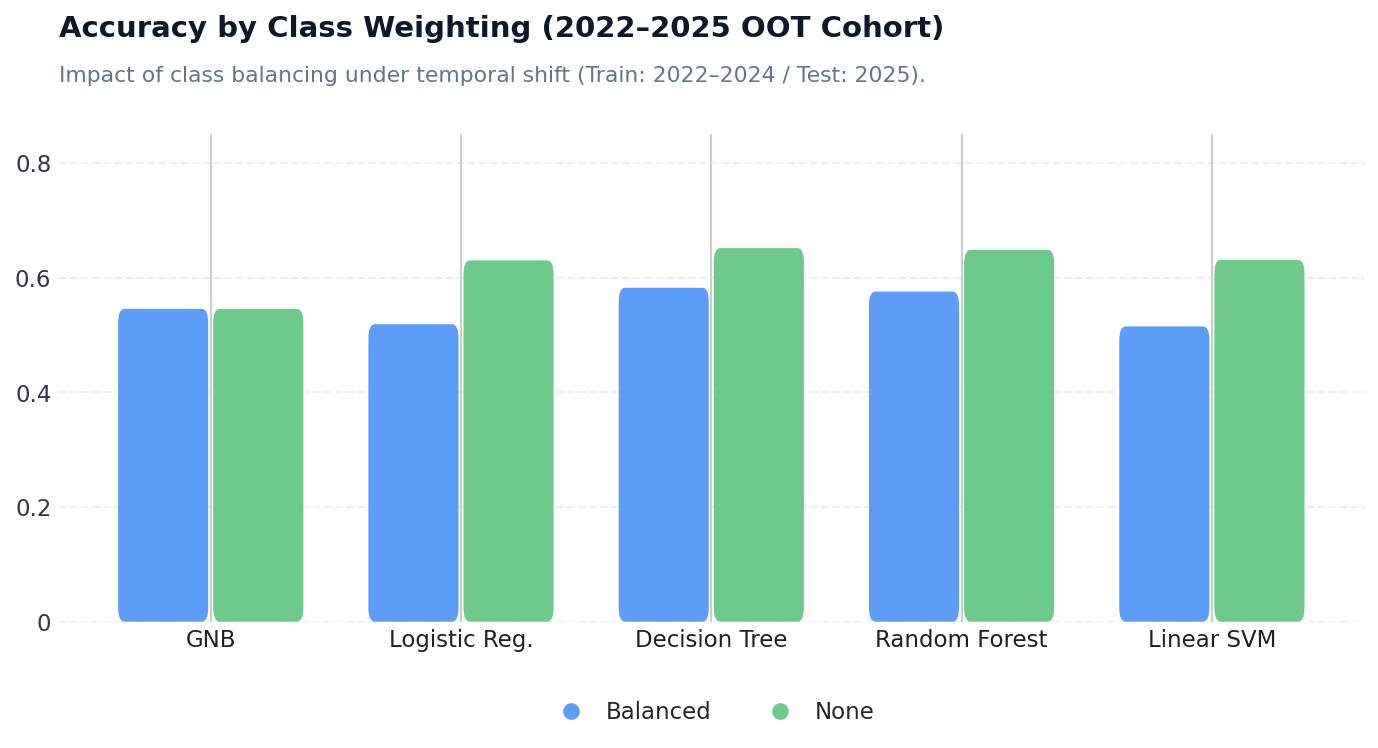

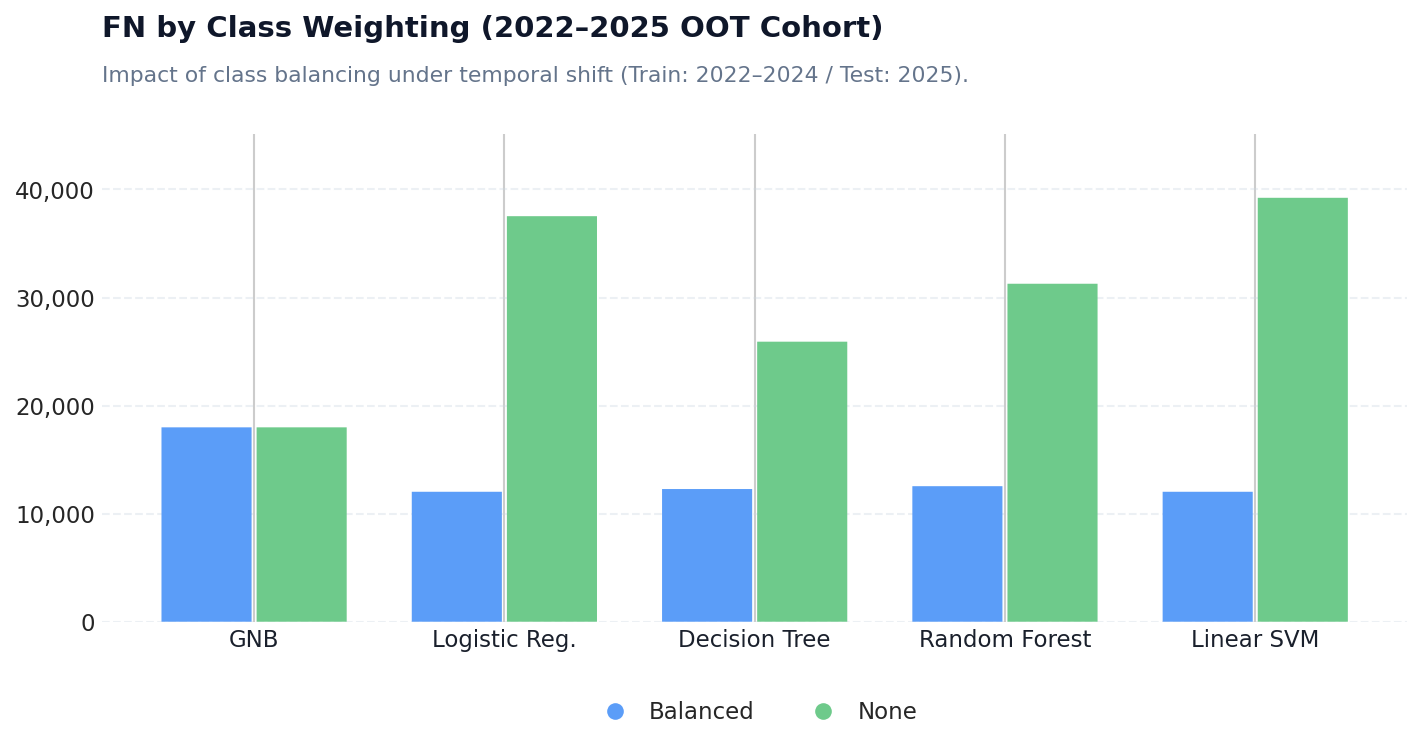

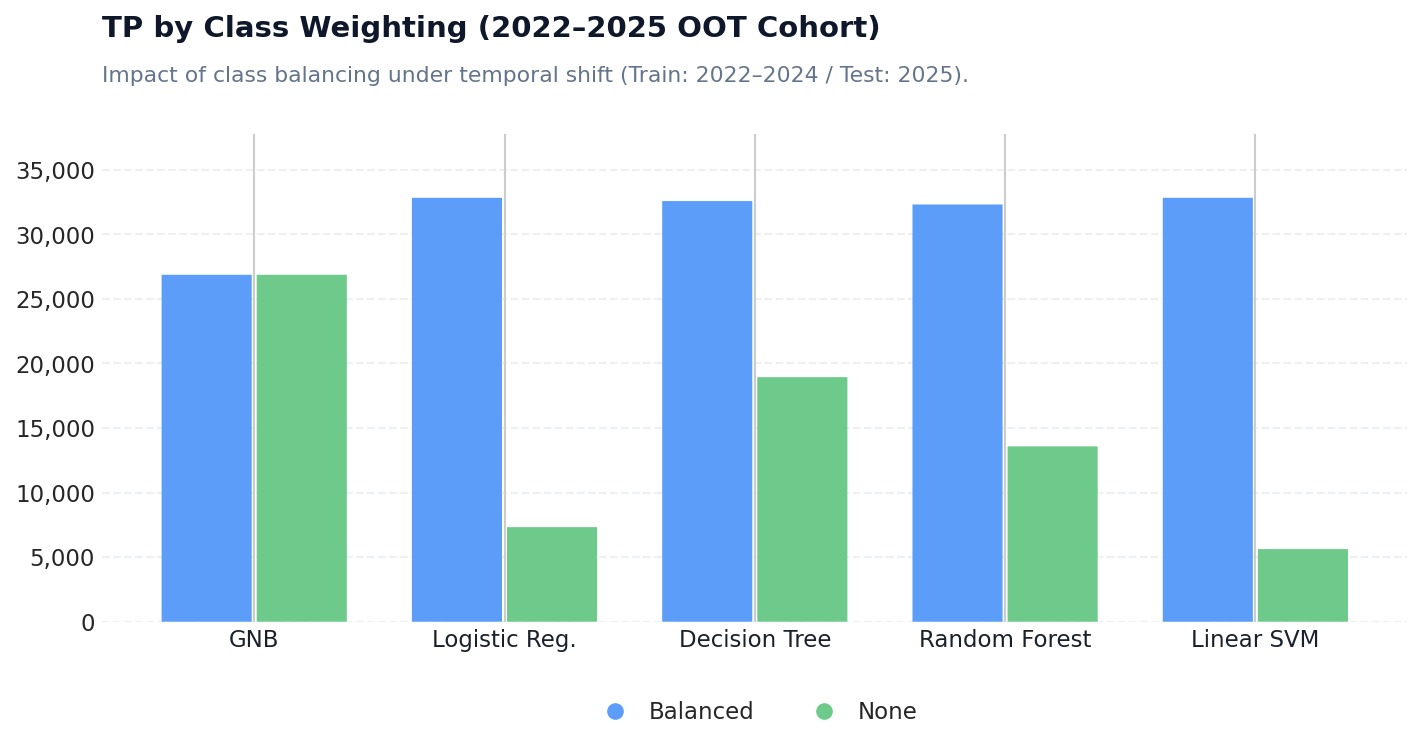

Consolidated 2022–2025 CV records: 622,284 | Prevalence: 39.02%

=== STARTING CROSS-VALIDATION (5 FOLDS): DECISION TREE OPTIMIZED (CONSOLIDATED 2022–2025) | Scale=False ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.6079,0.6047,0.4979,0.6099,19198,29362
Fold 2,0.6066,0.6208,0.4967,0.5976,18413,30146
Fold 3,0.6036,0.6380,0.4938,0.5815,17576,30983
Fold 4,0.6131,0.5870,0.5036,0.6298,20054,28505
Fold 5,0.6054,0.6262,0.4955,0.5922,18153,30406


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.6073,0.6153,0.4975,0.6022,18678.8,29880.4
Std. Dev. (σ),± 0.0036,± 0.0199,± 0.0037,± 0.0185,± 964.9,± 964.8


-----------------------------------------------------------------
=== STARTING CROSS-VALIDATION (5 FOLDS): LOGISTIC REGRESSION (CONSOLIDATED 2022–2025) | Scale=True ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.5693,0.5918,0.4596,0.5548,19821,28739
Fold 2,0.5712,0.5929,0.4615,0.5574,19769,28790
Fold 3,0.5703,0.5940,0.4607,0.5551,19717,28842
Fold 4,0.5700,0.5929,0.4603,0.5553,19766,28793
Fold 5,0.5717,0.5963,0.4621,0.5559,19602,28957


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.5705,0.5936,0.4608,0.5557,19735.0,28824.2
Std. Dev. (σ),± 0.0010,± 0.0017,± 0.0010,± 0.0010,± 83.0,± 82.7


-----------------------------------------------------------------
=== FINAL CROSS-VALIDATION STABILITY COMPARISON (2022–2025) ===


,Recall (μ ± σ),Specificity (μ ± σ),Accuracy (μ ± σ),Precision (μ ± σ),Mean FN / Fold,Mean TP / Fold
Model,,,,,,
Decision Tree (Optimized - Balanced),0.6153 ± 0.0199,0.6022 ± 0.0185,0.6073 ± 0.0036,0.4975 ± 0.0037,"18,679","29,880"
Logistic Regression (Balanced),0.5936 ± 0.0017,0.5557 ± 0.0010,0.5705 ± 0.0010,0.4608 ± 0.0010,"19,735","28,824"


In [ ]:
# ==============================================================================
# 6. EXPERIMENT 2: TEMPORAL GENERALIZATION OUT-OF-TIME (2022-2024 -> 2025)
# ==============================================================================

# 6.1 Temporal Split (Historical Training vs. Future 2025 Test)
train_hist_df = pd.concat([working_2022, working_2023, working_2024], ignore_index=True)

y_tr_oot = train_hist_df['PAC_HOS'].copy()
x_tr_oot = train_hist_df.drop(columns=['PAC_HOS']).copy()

y_te_oot = working_2025['PAC_HOS'].copy()
x_te_oot = working_2025.drop(columns=['PAC_HOS']).copy()

print(f"OOT Train (2022-2024): {x_tr_oot.shape} | OOT Test (2025): {x_te_oot.shape}")

# 6.2 Leakage-Free Frequency Encoding & Scaling (Fitted strictly on 2022-2024)
for col in ['Departamento_ocurrencia', 'SEMANA']:
    freqs_hist = x_tr_oot[col].value_counts(normalize=True)
    x_tr_oot[col] = x_tr_oot[col].map(freqs_hist).fillna(0).astype('float64')
    x_te_oot[col] = x_te_oot[col].map(freqs_hist).fillna(0).astype('float64')

scaler_oot = StandardScaler()
x_tr_oot_s = scaler_oot.fit_transform(x_tr_oot)
x_te_oot_s = scaler_oot.transform(x_te_oot)

# ------------------------------------------------------------------------------
# 6.3 OOT Baseline Suites (Balanced vs. None)
# ------------------------------------------------------------------------------
suite_bal_oot = build_model_suite(
    x_tr_oot, x_te_oot, x_tr_oot_s, x_te_oot_s, class_weight='balanced'
)
preds_bal_oot = train_model_suite(suite_bal_oot, y_tr_oot)

df_comp_bal_oot = generate_consolidated_report(
    predictions=preds_bal_oot,
    y_test=y_te_oot,
    title='Temporal Generalization OOT (2022-2024 -> 2025 | Balanced)',
    ncols=3,
)

suite_none_oot = build_model_suite(
    x_tr_oot, x_te_oot, x_tr_oot_s, x_te_oot_s, class_weight=None
)
preds_none_oot = train_model_suite(suite_none_oot, y_tr_oot)

df_comp_none_oot = generate_consolidated_report(
    predictions=preds_none_oot,
    y_test=y_te_oot,
    title='Temporal Generalization OOT (2022-2024 -> 2025 | Unweighted)',
    ncols=3,
)

# ------------------------------------------------------------------------------
# 6.4 OOT Hyperparameter Optimization (GridSearchCV)
# ------------------------------------------------------------------------------
best_dt_oot, pred_dt_opt_oot, _ = run_grid_search(
    name='Decision Tree OOT',
    base_estimator=DecisionTreeClassifier(random_state=SEED),
    param_grid=param_grid_dt,
    x_tr=x_tr_oot,
    y_tr=y_tr_oot,
    x_te=x_te_oot,
    y_te=y_te_oot,
    cmap='Blues',
)
plot_feature_importance(best_dt_oot, x_tr_oot.columns, "Decision Tree OOT (Optimized)", palette="Blues_r")

best_rf_oot, pred_rf_opt_oot, _ = run_grid_search(
    name='Random Forest OOT',
    base_estimator=RandomForestClassifier(random_state=SEED, n_jobs=-1),
    param_grid=param_grid_rf,
    x_tr=x_tr_oot,
    y_tr=y_tr_oot,
    x_te=x_te_oot,
    y_te=y_te_oot,
    cmap='Greens',
)
plot_feature_importance(best_rf_oot, x_tr_oot.columns, "Random Forest OOT (Optimized)", palette="Greens_r")

df_impact_oot = report_optimization_impact(
    comparisons=[
        ('Decision Tree OOT (Base)', preds_bal_oot['Decision Tree']),
        ('Decision Tree OOT (GridSearchCV)', pred_dt_opt_oot),
        ('Random Forest OOT (Base)', preds_bal_oot['Random Forest']),
        ('Random Forest OOT (GridSearchCV)', pred_rf_opt_oot),
    ],
    y_test=y_te_oot,
)

# Grouped bar comparison across 2022-2025 cohort
for metric in metrics_to_plot:
    plot_balanced_vs_none(
        df_balanced=df_comp_bal_oot,
        df_none=df_comp_none_oot,
        metric=metric,
        title=f"{metric} by Class Weighting (2022–2025 OOT Cohort)",
        subtitle="Impact of class balancing under temporal shift (Train: 2022–2024 / Test: 2025).",
    )

# ------------------------------------------------------------------------------
# 6.5 Consolidated 5-Fold Cross-Validation (Full 2022-2025 Horizon)
# ------------------------------------------------------------------------------
full_2022_2025_df = pd.concat(
    [working_2022, working_2023, working_2024, working_2025], ignore_index=True
)
y_full_cv = full_2022_2025_df['PAC_HOS'].copy()
x_full_cv = full_2022_2025_df.drop(columns=['PAC_HOS']).copy()

print(f"Consolidated 2022–2025 CV records: {x_full_cv.shape[0]:,} | Prevalence: {(y_full_cv.mean() * 100):.2f}%\n")

# Optimized Decision Tree (depth=6, entropy, balanced)
model_dt_opt_cv = DecisionTreeClassifier(
    max_depth=6, criterion='entropy', class_weight='balanced', random_state=SEED
)
df_folds_dt_cv, df_res_dt_cv = run_stratified_cv(
    name='Decision Tree Optimized (Consolidated 2022–2025)',
    model=model_dt_opt_cv,
    X=x_full_cv,
    y=y_full_cv,
    n_splits=5,
    scale=False,
)

# Logistic Regression (balanced + fold-isolated scaling)
model_lr_cv = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)
df_folds_lr_cv, df_res_lr_cv = run_stratified_cv(
    name='Logistic Regression (Consolidated 2022–2025)',
    model=model_lr_cv,
    X=x_full_cv,
    y=y_full_cv,
    n_splits=5,
    scale=True,
)

# Final Cross-Validation Stability Summary Table
cv_stability_summary = pd.DataFrame([
    {
        'Model': 'Decision Tree (Optimized - Balanced)',
        'Recall (μ ± σ)': f"{df_folds_dt_cv['Recall'].mean():.4f} ± {df_folds_dt_cv['Recall'].std():.4f}",
        'Specificity (μ ± σ)': f"{df_folds_dt_cv['Specificity'].mean():.4f} ± {df_folds_dt_cv['Specificity'].std():.4f}",
        'Accuracy (μ ± σ)': f"{df_folds_dt_cv['Accuracy'].mean():.4f} ± {df_folds_dt_cv['Accuracy'].std():.4f}",
        'Precision (μ ± σ)': f"{df_folds_dt_cv['Precision'].mean():.4f} ± {df_folds_dt_cv['Precision'].std():.4f}",
        'Mean FN / Fold': f"{int(round(df_folds_dt_cv['FN'].mean())):,}",
        'Mean TP / Fold': f"{int(round(df_folds_dt_cv['TP'].mean())):,}",
    },
    {
        'Model': 'Logistic Regression (Balanced)',
        'Recall (μ ± σ)': f"{df_folds_lr_cv['Recall'].mean():.4f} ± {df_folds_lr_cv['Recall'].std():.4f}",
        'Specificity (μ ± σ)': f"{df_folds_lr_cv['Specificity'].mean():.4f} ± {df_folds_lr_cv['Specificity'].std():.4f}",
        'Accuracy (μ ± σ)': f"{df_folds_lr_cv['Accuracy'].mean():.4f} ± {df_folds_lr_cv['Accuracy'].std():.4f}",
        'Precision (μ ± σ)': f"{df_folds_lr_cv['Precision'].mean():.4f} ± {df_folds_lr_cv['Precision'].std():.4f}",
        'Mean FN / Fold': f"{int(round(df_folds_lr_cv['FN'].mean())):,}",
        'Mean TP / Fold': f"{int(round(df_folds_lr_cv['TP'].mean())):,}",
    },
]).set_index('Model')

print("=== FINAL CROSS-VALIDATION STABILITY COMPARISON (2022–2025) ===")
display(cv_stability_summary)

# **Section 7: Experiment 3 — Clinical Cohort with Symptoms and Warning Signs**

Symptoms Train shape: (37668, 28) | Test shape: (16144, 28)
=== GAUSSIAN NAIVE BAYES (SYMPTOMS) ===
Accuracy:            0.8188
Recall (Sensitivity): 0.3786
Precision:           0.6096
Specificity:         0.9356
False Negatives (FN): 2,104
True Positives (TP):  1,282
---------------------------------------------
=== LOGISTIC REGRESSION (SYMPTOMS) ===
Accuracy:            0.7475
Recall (Sensitivity): 0.6081
Precision:           0.4282
Specificity:         0.7844
False Negatives (FN): 1,327
True Positives (TP):  2,059
---------------------------------------------
=== DECISION TREE (SYMPTOMS) ===
Accuracy:            0.7520
Recall (Sensitivity): 0.6223
Precision:           0.4361
Specificity:         0.7864
False Negatives (FN): 1,279
True Positives (TP):  2,107
---------------------------------------------
=== RANDOM FOREST (SYMPTOMS) ===
Accuracy:            0.7786
Recall (Sensitivity): 0.5877
Precision:           0.4774
Specificity:         0.8293
False Negatives (FN): 1,396
True Posi

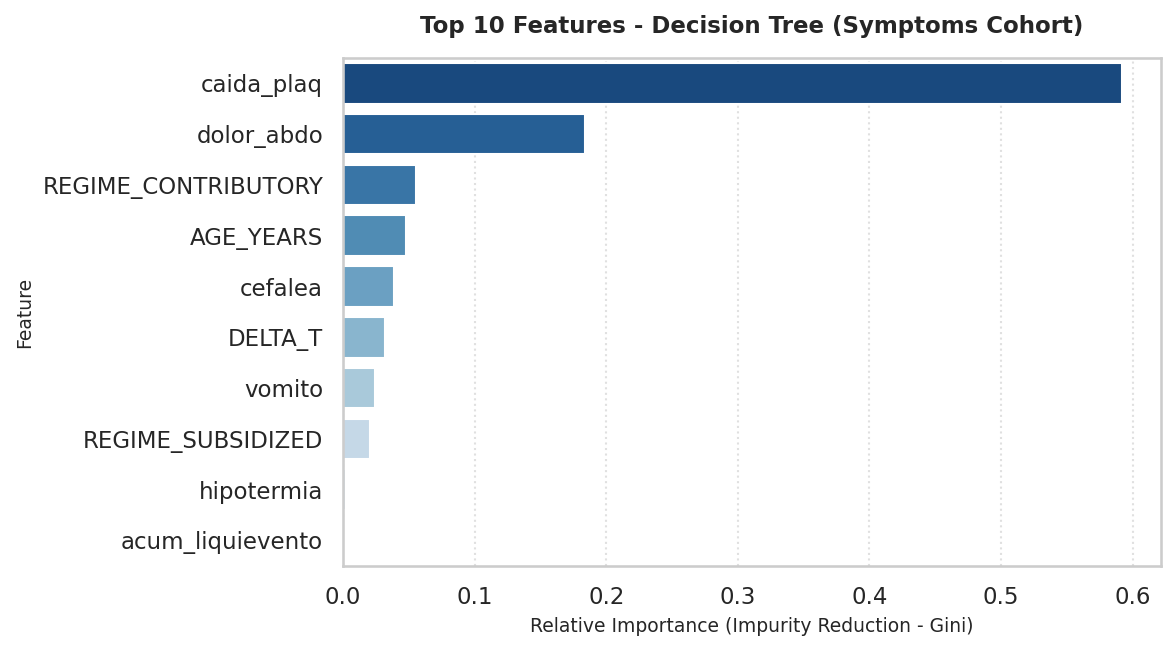

Top 10 Features (Decision Tree (Symptoms Cohort)):
 caida_plaq             0.591973
dolor_abdo             0.184209
REGIME_CONTRIBUTORY    0.055771
AGE_YEARS              0.048107
cefalea                0.038648
DELTA_T                0.031853
vomito                 0.024618
REGIME_SUBSIDIZED      0.020383
hipotermia             0.002554
acum_liquievento       0.000936
dtype: float64
---------------------------------------------


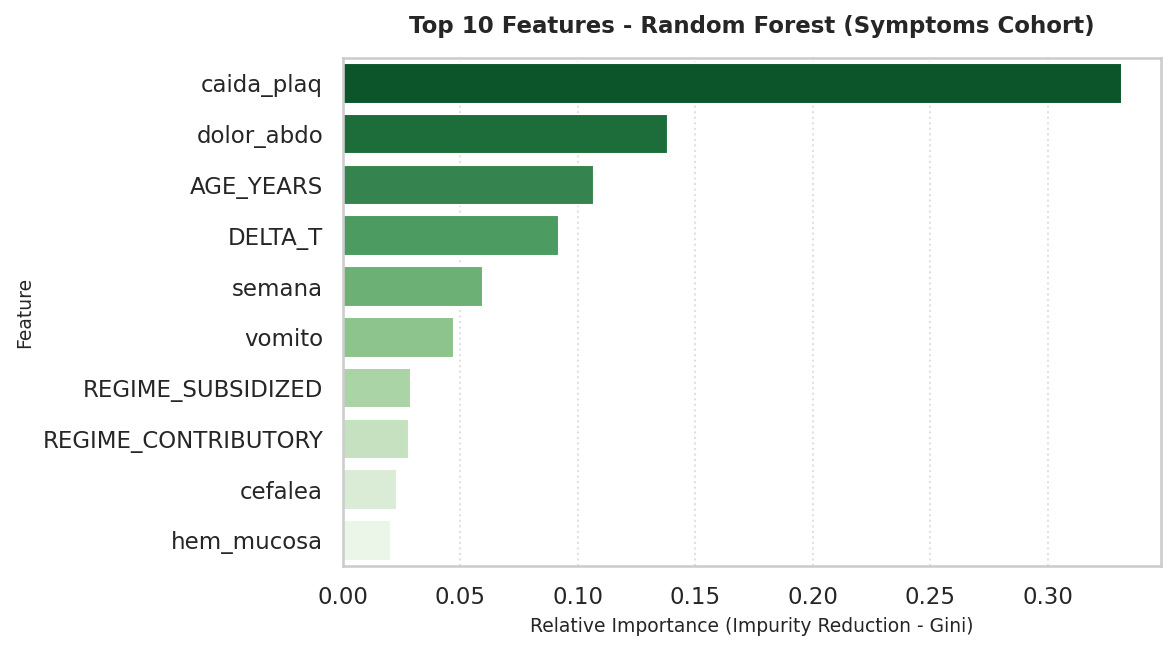

Top 10 Features (Random Forest (Symptoms Cohort)):
 caida_plaq             0.331592
dolor_abdo             0.138144
AGE_YEARS              0.106903
DELTA_T                0.092022
semana                 0.059388
vomito                 0.047084
REGIME_SUBSIDIZED      0.028809
REGIME_CONTRIBUTORY    0.028222
cefalea                0.023102
hem_mucosa             0.020428
dtype: float64
---------------------------------------------
=== DECISION TREE REDUCED (TOP 10 FEATURES) ===
Accuracy:            0.7519
Recall (Sensitivity): 0.6220
Precision:           0.4359
Specificity:         0.7864
False Negatives (FN): 1,280
True Positives (TP):  2,106
---------------------------------------------


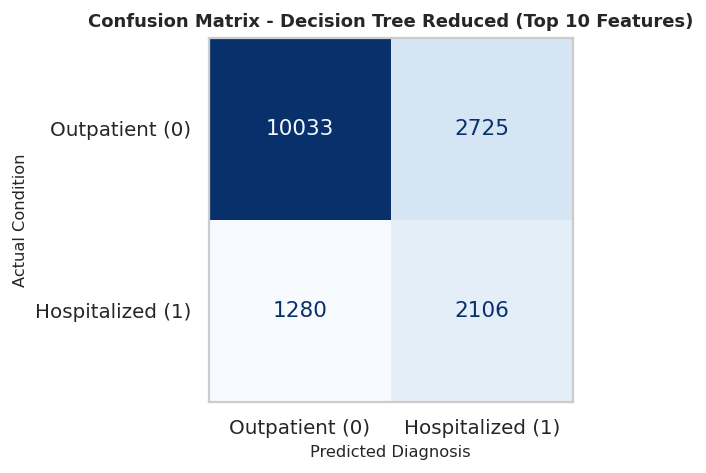

Computed DNN balanced class weights: {0: 0.6327, 1: 2.3841}

=== RANDOMIZEDSEARCHCV BEST RF PARAMS (SYMPTOMS) ===
Best parameters: {'n_estimators': 70, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 8}
Best CV Recall:  0.6258

=== CLINICAL SYMPTOMS COHORT - GLOBAL MODEL COMPARISON ===



,Accuracy,Recall,Precision,Specificity,FN,TP
Model,,,,,,
Gaussian Naive Bayes,0.8188,0.3786,0.6096,0.9356,2104,1282
Logistic Regression,0.7475,0.6081,0.4282,0.7844,1327,2059
Decision Tree,0.7520,0.6223,0.4361,0.7864,1279,2107
Random Forest,0.7786,0.5877,0.4774,0.8293,1396,1990
SVM (RBF),0.7650,0.6066,0.4548,0.8070,1332,2054
SVM (Sigmoid),0.6101,0.5969,0.2908,0.6137,1365,2021
SVM (Poly),0.7698,0.5650,0.4603,0.8242,1473,1913
SVM (Linear),0.7502,0.6007,0.4315,0.7899,1352,2034
Deep Neural Network (MLP),0.7407,0.6370,0.4218,0.7682,1229,2157


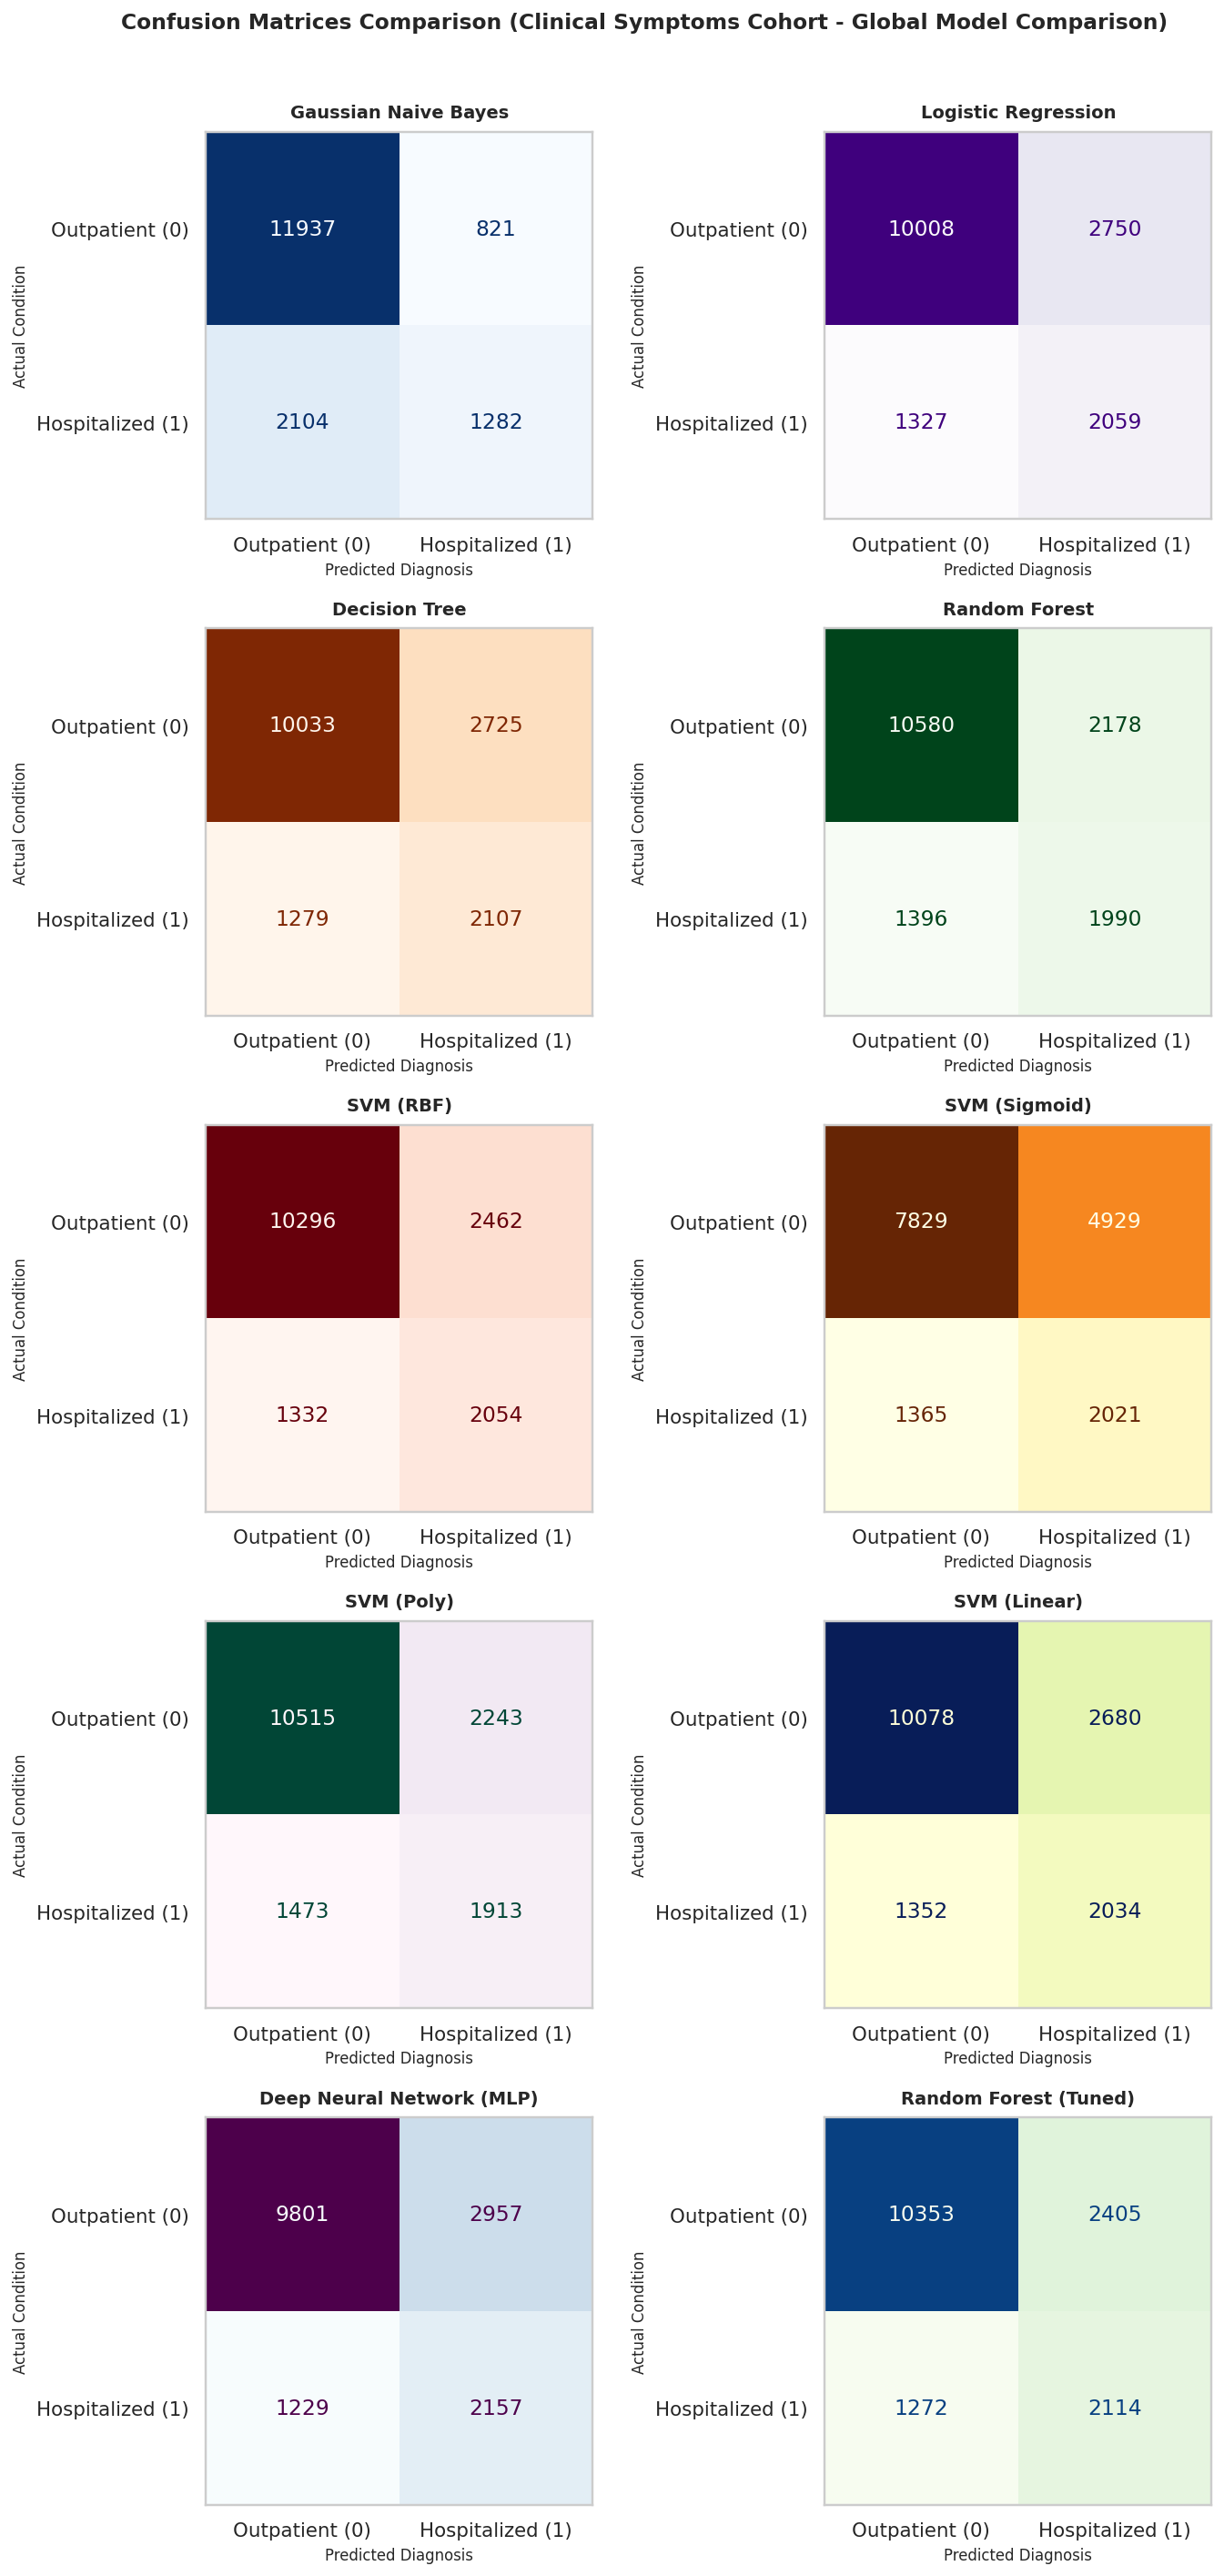

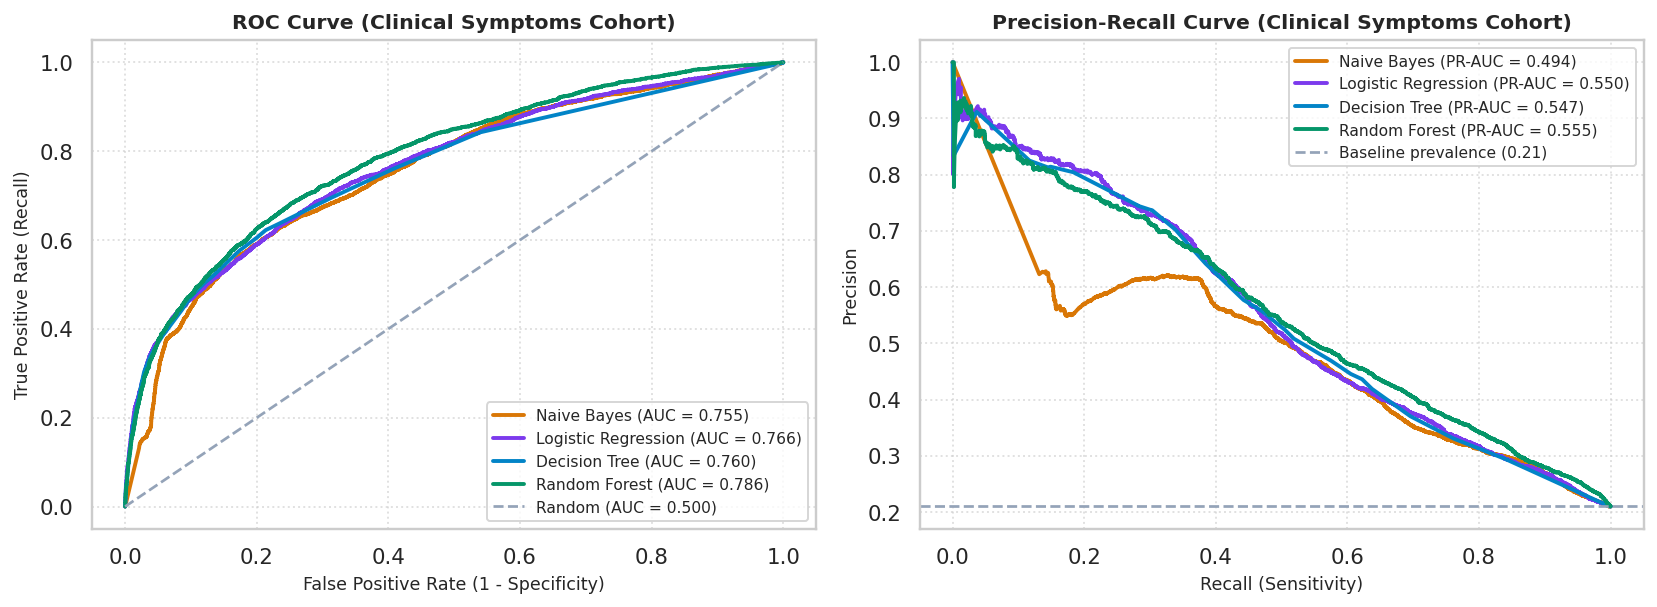

=== STARTING CROSS-VALIDATION (5 FOLDS): RANDOM FOREST (SYMPTOMS COHORT) | Scale=False ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.7808,0.6050,0.4822,0.8275,892,1366
Fold 2,0.7733,0.5826,0.4675,0.8239,942,1315
Fold 3,0.7778,0.5902,0.4761,0.8276,925,1332
Fold 4,0.7804,0.5995,0.4812,0.8285,904,1353
Fold 5,0.7850,0.5986,0.4897,0.8345,906,1351


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.7795,0.5952,0.4793,0.8284,913.8,1343.4
Std. Dev. (σ),± 0.0043,± 0.0088,± 0.0082,± 0.0038,± 19.7,± 20.0


-----------------------------------------------------------------
=== STARTING CROSS-VALIDATION (5 FOLDS): LOGISTIC REGRESSION (SYMPTOMS COHORT) | Scale=True ===


,Accuracy,Recall,Precision,Specificity,FN,TP
Fold,,,,,,
Fold 1,0.7538,0.6196,0.4386,0.7894,859,1399
Fold 2,0.7502,0.6070,0.4319,0.7881,887,1370
Fold 3,0.7491,0.6123,0.4309,0.7854,875,1382
Fold 4,0.7559,0.6190,0.4415,0.7922,860,1397
Fold 5,0.7544,0.6141,0.4389,0.7917,871,1386


,Accuracy,Recall,Precision,Specificity,FN,TP
Metric,,,,,,
Mean (μ),0.7527,0.6144,0.4364,0.7894,870.4,1386.8
Std. Dev. (σ),± 0.0029,± 0.0052,± 0.0047,± 0.0028,± 11.6,± 11.8


-----------------------------------------------------------------


In [ ]:
# ==============================================================================
# 7. EXPERIMENT 3: CLINICAL SYMPTOMS & WARNING SIGNS COHORT
# ==============================================================================

# 7.1 Train / Test Split (70/30 Stratified) & Isolation
y_sint = working_symptoms['PAC_HOS'].copy()
x_sint = working_symptoms.drop(columns=['PAC_HOS']).copy()

x_tr_sint, x_te_sint, y_tr_sint, y_te_sint = train_test_split(
    x_sint, y_sint, test_size=0.30, random_state=SEED, stratify=y_sint
)

# Frequency encoding for epidemiological week ('semana') fitted on train only
week_freqs = x_tr_sint['semana'].value_counts(normalize=True)
x_tr_sint['semana'] = x_tr_sint['semana'].map(week_freqs).fillna(0).astype('float64')
x_te_sint['semana'] = x_te_sint['semana'].map(week_freqs).fillna(0).astype('float64')

scaler_sint = StandardScaler()
x_tr_sint_s = scaler_sint.fit_transform(x_tr_sint)
x_te_sint_s = scaler_sint.transform(x_te_sint)

print(f"Symptoms Train shape: {x_tr_sint.shape} | Test shape: {x_te_sint.shape}")

# ------------------------------------------------------------------------------
# 7.2 Classical Supervised Classifiers (Balanced)
# ------------------------------------------------------------------------------
models_sint_config = {
    'Gaussian Naive Bayes': (GaussianNB(), x_tr_sint, x_te_sint, 'Blues'),
    'Logistic Regression': (
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
        x_tr_sint_s, x_te_sint_s, 'Purples'
    ),
    'Decision Tree': (
        DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED),
        x_tr_sint, x_te_sint, 'Oranges'
    ),
    'Random Forest': (
        RandomForestClassifier(n_estimators=20, max_depth=12, class_weight='balanced', random_state=SEED, n_jobs=-1),
        x_tr_sint, x_te_sint, 'Greens'
    ),
    'SVM (RBF)': (
        SVC(kernel='rbf', class_weight='balanced', random_state=SEED, cache_size=2000),
        x_tr_sint_s, x_te_sint_s, 'Reds'
    ),
    'SVM (Sigmoid)': (
        SVC(kernel='sigmoid', class_weight='balanced', random_state=SEED, cache_size=2000),
        x_tr_sint_s, x_te_sint_s, 'YlOrBr'
    ),
    'SVM (Poly)': (
        SVC(kernel='poly', class_weight='balanced', random_state=SEED, cache_size=2000),
        x_tr_sint_s, x_te_sint_s, 'PuBuGn'
    ),
    'SVM (Linear)': (
        LinearSVC(class_weight='balanced', random_state=SEED, max_iter=5000, dual=False),
        x_tr_sint_s, x_te_sint_s, 'YlGnBu'
    ),
}

preds_sint = {}
for name, (clf, x_tr_curr, x_te_curr, cmap) in models_sint_config.items():
    preds_sint[name] = evaluate_model(
        name=f"{name} (Symptoms)",
        model=clf,
        x_tr=x_tr_curr,
        y_tr=y_tr_sint,
        x_te=x_te_curr,
        y_te=y_te_sint,
        plot=False,
    )

# ------------------------------------------------------------------------------
# 7.3 Feature Importance & Dimensionality Reduction (Full vs. Top-10 Tree)
# ------------------------------------------------------------------------------
dt_sint_full = models_sint_config['Decision Tree'][0]
rf_sint_full = models_sint_config['Random Forest'][0]

top10_dt_sint = plot_feature_importance(
    dt_sint_full, x_tr_sint.columns, "Decision Tree (Symptoms Cohort)", top_n=10, palette="Blues_r"
)
top10_rf_sint = plot_feature_importance(
    rf_sint_full, x_tr_sint.columns, "Random Forest (Symptoms Cohort)", top_n=10, palette="Greens_r"
)

# Train reduced Decision Tree using only Top-10 clinical features
top10_features_list = top10_dt_sint.index.tolist()
dt_sint_reduced = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED)
pred_dt_sint_reduced = evaluate_model(
    name=f"Decision Tree Reduced (Top {len(top10_features_list)} Features)",
    model=dt_sint_reduced,
    x_tr=x_tr_sint[top10_features_list],
    y_tr=y_tr_sint,
    x_te=x_te_sint[top10_features_list],
    y_te=y_te_sint,
    plot=True,
    cmap='Blues',
)

# ------------------------------------------------------------------------------
# 7.4 Deep Neural Network (MLP) — Architecture, Overfitting & Feature Ablation
# ------------------------------------------------------------------------------

# Compute balanced class weights dynamically from training distribution
unique_classes = np.unique(y_tr_sint)
balanced_weights = compute_class_weight(
    class_weight='balanced', classes=unique_classes, y=y_tr_sint
)
dnn_class_weights = dict(zip(unique_classes, balanced_weights))
print(
    "Computed DNN balanced class weights: "
    f"{ {int(k): round(float(v), 4) for k, v in dnn_class_weights.items()} }\n"
)


def run_dnn_experiment(
    x_tr_mat: np.ndarray,
    y_tr_vec: pd.Series,
    x_te_mat: np.ndarray,
    class_weights: dict,
    epochs: int = 20,
    batch_size: int = 256,
    track_val: bool = False,
    y_te_vec: pd.Series | None = None,
) -> tuple[np.ndarray, tf.keras.callbacks.History]:
    """Train the standardized 5-hidden-layer MLP and return binary predictions and history."""
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(x_tr_mat.shape[1],)),
        tf.keras.layers.Dense(512, activation="relu"),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    fit_kwargs = {
        "x": x_tr_mat,
        "y": y_tr_vec,
        "epochs": epochs,
        "batch_size": batch_size,
        "class_weight": class_weights,
        "verbose": 0,
    }
    if track_val and y_te_vec is not None:
        fit_kwargs["validation_data"] = (x_te_mat, y_te_vec)

    history = model.fit(**fit_kwargs)
    preds = (model.predict(x_te_mat, verbose=0) >= 0.5).astype("int8").ravel()
    return preds, history


# 1. Scenario A: Full Feature Space (20 Epochs - Baseline MLP)
pred_dnn_sint, _ = run_dnn_experiment(
    x_tr_sint_s, y_tr_sint, x_te_sint_s, dnn_class_weights, epochs=20
)
preds_sint['Deep Neural Network (MLP)'] = pred_dnn_sint

# 2. Scenario B: Full Feature Space (1000 Epochs - Overfitting Diagnostic)
pred_dnn_1000, hist_1000 = run_dnn_experiment(
    x_tr_sint_s,
    y_tr_sint,
    x_te_sint_s,
    dnn_class_weights,
    epochs=1000,
    track_val=True,
    y_te_vec=y_te_sint,
)

# Plot Training vs. Validation Learning Curves (Accuracy & Loss across 1000 Epochs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), dpi=130)

axes[0].plot(hist_1000.history["accuracy"], label="Train Accuracy", color="#2563EB", lw=1.5)
axes[0].plot(hist_1000.history["val_accuracy"], label="Validation Accuracy", color="#EA580C", lw=1.5, alpha=0.85)
axes[0].set_title("Accuracy per Epoch (1,000 Epochs)", fontsize=10, weight="bold")
axes[0].set_xlabel("Epochs", fontsize=9)
axes[0].set_ylabel("Accuracy", fontsize=9)
axes[0].legend(fontsize=8.5)
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].plot(hist_1000.history["loss"], label="Train Loss", color="#2563EB", lw=1.5)
axes[1].plot(hist_1000.history["val_loss"], label="Validation Loss", color="#EA580C", lw=1.5, alpha=0.85)
axes[1].set_title("Binary Cross-Entropy Loss (1,000 Epochs)", fontsize=10, weight="bold")
axes[1].set_xlabel("Epochs", fontsize=9)
axes[1].set_ylabel("Loss", fontsize=9)
axes[1].legend(fontsize=8.5)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Deep Neural Network Overfitting Diagnostic (Clinical Symptoms Cohort)", fontsize=11, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 3. Scenario C: Top-10 Random Forest Features (20 Epochs)
rf_top10_cols = top10_rf_sint.index.tolist()
scaler_rf_top10 = StandardScaler()
x_tr_sint_rf10_s = scaler_rf_top10.fit_transform(x_tr_sint[rf_top10_cols])
x_te_sint_rf10_s = scaler_rf_top10.transform(x_te_sint[rf_top10_cols])

pred_dnn_rf10, _ = run_dnn_experiment(
    x_tr_sint_rf10_s, y_tr_sint, x_te_sint_rf10_s, dnn_class_weights, epochs=20
)

# 4. Scenario D: Pure Clinical Symptoms Only (16 Binary Symptoms, 0 Demographics)
pure_symptom_cols = [
    c for c in [
        "fiebre", "cefalea", "dolrretroo", "malgias", "artralgia", "erupcionr",
        "dolor_abdo", "vomito", "somnolenci", "hipotensio", "hepatomeg",
        "hem_mucosa", "hipotermia", "aum_hemato", "caida_plaq", "acum_liquievento"
    ]
    if c in x_tr_sint.columns
]
x_tr_pure_sint = x_tr_sint[pure_symptom_cols].to_numpy(dtype="float32")
x_te_pure_sint = x_te_sint[pure_symptom_cols].to_numpy(dtype="float32")

pred_dnn_pure_sint, _ = run_dnn_experiment(
    x_tr_pure_sint, y_tr_sint, x_te_pure_sint, dnn_class_weights, epochs=20
)

# 5. Scenario E: PCA Dimensionality Reduction (85% Variance, Leakage-Free)
pca_dnn_sint = PCA(n_components=0.85, random_state=SEED)
x_tr_sint_pca85 = pca_dnn_sint.fit_transform(x_tr_sint_s)
x_te_sint_pca85 = pca_dnn_sint.transform(x_te_sint_s)

pred_dnn_pca85, _ = run_dnn_experiment(
    x_tr_sint_pca85, y_tr_sint, x_te_sint_pca85, dnn_class_weights, epochs=20
)

# Consolidated Deep Learning Ablation Report & Confusion Matrices Grid
dnn_ablation_results = {
    f"DNN Full ({x_tr_sint_s.shape[1]} vars | 20 ep.)": pred_dnn_sint,
    f"DNN Full ({x_tr_sint_s.shape[1]} vars | 1000 ep.)": pred_dnn_1000,
    f"DNN Top-10 RF ({len(rf_top10_cols)} vars | 20 ep.)": pred_dnn_rf10,
    f"DNN Pure Symptoms ({len(pure_symptom_cols)} vars | 20 ep.)": pred_dnn_pure_sint,
    f"DNN PCA 85% ({x_tr_sint_pca85.shape[1]} PCs | 20 ep.)": pred_dnn_pca85,
}

df_dnn_ablation_sint = generate_consolidated_report(
    predictions=dnn_ablation_results,
    y_test=y_te_sint,
    title="Deep Learning Ablation Study — Clinical Symptoms Cohort",
    ncols=3,
)

# ------------------------------------------------------------------------------
# 7.5 RandomizedSearchCV Optimization (Clinical Random Forest)
# ------------------------------------------------------------------------------
rf_param_dist = {
    "n_estimators": [20, 30, 50, 70],
    "max_depth": [8, 10, 12, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring="recall",
    cv=3,
    random_state=SEED,
    n_jobs=-1,
)
rf_random_search.fit(x_tr_sint, y_tr_sint)
best_rf_sint = rf_random_search.best_estimator_
preds_sint['Random Forest (Tuned)'] = best_rf_sint.predict(x_te_sint)

print("\n=== RANDOMIZEDSEARCHCV BEST RF PARAMS (SYMPTOMS) ===")
print(f"Best parameters: {rf_random_search.best_params_}")
print(f"Best CV Recall:  {rf_random_search.best_score_:.4f}\n")

# ------------------------------------------------------------------------------
# 7.6 Consolidated Report, ROC / Precision-Recall Curves & 5-Fold CV
# ------------------------------------------------------------------------------
df_comp_sint = generate_consolidated_report(
    predictions=preds_sint,
    y_test=y_te_sint,
    title='Clinical Symptoms Cohort - Global Model Comparison',
    ncols=2,
)

# ROC-AUC and Precision-Recall Curves for probabilistic models
prob_models_sint = {
    "Naive Bayes": (models_sint_config['Gaussian Naive Bayes'][0], x_te_sint),
    "Logistic Regression": (models_sint_config['Logistic Regression'][0], x_te_sint_s),
    "Decision Tree": (dt_sint_full, x_te_sint),
    "Random Forest": (rf_sint_full, x_te_sint),
}
plot_evaluation_curves(
    prob_models=prob_models_sint,
    y_test=y_te_sint,
    title_suffix="(Clinical Symptoms Cohort)",
)

# Stratified 5-Fold Cross-Validation (Raw unencoded x_sint to prevent leakage)
df_folds_rf_sint, df_res_rf_sint = run_stratified_cv(
    name='Random Forest (Symptoms Cohort)',
    model=RandomForestClassifier(
        n_estimators=20, max_depth=12, class_weight='balanced', random_state=SEED, n_jobs=-1
    ),
    X=x_sint,
    y=y_sint,
    n_splits=5,
    scale=False,
)

df_folds_lr_sint, df_res_lr_sint = run_stratified_cv(
    name='Logistic Regression (Symptoms Cohort)',
    model=LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    X=x_sint,
    y=y_sint,
    n_splits=5,
    scale=True,
)

# **Section 8: Experiment 4: Dimensionality Reduction & Unsupervised Learning**

=== DIMENSIONALITY REDUCTION (PCA vs. t-SNE): 2025 SOCIODEMOGRAPHIC COHORT ===
• Original dimensions: 34
• Variance explained by first 2 PCs: 14.96%
• Components for >=90% variance: 26 (90.97%)


,Top PC1 Feature,PC1 Loading,Top PC2 Feature,PC2 Loading
0,REGIME_SUBSIDIZED,0.437,GP_OTROS,0.647
1,STRATUM_1,0.437,GP_MIGRANT,-0.477
2,REGIME_CONTRIBUTORY,-0.421,REGIME_UNINSURED,-0.303
3,AREA_URBAN_CORE,-0.338,GP_GESTAN,-0.253
4,AREA_RURAL_DISPERSED,0.273,GP_VIC_VIO,-0.239


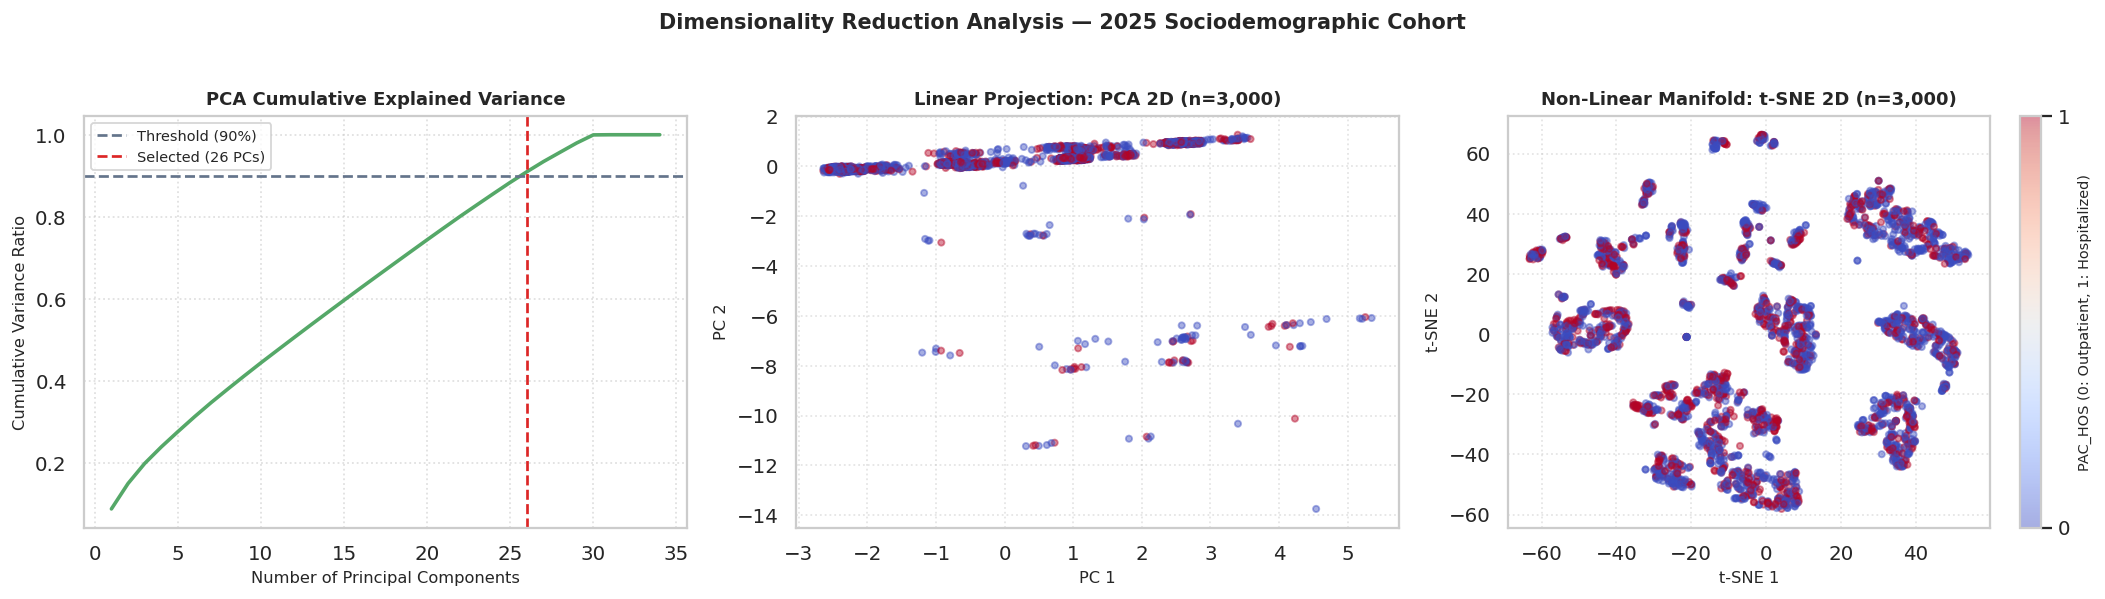


• Selected optimal K = 7 (highest Silhouette score)


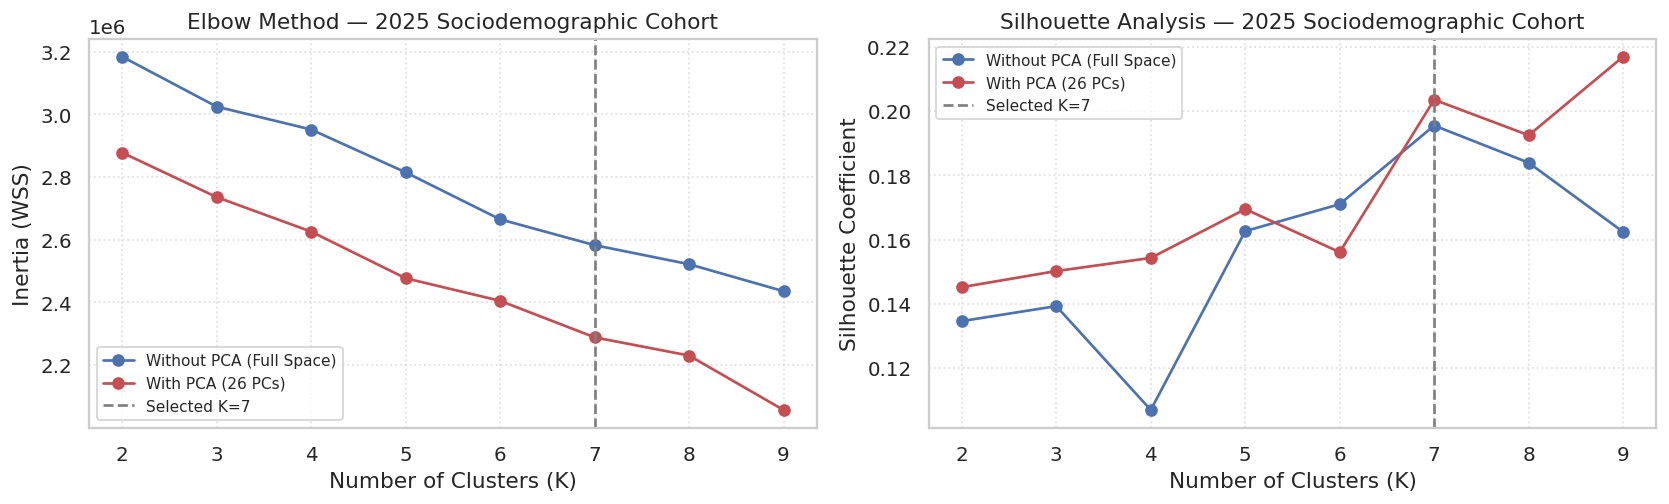


• Agreement between Full vs. PCA clusters (Adjusted Rand Index): 0.3751


,K-Means (Without PCA),K-Means (With PCA)
Dimensions,34.0000,26.0000
Clusters (K),7.0000,7.0000
Silhouette (Native Space),0.1832,0.1967
Training Time (s),2.0823,2.1204


Baseline Hospitalization Rate: 0.3720

--- Cluster Clinical Profile: WITHOUT PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,53823,0.4464,0.3373,23.1711,3.6592
1,14007,0.1162,0.4297,26.8423,3.6867
2,5116,0.0424,0.3851,23.8427,3.6966
3,3263,0.0271,0.2795,24.0293,3.3077
4,42229,0.3503,0.3950,20.0144,3.5718
5,1475,0.0122,0.4536,18.3417,3.8190
6,651,0.0054,0.6882,23.7143,2.5637


--- Cluster Clinical Profile: WITH PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,23106,0.1916,0.3075,24.1626,3.6203
1,8891,0.0737,0.3920,22.1798,3.7978
2,3335,0.0277,0.4081,24.1587,3.4723
3,46543,0.3860,0.4050,19.5582,3.5698
4,210,0.0017,0.4857,26.5903,3.6381
5,14540,0.1206,0.4325,26.7355,3.6698
6,23939,0.1986,0.3201,23.8312,3.6409


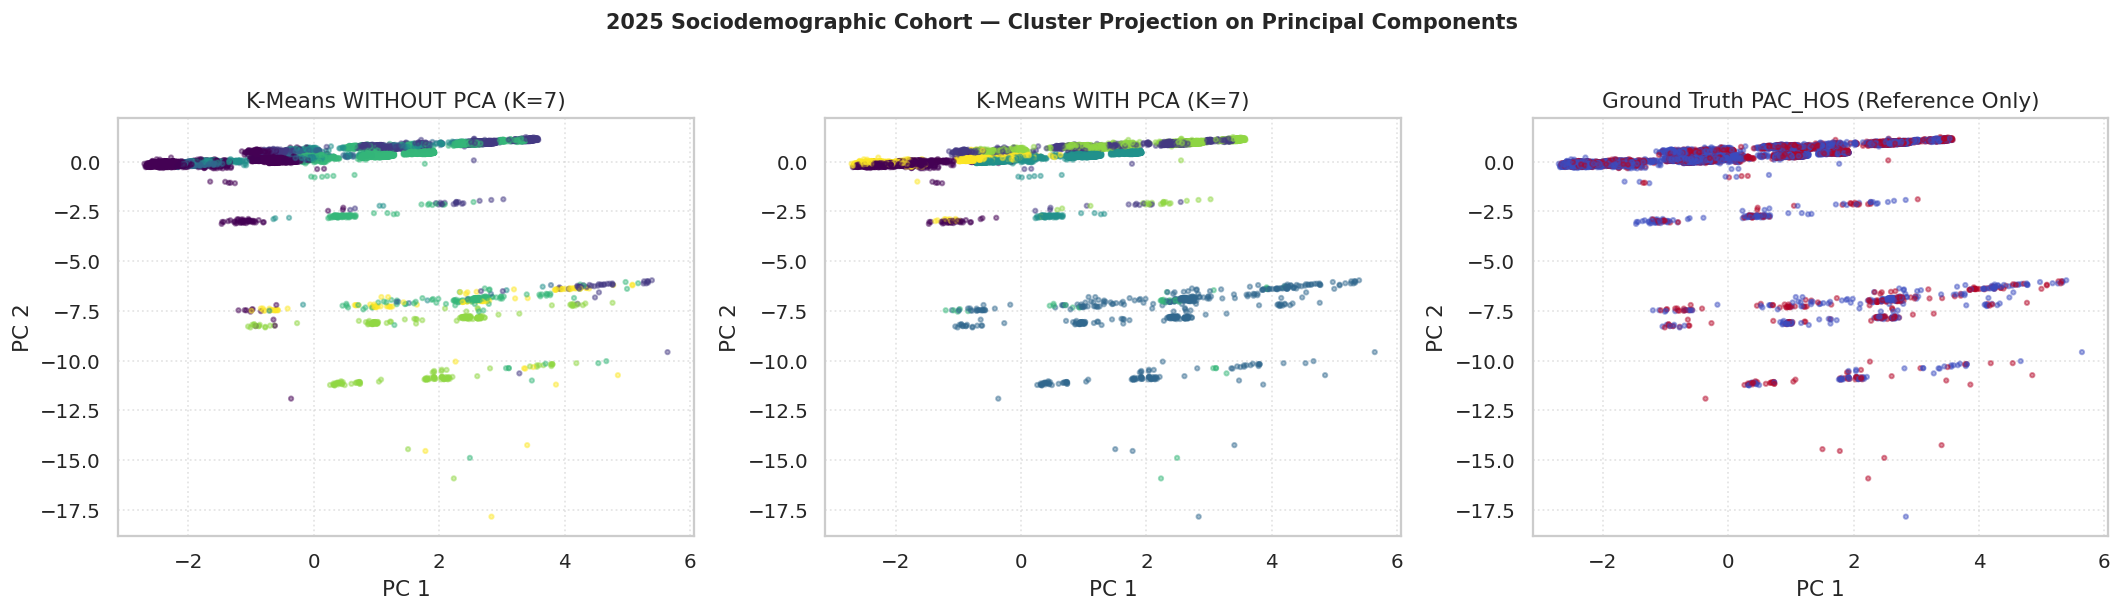

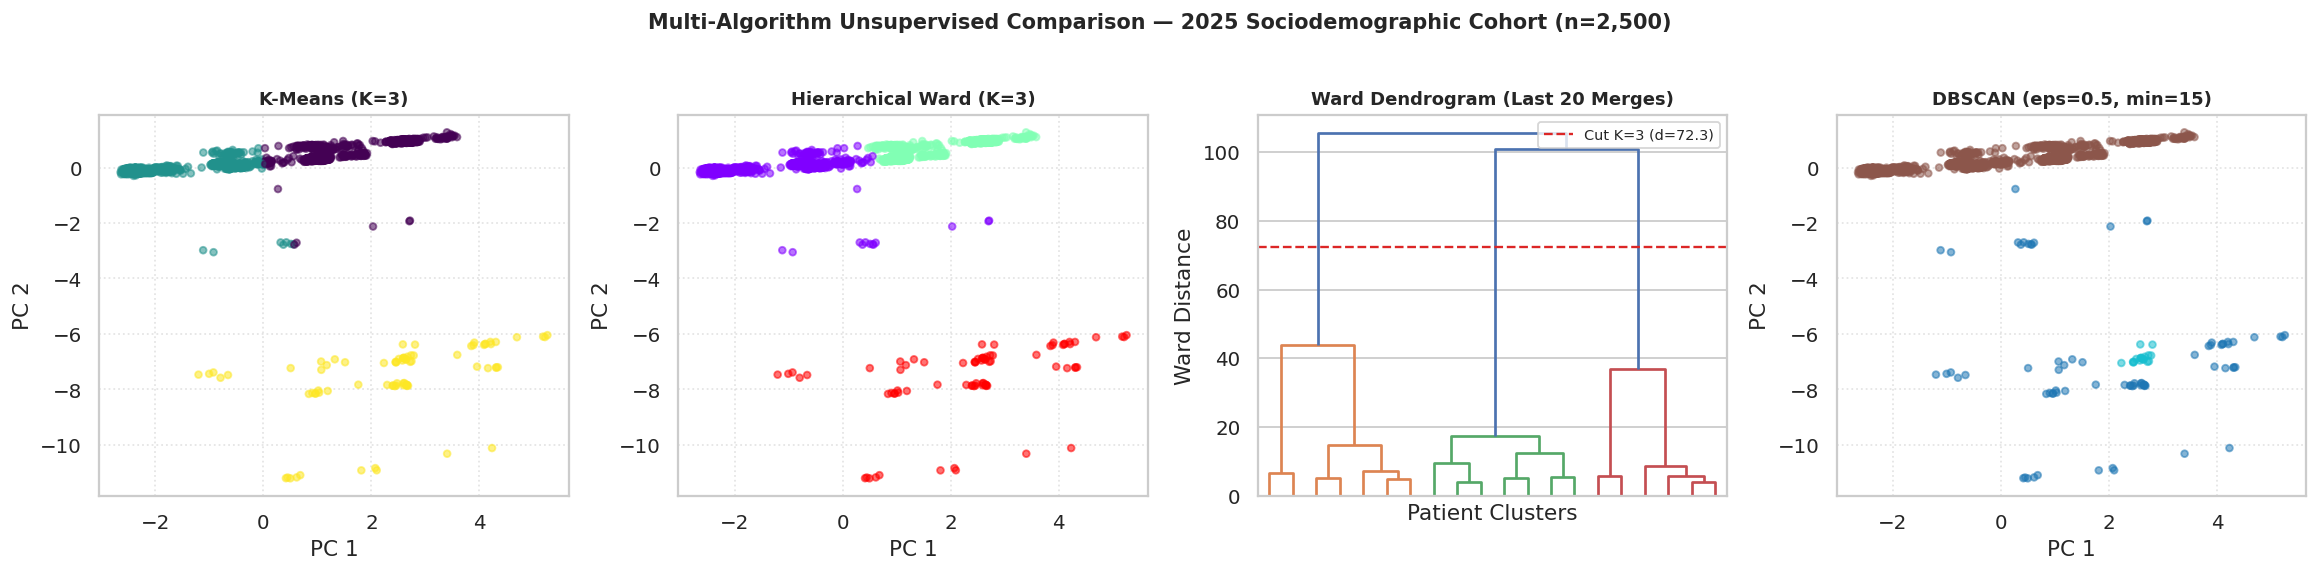


=== UNSUPERVISED ALGORITHMS BENCHMARK (2025 SOCIODEMOGRAPHIC COHORT) ===


,Clusters Found,Noise / Outliers (%),Silhouette Score,ARI vs. PAC_HOS
Algorithm,,,,
K-Means (K=3),3,0.0,0.6596,0.0084
Agglomerative Ward (K=3),3,0.0,0.6541,0.0119
DBSCAN (eps=0.5),2,3.0,0.7487,-0.0006



--- Hospitalization Rate (%) by Hierarchical Cluster ---


,Outpatient (%),Hospitalized (%)
Ward Cluster,,
0,67.39,32.61
1,57.66,42.34
2,61.25,38.75



--- Hospitalization Rate (%) by DBSCAN Cluster (-1 = Noise/Outliers) ---


,Outpatient (%),Hospitalized (%)
DBSCAN Cluster,,
-1,61.33,38.67
0,62.78,37.22
1,72.22,27.78


=== DIMENSIONALITY REDUCTION (PCA vs. t-SNE): CONSOLIDATED 2022–2025 SOCIODEMOGRAPHIC HORIZON ===
• Original dimensions: 34
• Variance explained by first 2 PCs: 15.40%
• Components for >=90% variance: 26 (90.96%)


,Top PC1 Feature,PC1 Loading,Top PC2 Feature,PC2 Loading
0,STRATUM_1,0.426,GP_OTROS,0.630
1,REGIME_SUBSIDIZED,0.418,GP_MIGRANT,-0.481
2,REGIME_CONTRIBUTORY,-0.416,REGIME_UNINSURED,-0.326
3,AREA_URBAN_CORE,-0.332,GP_GESTAN,-0.253
4,AREA_RURAL_DISPERSED,0.274,GP_DESPLAZ,-0.212


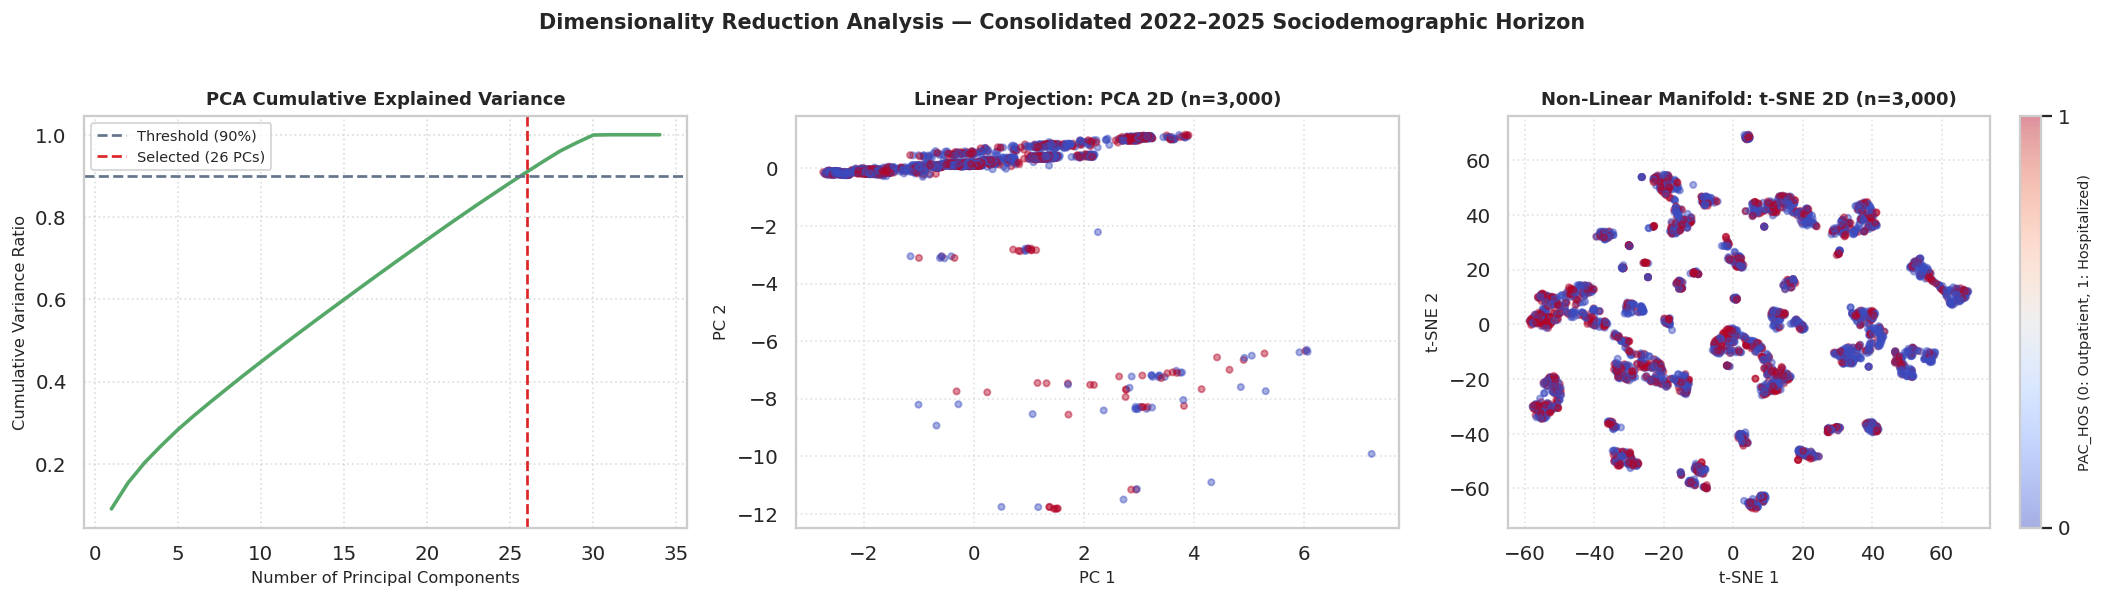


• Selected optimal K = 5 (highest Silhouette score)


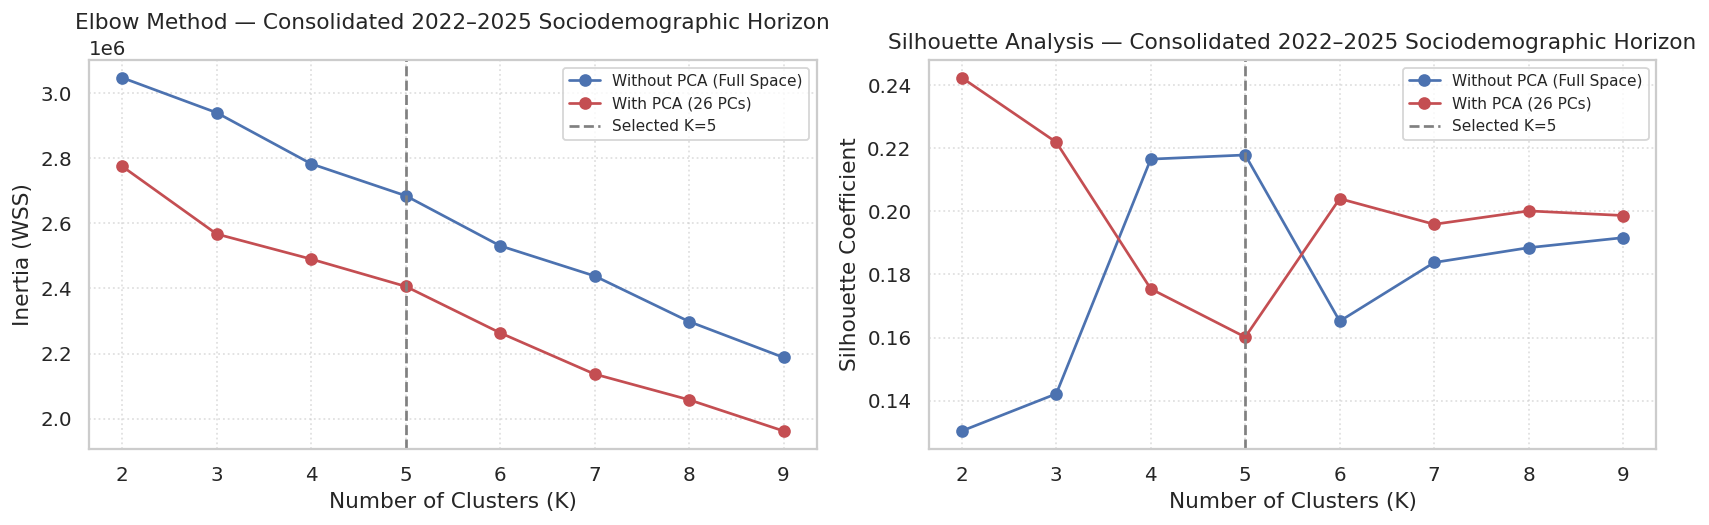


• Agreement between Full vs. PCA clusters (Adjusted Rand Index): 0.8729


,K-Means (Without PCA),K-Means (With PCA)
Dimensions,34.0000,26.0000
Clusters (K),5.0000,5.0000
Silhouette (Native Space),0.1871,0.1606
Training Time (s),9.9598,7.1961


Baseline Hospitalization Rate: 0.3902

--- Cluster Clinical Profile: WITHOUT PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,40975,0.0658,0.4220,23.6631,3.8299
1,245931,0.3952,0.3273,25.2277,3.6831
2,66871,0.1075,0.4250,27.0869,3.7016
3,25768,0.0414,0.3989,23.9094,3.7894
4,242739,0.3901,0.4380,19.8994,3.6415


--- Cluster Clinical Profile: WITH PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,239905,0.3855,0.4382,19.9604,3.6391
1,264525,0.4251,0.3307,25.1405,3.6895
2,6817,0.0110,0.4810,17.0363,3.8382
3,1459,0.0023,0.2844,30.2700,3.7450
4,109578,0.1761,0.4244,25.8488,3.7525


--- Yearly Composition per Cluster (Without PCA, Row-Normalized) ---


col_0,2022,2023,2024,2025
Cluster,,,,
0,0.108,0.205,0.469,0.219
1,0.081,0.191,0.562,0.165
2,0.092,0.193,0.495,0.220
3,0.132,0.235,0.426,0.207
4,0.131,0.214,0.445,0.209


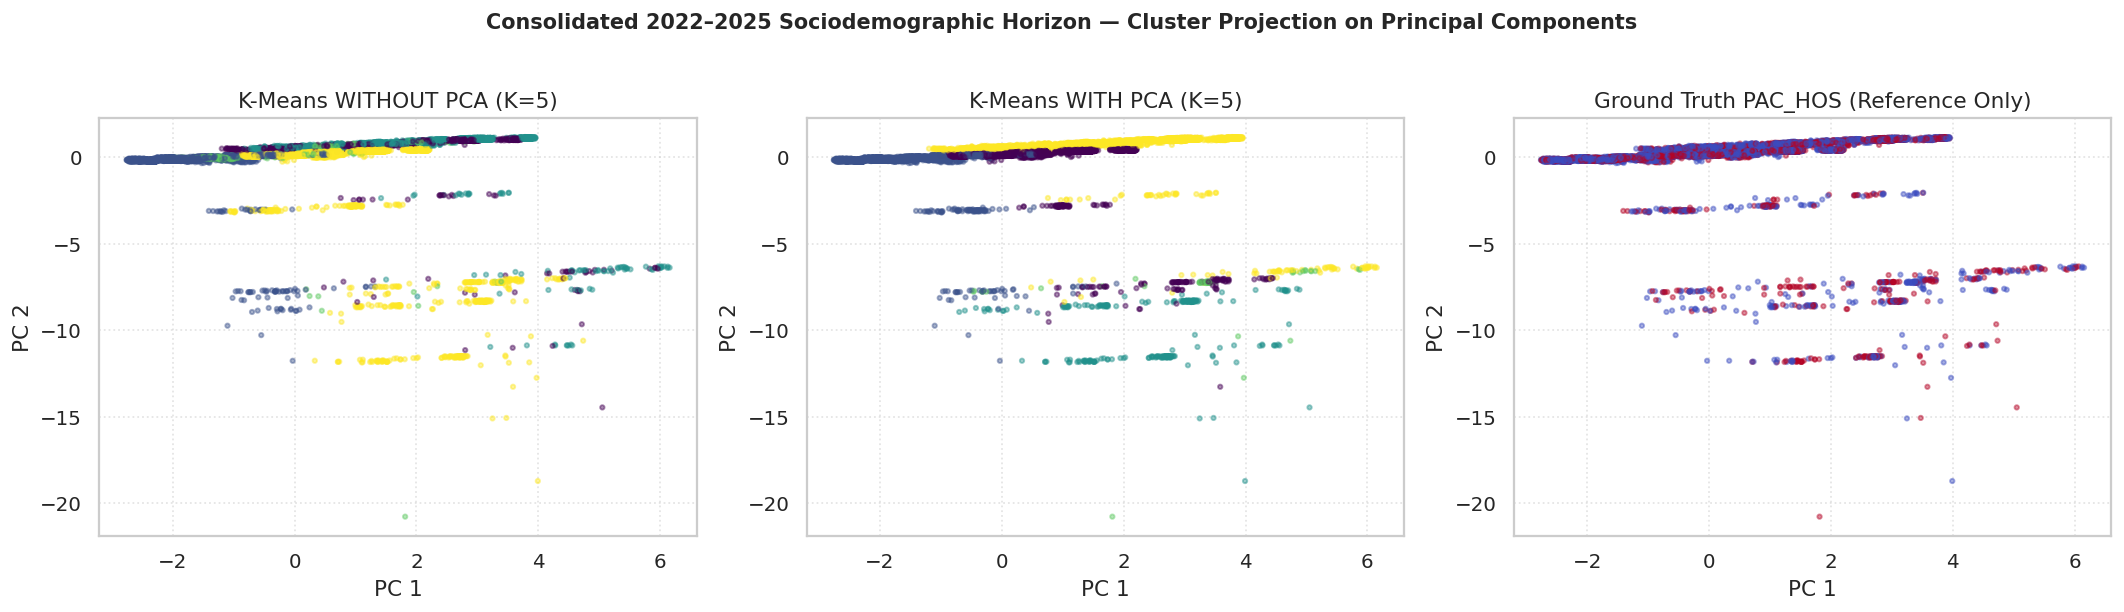

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [13]:
# ==============================================================================
# 8. EXPERIMENT 4: DIMENSIONALITY REDUCTION & UNSUPERVISED LEARNING
#    (SOCIODEMOGRAPHIC COHORTS: 2025 & CONSOLIDATED 2022-2025)
# ==============================================================================

# ------------------------------------------------------------------------------
# 8.1 Single-Year Sociodemographic Cohort (2025)
# ------------------------------------------------------------------------------
unsup_2025 = compare_kmeans_pca_vs_full(
    df_clean=working_2025,
    dataset_name="2025 Sociodemographic Cohort",
    variance_threshold=0.90,
    k_range=range(2, 10),
    fixed_k=None,
)

bench_algos_2025 = compare_clustering_algorithms(
    x_pca_2d=unsup_2025["x_pca_2d"],
    y_true=unsup_2025["y_true"],
    dataset_name="2025 Sociodemographic Cohort",
    n_clusters=3,
    sample_size=2500,
    dbscan_eps=0.5,
    dbscan_min_samples=15,
)

# ------------------------------------------------------------------------------
# 8.2 Consolidated Multi-Year Sociodemographic Horizon (2022–2025)
# ------------------------------------------------------------------------------
tagged_annual_dfs = []
for yr, df_yr in clean_annual_datasets.items():
    temp_df = df_yr.copy()
    temp_df["YEAR"] = int(yr)
    tagged_annual_dfs.append(temp_df)

working_2022_2025_unsup = pd.concat(tagged_annual_dfs, ignore_index=True)

unsup_2022_2025 = compare_kmeans_pca_vs_full(
    df_clean=working_2022_2025_unsup,
    dataset_name="Consolidated 2022–2025 Sociodemographic Horizon",
    variance_threshold=0.90,
    k_range=range(2, 10),
    fixed_k=None,
)

# **Section 9: Experiment 5 — Dimensionality Reduction and Unsupervised Clustering (Clinical Symptom Cohort)**

=== DIMENSIONALITY REDUCTION (PCA vs. t-SNE): CLINICAL SYMPTOMS COHORT ===
• Original dimensions: 28
• Variance explained by first 2 PCs: 15.36%
• Components for >=85% variance: 21 (85.56%)


,Top PC1 Feature,PC1 Loading,Top PC2 Feature,PC2 Loading
0,hipotermia,0.413,REGIME_CONTRIBUTORY,0.679
1,aum_hemato,0.348,REGIME_SUBSIDIZED,-0.584
2,acum_liquievento,0.345,REGIME_UNINSURED,-0.224
3,hepatomeg,0.327,artralgia,0.201
4,hipotensio,0.320,AGE_YEARS,0.151


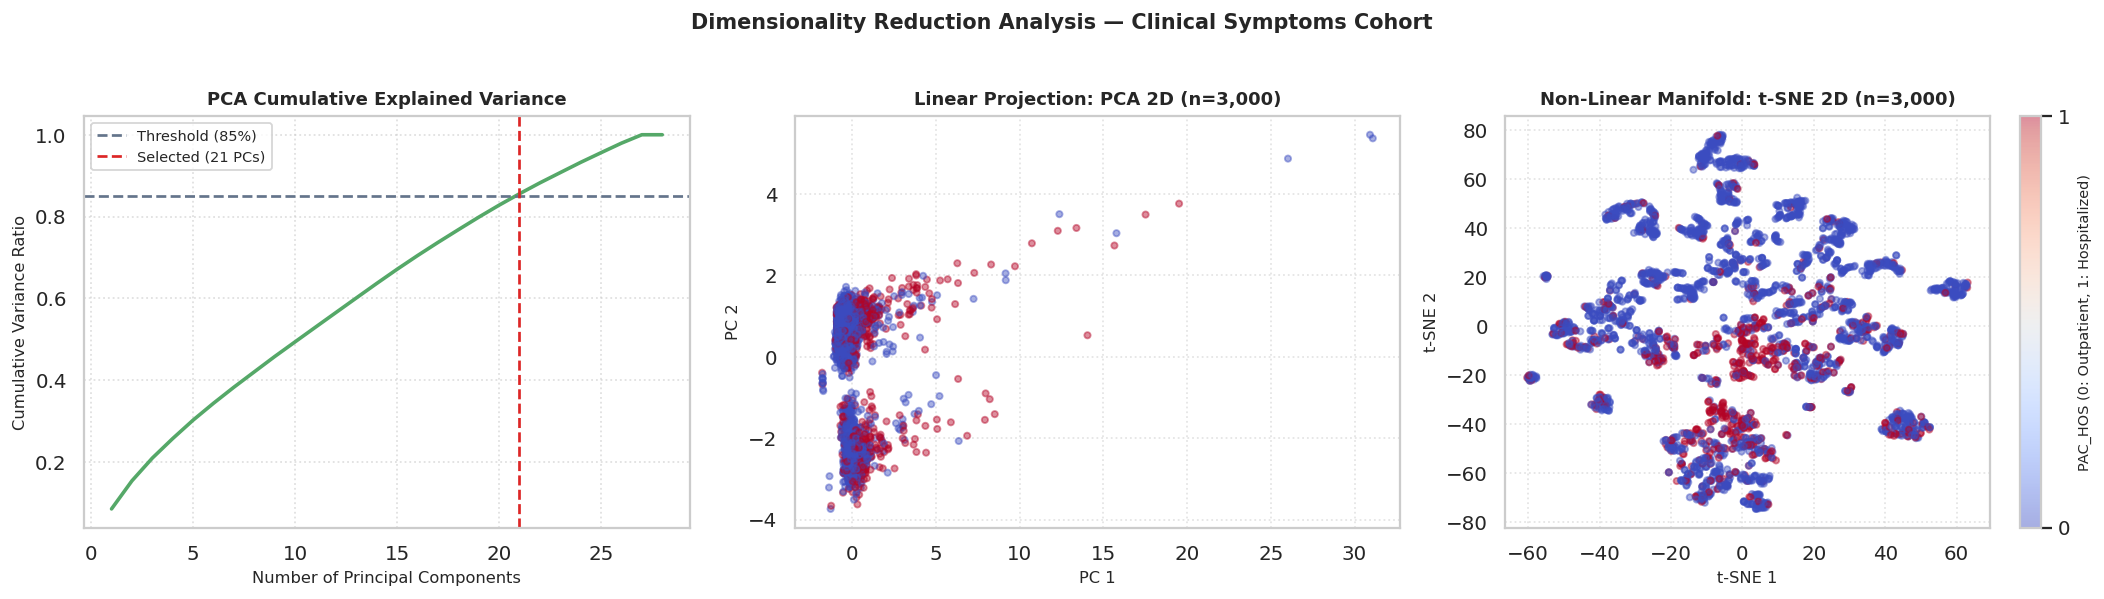


• Selected optimal K = 3 (manually fixed)


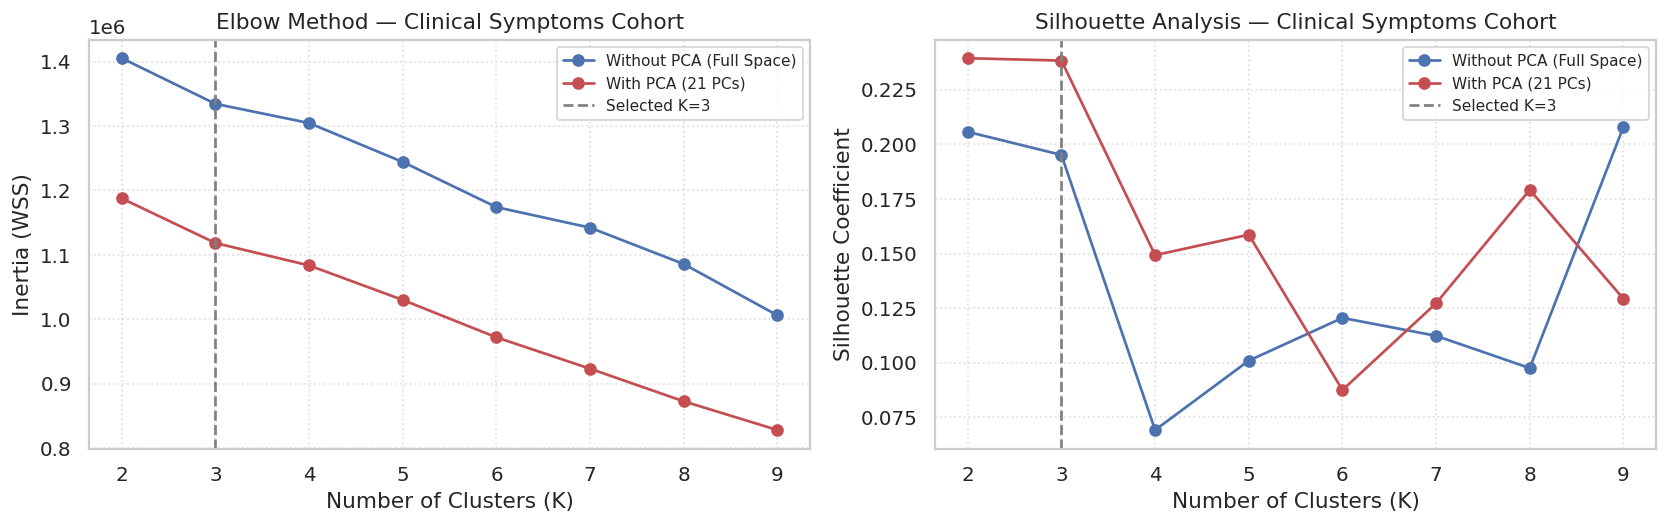


• Agreement between Full vs. PCA clusters (Adjusted Rand Index): 0.8103


,K-Means (Without PCA),K-Means (With PCA)
Dimensions,28.0000,21.0000
Clusters (K),3.0000,3.0000
Silhouette (Native Space),0.1885,0.2341
Training Time (s),0.5705,0.4525


Baseline Hospitalization Rate: 0.2097

--- Cluster Clinical Profile: WITHOUT PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,5352,0.0995,0.6969,33.6469,5.0400
1,12734,0.2366,0.2322,28.1235,7.6932
2,35726,0.6639,0.1287,31.3297,5.7113


--- Cluster Clinical Profile: WITH PCA ---


,Cases,Share_of_Total,Hospitalization_Rate,Mean_Age,Mean_Delta_T
Cluster,,,,,
0,2577,0.0479,0.5821,30.4926,5.0698
1,13183,0.2450,0.2622,28.6115,7.6147
2,38052,0.7071,0.1663,31.5811,5.6641


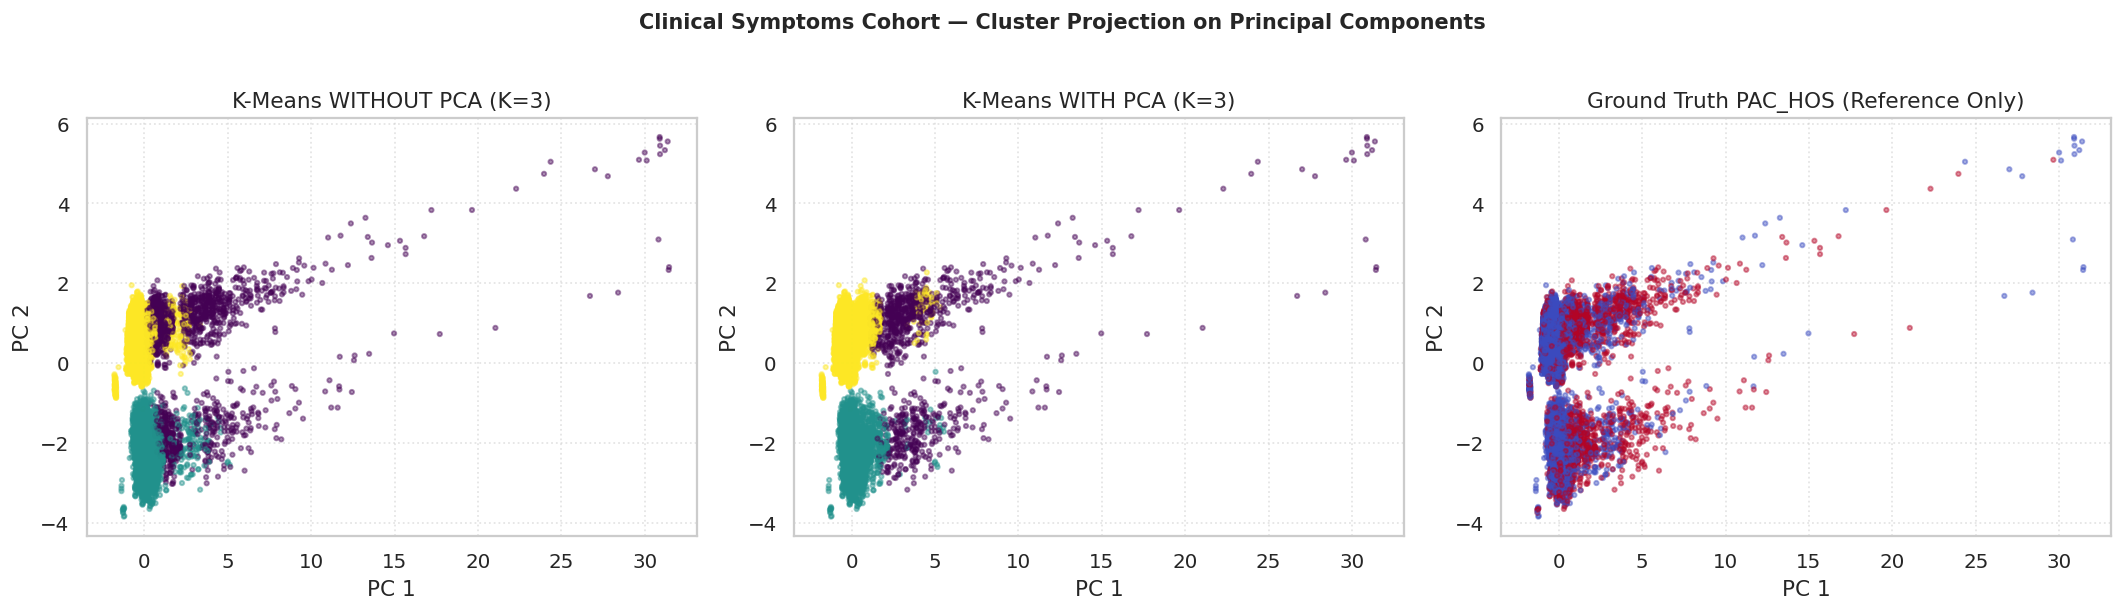

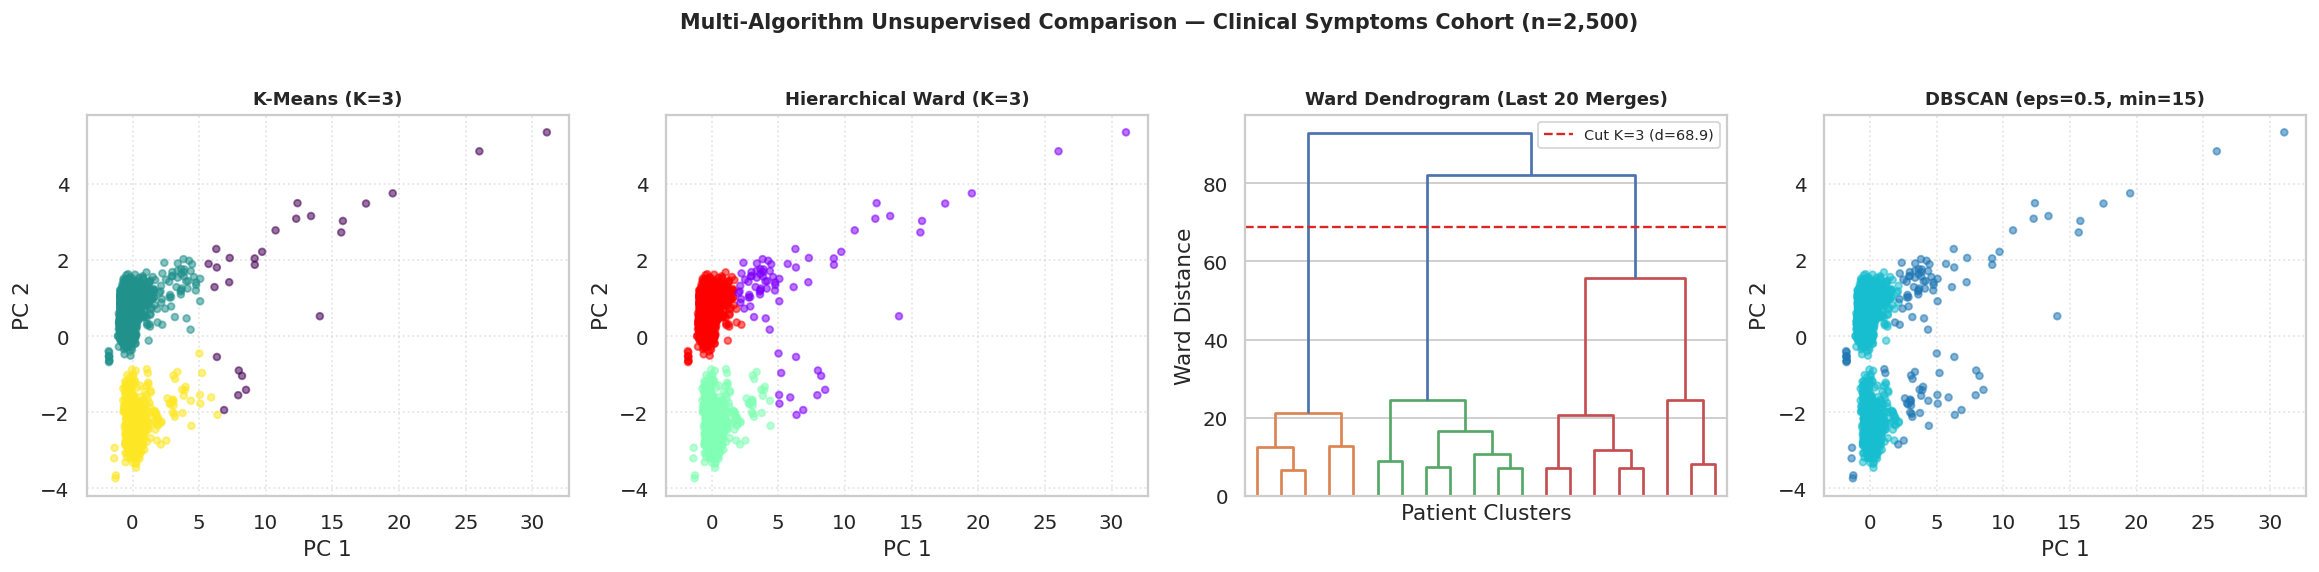


=== UNSUPERVISED ALGORITHMS BENCHMARK (CLINICAL SYMPTOMS COHORT) ===


,Clusters Found,Noise / Outliers (%),Silhouette Score,ARI vs. PAC_HOS
Algorithm,,,,
K-Means (K=3),3,0.00,0.7033,0.0768
Agglomerative Ward (K=3),3,0.00,0.7183,0.1062
DBSCAN (eps=0.5),1,4.48,N/A,0.1036



--- Hospitalization Rate (%) by Hierarchical Cluster ---


,Outpatient (%),Hospitalized (%)
Ward Cluster,,
0,33.33,66.67
1,71.38,28.62
2,83.71,16.29



--- Hospitalization Rate (%) by DBSCAN Cluster (-1 = Noise/Outliers) ---


,Outpatient (%),Hospitalized (%)
DBSCAN Cluster,,
-1,41.96,58.04
0,80.78,19.22


In [14]:
# ==============================================================================
# 9. EXPERIMENT 5: DIMENSIONALITY REDUCTION & UNSUPERVISED CLUSTERING
#    (CLINICAL SYMPTOMS & WARNING SIGNS COHORT)
# ==============================================================================

# ------------------------------------------------------------------------------
# 9.1 Unsupervised Dimensionality Reduction & K-Means (Without vs. With PCA)
# ------------------------------------------------------------------------------
unsup_symptoms = compare_kmeans_pca_vs_full(
    df_clean=working_symptoms,
    dataset_name="Clinical Symptoms Cohort",
    variance_threshold=0.85,
    k_range=range(2, 10),
    fixed_k=3,
)

# ------------------------------------------------------------------------------
# 9.2 Multi-Algorithm Clustering Benchmark (K-Means vs. Ward vs. DBSCAN)
# ------------------------------------------------------------------------------
bench_algos_symptoms = compare_clustering_algorithms(
    x_pca_2d=unsup_symptoms["x_pca_2d"],
    y_true=unsup_symptoms["y_true"],
    dataset_name="Clinical Symptoms Cohort",
    n_clusters=3,
    sample_size=2500,
    dbscan_eps=0.5,
    dbscan_min_samples=15,
)